# 헤어살롱 본점 — 날씨와 취소 분석 (04)

분석 기간 **2025-01-01 ~ 2026-08-23**. 예약 원천은 `data/processed/*.parquet`,
기상 원천은 `data/external/weather/OBS_ASOS_DD_20260901171820.csv` (기상자료개방포털 종관기상관측 ASOS 일자료).
**원본 엑셀은 다시 파싱하지 않는다.**

---

## 01~03번과 공유하는 규칙

1. **시간대·요일 분석은 `use_dt`(이용일시) 기준.** `done_dt`(이용완료일시)는 시술 종료가 아니라 정산 배치 시각이라
   오전 9~10시에 1,653건이 몰려 있다. 이 노트북에서는 `done_dt`를 **한 번도 쓰지 않는다.**
2. **`reservations` 와 `hands_all` 을 concat 하지 않는다.** 이 노트북은 `hands_all` 을 아예 로드하지 않는다.
3. **고객 식별은 `cust_key`, 금액은 `paid`(실결제금액, 예약 단위).**
4. **시술 대분류는 `data/processed/menu_category.csv` 단일 기준.** 대표 시술 우선순위도 01~03번과 동일.
5. **표본 30건 미만은 `⚠소표본` 으로 표기.**

§0-3 의 대조 게이트가 01~03번 값과 일치하지 않으면 **assert 로 실행을 멈춘다.**

---

## 이 노트북이 새로 내리는 정의 판단

| # | 쟁점 | 이 노트북의 정의 |
|---|---|---|
| §0-5 | 기상 결측 | 기상청은 "안 왔음"을 **공란**으로 내보낸다. 강수·적설은 `fillna(0)`. 기온·풍속·습도는 결측이 0건이라 손대지 않는다 |
| §0-6 | 강수구분 | 무강수 `0` / 약 `0.1~5` / 중 `5 초과~20` / 강 `20 초과` (mm) |
| §0-6 | 폭염 | 최고기온 **33℃ 이상** (`>=`). `>` 로 하면 42일이 된다 |
| §0-6 | 한파 | 최저기온 **−12℃ 이하** |
| §0-6 | 적설 | 일 최심신적설 **> 0** |
| §0-6 | 강풍 | 최대풍속이 **상위 10% 분위 초과** |
| §0-6 | 소나기 | `1시간 최다강수량 ÷ 일강수량 >= 0.5`. **일강수량 5mm 이상인 날에만 정의** (§2-d 참조) |
| §1 | 경로 (가) | `use_dt` 의 **날짜**에 그날 날씨를 붙임. 분모 = 그날 방문 예정이던 전체 예약 |
| §1 | 경로 (나) | `cancel_dt` 의 **날짜**에 그날 날씨를 붙임. 분모 = 그날 살아 있던 예약(위험집합) |
| §1 | 위험집합 | `req_dt.date <= d <= min(use_dt, cancel_dt).date` — **양끝 포함** |
| §4 | 자리 회복 불가 | `gap_h = (use_dt − cancel_dt) 시간` 이 **2 이하** (음수 포함). 02·03번의 315건과 같은 정의 |

---

## ⚠️ 관측 지점의 한계 — 리포트에 그대로 옮길 문장

> 이 분석이 쓴 날씨는 **기상청 서울 108 지점(서울 도심)** 관측값이다.
> 매장이 있는 인근 상권과는 직선거리로 약 10km 떨어져 있다.
> 하루 단위 기온·강수 유무처럼 넓은 범위에 걸친 값은 두 지역이 거의 같지만,
> **여름 국지성 소나기는 한쪽에만 쏟아지는 일이 흔하다.**
> 따라서 "비가 온 날"의 일부는 매장 인근에서는 비가 오지 않았을 수 있고,
> 그 반대도 있다. 이 오차는 날씨의 영향을 **실제보다 작게** 보이게 만드는 방향으로 작용한다.

In [1]:
# ── 0. 환경 설정 ──────────────────────────────────────────────────────────────
import sys, os, re, platform, warnings, subprocess
from pathlib import Path

import pandas as pd, numpy as np
import matplotlib, matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from IPython.display import display, Markdown
from IPython import get_ipython

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 200)

# ── 통계 패키지 (없으면 층화 비교로 대체) ────────────────────────────────────
# ⚠️ Python 3.13 + pandas 3.x + numpy 2.x 조합이라 휠 호환이 안 맞을 수 있다.
#    설치가 안 되면 HAS_SM=False 로 두고 §3-e 로지스틱 회귀 셀을 건너뛴다.
#    건너뛴 사실은 §7 판정표에 명시된다.
try:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    HAS_SM = True
except Exception as e:
    HAS_SM = False
    print("statsmodels 없음 →", type(e).__name__, "· §3-e 로지스틱 회귀는 건너뛰고 층화 비교로 대체한다")

try:
    import scipy
    from scipy import stats
    HAS_SP = True
except Exception as e:
    HAS_SP = False
    print("scipy 없음 →", type(e).__name__, "· 카이제곱 검정은 건너뛴다")

# ── 표 정렬 교정 (01~03번과 동일) ────────────────────────────────────────────
# pandas 기본 HTML 표는 헤더 행에만 text-align:right 를 넣고 데이터 셀(td)은 왼쪽에 둔다.
# 한글 컬럼명처럼 길어지면 "컬럼이 한 칸 밀린" 것처럼 보이므로 인라인 style 을 직접 박는다.
_PAD = "padding:3px 10px; white-space:nowrap;"


def _numlike(col):
    if pd.api.types.is_numeric_dtype(col):
        return True
    v = col.dropna().astype(str)
    if len(v) == 0:
        return False
    return bool(v.str.fullmatch(r"[\d,.\-+%]+").mean() > 0.7)


def _aligned_html(obj):
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj
    aligns = ["right" if _numlike(df[c]) else "left" for c in df.columns]
    html = df.to_html(na_rep="")
    head, sep, body = html.partition("<tbody>")
    if not sep:
        return html
    head = head.replace('<tr style="text-align: right;">', "<tr>")

    def _head_row(m):
        k = [0]
        def sub(_):
            j = k[0]; k[0] += 1
            a = "left" if j == 0 else (aligns[j - 1] if j - 1 < len(aligns) else "left")
            return f'<th style="text-align:{a}; {_PAD} background:#f2f2f2;">'
        return re.sub(r"<th>", sub, m.group(0))

    def _body_row(m):
        row = re.sub(r"<th>", f'<th style="text-align:left; {_PAD}">', m.group(0))
        k = [0]
        def sub(_):
            j = k[0]; k[0] += 1
            return f'<td style="text-align:{aligns[j] if j < len(aligns) else "right"}; {_PAD}">'
        return re.sub(r"<td>", sub, row)

    head = re.sub(r"<tr>.*?</tr>", _head_row, head, flags=re.S)
    body = re.sub(r"<tr>.*?</tr>", _body_row, body, flags=re.S)
    return head + sep + body


_ip = get_ipython()
if _ip is not None:
    _f = _ip.display_formatter.formatters["text/html"]
    _f.for_type(pd.DataFrame, _aligned_html)
    _f.for_type(pd.Series, _aligned_html)


def tbl(df, caption=None):
    if caption:
        display(Markdown(f"**{caption}**"))
    display(df)

def pct(x, nd=2):     return f"{x*100:.{nd}f}%"
def won(x):           return f"{x:,.0f}"
def small(n, thr=30): return "⚠소표본" if n < thr else ""

## 0-1. 한글 폰트

폰트를 먼저 잡지 않으면 이후 **모든 그래프의 한글이 네모(tofu)로 깨진다.**
OS를 감지해 설치된 한글 폰트를 찾고, 없으면 나눔고딕을 설치한 뒤 matplotlib 폰트 캐시를 새로 만든다.
`axes.unicode_minus = False` 도 함께 끈다 (음수 부호가 깨지는 것 방지).

In [2]:
# ── 0-1. 한글 폰트 설정 (01~03번과 동일) ─────────────────────────────────────
CANDIDATES = {
    "Windows": ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "Noto Sans KR", "Gulim", "Batang"],
    "Darwin":  ["AppleGothic", "Apple SD Gothic Neo", "NanumGothic", "Noto Sans KR"],
    "Linux":   ["NanumGothic", "NanumBarunGothic", "Noto Sans CJK KR", "Noto Sans KR", "UnDotum"],
}

def _installed():
    return {f.name for f in fm.fontManager.ttflist}

def _rebuild_font_cache():
    try:
        fm._load_fontmanager(try_read_cache=False)   # mpl >= 3.5
        return True
    except Exception:
        pass
    try:
        fm._rebuild()
        return True
    except Exception:
        return False

def _try_install_nanum():
    system = platform.system()
    try:
        if system == "Linux":
            subprocess.run(["apt-get", "install", "-y", "fonts-nanum"], check=False,
                           stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=300)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "koreanize-matplotlib"],
                       check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=300)
        import koreanize_matplotlib  # noqa: F401
    except Exception as e:
        print("  나눔고딕 자동 설치 실패:", type(e).__name__, e)
    _rebuild_font_cache()

_avail = _installed()
_want  = CANDIDATES.get(platform.system(), CANDIDATES["Linux"])
KFONT  = next((f for f in _want if f in _avail), None)

if KFONT is None:
    print("설치된 한글 폰트를 찾지 못했다 → 나눔고딕 설치 시도")
    _try_install_nanum()
    _avail = _installed()
    KFONT  = next((f for f in _want if f in _avail), None)

if KFONT is None:
    raise RuntimeError(
        "한글 폰트를 확보하지 못했다. 수동 설치 후 커널을 재시작할 것.\n"
        "  Linux : apt-get install -y fonts-nanum\n"
        "  기타   : pip install koreanize-matplotlib"
    )

sns.set_theme(style="whitegrid", font=KFONT, rc={"axes.unicode_minus": False})
# seaborn 이 rcParams 를 통째로 덮어쓰므로 폰트 설정은 반드시 그 뒤에 다시 적용한다
plt.rcParams["font.family"]        = KFONT
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"]         = 110
plt.rcParams["savefig.bbox"]       = "tight"
plt.rcParams["axes.grid"]          = True
plt.rcParams["grid.alpha"]         = 0.3

# 강조/회색 팔레트 — 강조할 것만 진한 색, 나머지는 회색 (프롬프트 규칙)
CLR_HI   = "#c0392b"   # 강조
CLR_HI2  = "#2c6fbb"   # 보조 강조
CLR_GRAY = "#b0b0b0"   # 나머지
CLR_LINE = "#444444"

### 한글 폰트 설정 — 렌더링 점검 그래프는 개발 환경 확인용이라 공개본에서 뺐다

In [3]:
# 한글 폰트 렌더링 점검 그래프 — 개발 환경 확인용이라 공개본에서 뺐다 (폰트 설정은 위 셀)

## 0-2. 예약 데이터 로딩

`hands_all` 은 **의도적으로 로드하지 않는다** (concat 금지 규칙).

| 객체 | 그레인 | 설명 |
|---|---|---|
| `R` | 예약번호 1행 | `reservations.parquet` — 예약 마스터 |
| `L` | (예약번호, 메뉴) | `menu_lines.parquet` — 옵션 라인 |
| `CATMAP` | 메뉴 1행 | `menu_category.csv` — 시술 대분류 단일 기준 |

In [4]:
# ── 0-2. 로딩 + 01~03번 헬퍼 (로직 동일) ─────────────────────────────────────
PROC = Path(os.environ.get("SALON_OUT", "../data/processed"))
if not PROC.exists():
    PROC = Path("data/processed")           # 노트북을 프로젝트 루트에서 열었을 때
assert PROC.exists(), f"processed 폴더를 찾지 못했다: {PROC.resolve()}"

R      = pd.read_parquet(PROC / "reservations.parquet")
L      = pd.read_parquet(PROC / "menu_lines.parquet")
CATMAP = pd.read_csv(PROC / "menu_category.csv", encoding="utf-8-sig")

# --- 01번 §0-4 / 02번 §0-4 / 03번 §0-4 와 동일 ---
PRIORITY = ["탈색", "펌", "염색", "컷", "클리닉", "스타일링", "기타", "확인필요"]
CORE5    = ["탈색", "펌", "염색", "컷", "클리닉"]
EXCLUDE  = ["비시술"]

_cat_of  = CATMAP.set_index("menu")["category"].to_dict()
_free_of = CATMAP.set_index("menu")["is_free"].to_dict()

LX = L.copy()
LX["category"] = LX.menu.map(_cat_of)
LX["is_free"]  = LX.menu.map(_free_of).astype(int)
assert LX.category.notna().all(), "카테고리 매핑 실패 라인 존재"
LX = LX[~LX.category.isin(EXCLUDE)].copy()

_p = {c: i for i, c in enumerate(PRIORITY)}
_rep = (LX.assign(_o=LX.category.map(_p))
          .sort_values(["예약번호", "_o"])
          .drop_duplicates("예약번호")
          .set_index("예약번호")["category"])
R["rep_cat"] = R.예약번호.map(_rep)

DOW_KO      = ["월", "화", "수", "목", "금", "토", "일"]
LEAD_EDGES  = [-np.inf, 6, 24, 72, 168, 336, np.inf]
LEAD_LABELS = ["6시간 미만", "6~24시간", "1~3일", "3~7일", "1~2주", "2주 이상"]

R["dow_ko"]   = R.dow.map(lambda i: DOW_KO[i])
R["lead_bin"] = pd.cut(R.lead_h, bins=LEAD_EDGES, labels=LEAD_LABELS, right=False)
R["date"]     = R.use_dt.dt.normalize()          # 방문 예정일 (경로 가)
R["cdate"]    = R.cancel_dt.dt.normalize()       # 취소 실행일 (경로 나)
R["rdate"]    = R.req_dt.dt.normalize()          # 예약 신청일

DONE = R[R.status == "이용완료"].copy()
CANC = R[R.status == "취소"].copy()
CANC["gap_h"] = (CANC.use_dt - CANC.cancel_dt).dt.total_seconds() / 3600

N_MONTHS = (R.ym.max() - R.ym.min()).n + 1

print(f"reservations  {R.shape[0]:>6,}행 x {R.shape[1]}컬럼   use_dt {R.use_dt.min():%Y-%m-%d} ~ {R.use_dt.max():%Y-%m-%d}")
print(f"menu_lines    {L.shape[0]:>6,}행 (비시술 제외 {len(LX):,}행)")
print(f"기간 {N_MONTHS}개월 · 방문예정일 고유 {R.date.nunique()}일")
print()
print("status 분포:", R.status.value_counts().to_dict())

reservations   4,281행 x 35컬럼   use_dt 2025-01-01 ~ 2026-08-23
menu_lines     7,165행 (비시술 제외 7,162행)
기간 20개월 · 방문예정일 고유 596일

status 분포: {'이용완료': 2732, '취소': 1542, '확정': 6, '노쇼': 1}


## 0-3. 01~03번 대조 게이트

**이 노트북의 기반 수치가 01~03번과 같은지 먼저 확인한다.**
하나라도 다르면 그건 버그이므로 `assert` 로 실행을 멈추고, 원인을 규명하기 전에는 진행하지 않는다.
(프롬프트 규칙: "01~03번과 같은 지표가 다르게 나오면 멈추고 원인부터 보고해라")

In [5]:
# ── 0-3. 대조 게이트 ─────────────────────────────────────────────────────────
_lb = (R.groupby("lead_bin", observed=False)
         .agg(n=("예약번호", "size"), c=("status", lambda s: int((s == "취소").sum()))))
_lb["r"] = _lb.c / _lb.n * 100

# 02·03번 "자리 회복 불가" 315건 = 방문시각 지난 뒤(gap_h<0) 133 + 방문 2h 이내 182
_irr_late = int((CANC.gap_h < 0).sum())
_irr_2h   = int(((CANC.gap_h >= 0) & (CANC.gap_h <= 2)).sum())

# 03번 기간 구분 A = 2025-01~2025-10, B = 2025-11~2026-08
_PB = pd.Period("2025-11", "M")
R["period"] = np.where(R.ym < _PB, "A(2025-01~10)", "B(2025-11~2026-08)")
_pr = R.groupby("period").status.agg(n="size", c=lambda s: int((s == "취소").sum()))
_pr["r"] = _pr.c / _pr.n * 100

GATE = [
    ("전체 예약 건수",           len(R),                                        4281),
    ("완료 건수",                len(DONE),                                     2732),
    ("취소 건수",                len(CANC),                                     1542),
    ("확정 건수",                int((R.status == "확정").sum()),                  6),
    ("노쇼 건수",                int((R.status == "노쇼").sum()),                  1),
    ("완료 총매출",              int(DONE.paid.sum()),                    308_975_650),
    ("객단가 중앙값",            float(DONE.paid.median()),                  100_000.0),
    ("표면 취소율(%)",           round((R.status == "취소").mean()*100, 2),      36.02),
    ("메뉴 라인(비시술 제외)",    len(LX),                                       7162),
    ("대표시술 미부여",          int(R.rep_cat.isna().sum()),                       0),
    ("리드타임취소율 6h미만(%)",  round(float(_lb.loc["6시간 미만", "r"]), 2),    14.87),
    ("리드타임취소율 6~24h(%)",  round(float(_lb.loc["6~24시간", "r"]), 2),      27.22),
    ("리드타임취소율 1~3일(%)",   round(float(_lb.loc["1~3일", "r"]), 2),         36.10),
    ("리드타임취소율 3~7일(%)",   round(float(_lb.loc["3~7일", "r"]), 2),         44.61),
    ("리드타임취소율 1~2주(%)",   round(float(_lb.loc["1~2주", "r"]), 2),         55.60),
    ("리드타임취소율 2주+(%)",    round(float(_lb.loc["2주 이상", "r"]), 2),      69.44),
    ("자리회복불가 — 방문시각 이후", _irr_late,                                   133),
    ("자리회복불가 — 2시간 이내",   _irr_2h,                                     182),
    ("자리회복불가 합계",          _irr_late + _irr_2h,                          315),
    ("기간A 취소율(%)",          round(float(_pr.loc["A(2025-01~10)", "r"]), 2), 32.65),
    ("기간B 취소율(%)",          round(float(_pr.loc["B(2025-11~2026-08)", "r"]), 2), 38.49),
]
_g = pd.DataFrame(GATE, columns=["지표", "이번 노트북", "01~03번 값"])
_g["일치"] = np.where(_g["이번 노트북"] == _g["01~03번 값"], "OK", "★불일치")
tbl(_g, "0-3 01~03번 대조 게이트")

_bad = _g[_g.일치 != "OK"]
assert _bad.empty, f"01~03번과 값이 다르다. 원인 규명 전까지 진행 불가:\n{_bad.to_string()}"
print(f"대조 {len(_g)}개 항목 전부 일치. 이 노트북은 01~03번과 같은 기반 위에 있다.")

**0-3 01~03번 대조 게이트**

,지표,이번 노트북,01~03번 값,일치
0,전체 예약 건수,4.281000e+03,4.281000e+03,OK
1,완료 건수,2.732000e+03,2.732000e+03,OK
2,취소 건수,1.542000e+03,1.542000e+03,OK
3,확정 건수,6.000000e+00,6.000000e+00,OK
4,노쇼 건수,1.000000e+00,1.000000e+00,OK
5,완료 총매출,3.089756e+08,3.089756e+08,OK
6,객단가 중앙값,1.000000e+05,1.000000e+05,OK
7,표면 취소율(%),3.602000e+01,3.602000e+01,OK
8,메뉴 라인(비시술 제외),7.162000e+03,7.162000e+03,OK
9,대표시술 미부여,0.000000e+00,0.000000e+00,OK


대조 21개 항목 전부 일치. 이 노트북은 01~03번과 같은 기반 위에 있다.


## 0-4. 기상 데이터 로드

**파일**: `data/external/weather/OBS_ASOS_DD_20260901171820.csv`
기상자료개방포털 **종관기상관측(ASOS) 일자료**, **서울 108 지점 단일**, 인코딩 **cp949**.

### ⚠️ 컬럼명에 불규칙한 공백이 들어 있다

`일 최심신적설(cm)`, `합계 일조시간(hr)`, `평균 상대습도(%)`, `1시간 최다강수량(mm)` 처럼
띄어쓰기가 규칙적이지 않다. **`일최심신적설` 로 찾으면 `KeyError` 가 난다.**
그래서 아래에서는 **위치 인덱스로 잡아 상수에 담고**, 실제 문자열도 함께 출력해 대조한다.

| 인덱스 | 컬럼 |
|---|---|
| 13 | 일강수량(mm) |
| 33 | 일 최심신적설(cm) |

### 사용할 컬럼 / 안 쓰는 컬럼

**분석에 쓴다** — 평균·최저·최고기온, 일강수량, 1시간 최다강수량, 10분 최다 강수량,
강수 계속시간, 평균·최대 풍속, 평균 상대습도, 합계 일조시간, 일 최심신적설.

**안 쓴다** — `~시각(hhmi)` 12개, 풍향(16방위), 일사량, 증기압, 이슬점온도, 가조시간, 풍정합.

**raw 프레임 `WRAW` 는 38컬럼 그대로 보존**하고, 분석용 뷰 `WX` 를 따로 만든다.

In [6]:
# ── 0-4. 기상 데이터 로드 + 사양 검증 ────────────────────────────────────────
WPATH = Path(os.environ.get("SALON_WEATHER",
             "../data/external/weather/OBS_ASOS_DD_20260901171820.csv"))
if not WPATH.exists():
    WPATH = Path("data/external/weather/OBS_ASOS_DD_20260901171820.csv")
assert WPATH.exists(), f"기상 파일을 찾지 못했다: {WPATH.resolve()}"

WRAW = pd.read_csv(WPATH, encoding="cp949")          # ⚠️ cp949. utf-8 로 읽으면 UnicodeDecodeError

# --- 사전점검에서 통과 확인된 사양 ---
assert WRAW.shape == (600, 38), f"shape 가 (600, 38) 이 아니다: {WRAW.shape}"
assert WRAW["지점"].nunique() == 1 and WRAW["지점"].iloc[0] == 108, "서울 108 단일 지점이 아니다"
WRAW["일시"] = pd.to_datetime(WRAW["일시"])
assert WRAW["일시"].min().date().isoformat() == "2025-01-01"
assert WRAW["일시"].max().date().isoformat() == "2026-08-23"
assert WRAW["일시"].duplicated().sum() == 0, "일시 중복 존재"
assert len(set(pd.date_range("2025-01-01", "2026-08-23")) - set(WRAW["일시"])) == 0, "빠진 날짜 존재"

# --- 컬럼명은 위치 인덱스로 잡는다 (공백이 불규칙해 문자열 하드코딩이 위험) ---
# ⚠️ 변수명을 C 로 두지 말 것 — patsy 의 C() 를 가려서 §3-e 회귀가 TypeError 로 죽는다.
WCOL = list(WRAW.columns)
K_TAVG, K_TMIN, K_TMAX = WCOL[3],  WCOL[4],  WCOL[6]
K_RDUR, K_R10,  K_R1H  = WCOL[8],  WCOL[9],  WCOL[11]
K_RAIN                 = WCOL[13]
K_WMAX, K_WAVG         = WCOL[17], WCOL[20]
K_HUMID                = WCOL[26]
K_SUN                  = WCOL[29]
K_SNOW                 = WCOL[33]

_keys = pd.DataFrame([
    ("K_TAVG",  3, K_TAVG), ("K_TMIN",  4, K_TMIN), ("K_TMAX",  6, K_TMAX),
    ("K_RDUR",  8, K_RDUR), ("K_R10",   9, K_R10),  ("K_R1H",  11, K_R1H),
    ("K_RAIN", 13, K_RAIN), ("K_WMAX", 17, K_WMAX), ("K_WAVG", 20, K_WAVG),
    ("K_HUMID",26, K_HUMID),("K_SUN",  29, K_SUN),  ("K_SNOW", 33, K_SNOW),
], columns=["상수", "인덱스", "실제 컬럼명"])
_keys["결측"] = [int(WRAW[k].isna().sum()) for k in _keys["실제 컬럼명"]]
tbl(_keys, "0-4 위치 인덱스로 고정한 컬럼 — 실제 문자열과 결측 수")

assert K_RAIN == "일강수량(mm)",        f"인덱스 13 이 일강수량이 아니다: {K_RAIN!r}"
assert K_SNOW == "일 최심신적설(cm)",   f"인덱스 33 이 일 최심신적설이 아니다: {K_SNOW!r}"

print(f"\nWRAW  {WRAW.shape[0]}행 x {WRAW.shape[1]}컬럼  ·  {WRAW['일시'].min():%Y-%m-%d} ~ {WRAW['일시'].max():%Y-%m-%d}")
print(f"지점 {WRAW['지점'].iloc[0]} ({WRAW['지점명'].iloc[0]}) 단일 · 날짜 결손 0일 · 중복 0일")

**0-4 위치 인덱스로 고정한 컬럼 — 실제 문자열과 결측 수**

,상수,인덱스,실제 컬럼명,결측
0,K_TAVG,3,평균기온(°C),0
1,K_TMIN,4,최저기온(°C),0
2,K_TMAX,6,최고기온(°C),0
3,K_RDUR,8,강수 계속시간(hr),349
4,K_R10,9,10분 최다 강수량(mm),425
5,K_R1H,11,1시간 최다강수량(mm),425
6,K_RAIN,13,일강수량(mm),349
7,K_WMAX,17,최대 풍속(m/s),0
8,K_WAVG,20,평균 풍속(m/s),0
9,K_HUMID,26,평균 상대습도(%),0



WRAW  600행 x 38컬럼  ·  2025-01-01 ~ 2026-08-23
지점 108 (서울) 단일 · 날짜 결손 0일 · 중복 0일


## 0-5. ⚠️ 결측 처리 — 여기서 틀리면 분석 전체가 무의미해진다

**기상청은 "안 왔음"을 공란으로 내보낸다. "모름"이 아니다.**

| 상태 | 일수 |
|---|---|
| `일강수량(mm)` 결측 | 349 |
| `일강수량(mm) == 0.0` | 70 |
| **무강수 합계** | **419** |
| 강수일 (> 0) | 181 |

`dropna()` 를 하면 표본이 251일로 쪼그라들고 **"비 온 날이 72%"** 라는 틀린 데이터가 된다.
`fillna(0)` 하되 **채우기 전후 건수를 로그로 출력**한다.

- `1시간 최다강수량(mm)` 결측 425건, `10분 최다 강수량(mm)` 결측 425건,
  `강수 계속시간(hr)` 결측 349건, `일 최심신적설(cm)` 결측 576건 → **같은 이유로 0 처리.**
- **기온·풍속·습도는 결측이 0건이므로 손대지 않는다.** `합계 일조시간(hr)` 만 결측 1건이며,
  이 컬럼은 0 으로 채우지 않고 **결측 그대로 둔다** (일조시간 0시간과 미관측은 다르다).

In [7]:
# ── 0-5. 결측 처리 — 채우기 전후를 반드시 로그로 남긴다 ──────────────────────
_rain_raw = WRAW[K_RAIN]

# 프롬프트가 준 검증 assert (사전점검 통과값)
assert _rain_raw.isna().sum() == 349 and (_rain_raw == 0).sum() == 70, (
    f"강수 결측 구조가 다르다: na={_rain_raw.isna().sum()}, zero={(_rain_raw == 0).sum()}")
assert (_rain_raw.fillna(0) > 0).sum() == 181, "강수일이 181일이 아니다"

ZERO_FILL = [K_RAIN, K_R1H, K_R10, K_RDUR, K_SNOW]   # "안 왔음" 을 뜻하는 공란
KEEP_NA   = [K_SUN]                                   # 미관측 — 0 으로 채우면 안 된다
NO_TOUCH  = [K_TAVG, K_TMIN, K_TMAX, K_WMAX, K_WAVG, K_HUMID]  # 결측 0건

_log = []
for k in ZERO_FILL + KEEP_NA + NO_TOUCH:
    _log.append({
        "컬럼": k,
        "처리": "fillna(0)" if k in ZERO_FILL else ("결측 유지" if k in KEEP_NA else "손대지 않음"),
        "채우기 전 결측": int(WRAW[k].isna().sum()),
        "채우기 전 0값":  int((WRAW[k] == 0).sum()),
    })
_log = pd.DataFrame(_log)

W = WRAW.copy()
for k in ZERO_FILL:
    W[k] = W[k].fillna(0)

_log["채운 뒤 결측"] = [int(W[k].isna().sum()) for k in _log["컬럼"]]
_log["채운 뒤 0값"]  = [int((W[k] == 0).sum()) for k in _log["컬럼"]]
tbl(_log, "0-5 결측 처리 전후 — 0 으로 채운 것은 '안 왔음' 을 뜻하는 공란뿐이다")

print(f"강수: 결측 349일 + 0.0mm 70일 = 무강수 {int((W[K_RAIN] == 0).sum())}일 · "
      f"강수일 {int((W[K_RAIN] > 0).sum())}일  (합 {len(W)}일)")
print(f"만약 dropna() 를 했다면 표본은 {int(_rain_raw.notna().sum())}일로 줄고 "
      f"강수일 비율이 {(_rain_raw.fillna(0) > 0).sum() / _rain_raw.notna().sum() * 100:.1f}% 라는 "
      f"틀린 값이 나온다.  실제는 {(W[K_RAIN] > 0).mean() * 100:.1f}% 다.")
print(f"\n일조시간은 결측 {int(W[K_SUN].isna().sum())}건을 그대로 둔다 (0시간과 미관측은 다르다).")

**0-5 결측 처리 전후 — 0 으로 채운 것은 '안 왔음' 을 뜻하는 공란뿐이다**

,컬럼,처리,채우기 전 결측,채우기 전 0값,채운 뒤 결측,채운 뒤 0값
0,일강수량(mm),fillna(0),349,70,0,419
1,1시간 최다강수량(mm),fillna(0),425,42,0,467
2,10분 최다 강수량(mm),fillna(0),425,42,0,467
3,강수 계속시간(hr),fillna(0),349,0,0,349
4,일 최심신적설(cm),fillna(0),576,0,0,576
5,합계 일조시간(hr),결측 유지,1,53,1,53
6,평균기온(°C),손대지 않음,0,0,0,0
7,최저기온(°C),손대지 않음,0,3,0,3
8,최고기온(°C),손대지 않음,0,2,0,2
9,최대 풍속(m/s),손대지 않음,0,0,0,0


강수: 결측 349일 + 0.0mm 70일 = 무강수 419일 · 강수일 181일  (합 600일)
만약 dropna() 를 했다면 표본은 251일로 줄고 강수일 비율이 72.1% 라는 틀린 값이 나온다.  실제는 30.2% 다.

일조시간은 결측 1건을 그대로 둔다 (0시간과 미관측은 다르다).


## 0-6. 파생 변수 — 정의를 먼저 못박는다

| 변수 | 정의 | 기대 일수 |
|---|---|---|
| `강수구분` | 무강수 `= 0` / 약 `0 초과 ~ 5 이하` / 중 `5 초과 ~ 20 이하` / 강 `20 초과` (mm) | 419 / 99 / 48 / 34 |
| `폭염` | 최고기온 **`>= 33`** ℃ — `>` 로 하면 42일이 되니 주의 | 43 |
| `한파` | 최저기온 **`<= −12`** ℃ | 4 (표본 부족 → 사례 나열만) |
| `적설` | 일 최심신적설 **`> 0`** cm | 24 (전부 12~4월) |
| `강풍` | 최대풍속이 **상위 10% 분위 초과** | 실측으로 산출 |
| `소나기여부` | `1시간 최다강수량 ÷ 일강수량 >= 0.5` — **일강수량 5mm 이상인 날에만 정의** | §2-d 참조 |
| `전일강수량` | 하루 전 일강수량 (예보 반응 포착용) | — |
| `주말여부` | 토·일 | — |
| `계절` | 3~5 봄 / 6~8 여름 / 9~11 가을 / 12~2 겨울 | — |

**기대 일수가 안 나오면 §0-5 결측 처리가 틀린 것이다.** 아래 셀이 `assert` 로 잡는다.

### 소나기 임계값을 0.5 로, 그리고 5mm 이상인 날에만 정의한 이유

`1시간 최다강수량 ÷ 일강수량` 의 분포를 보면 **전체 강수일 181일 중 49일은 1시간 최다강수량이 결측**이다.
하루 총량이 1mm 미만인 날은 시간 단위로 기록될 만한 강수가 없어서 그렇다.
이 49일을 0 으로 채운 채 비율을 계산하면 비율이 0 이 되어 "종일 부슬비" 로 잘못 분류된다.
게다가 **7일은 `1시간 최다강수량 > 일강수량`** 이라는 물리적으로 불가능한 값이 나오는데,
전부 일강수량 0.0~1.8mm 인 미량 강수일의 반올림 아티팩트다.

그래서 **일강수량 5mm 이상(= 강수구분 '중'·'강', 82일)** 로 제한한다.
이 구간에서는 1시간 최다강수량이 69일 기록돼 있고 비율의 중앙값이 0.413 이라 0.5 가 자연스러운 분기점이다.

In [8]:
# ── 0-6. 파생 변수 ───────────────────────────────────────────────────────────
# ⚠️ 예약 테이블에도 dow / ym / hour 가 있다. merge 후 _x/_y 로 갈라지지 않도록
#    기상 파생 컬럼은 전부 wx_ 접두어를 붙인다.
RAIN_EDGES  = [-np.inf, 0, 5, 20, np.inf]
RAIN_LABELS = ["무강수", "약(0.1~5)", "중(5~20)", "강(20 초과)"]
SEASON_ORDER = ["봄", "여름", "가을", "겨울"]

def _season(m):
    return "봄" if m in (3, 4, 5) else "여름" if m in (6, 7, 8) else "가을" if m in (9, 10, 11) else "겨울"

WX = pd.DataFrame({"wx_date": W["일시"]})
WX["wx_rain"]  = W[K_RAIN]
WX["wx_r1h"]   = W[K_R1H]
WX["wx_r10"]   = W[K_R10]
WX["wx_rdur"]  = W[K_RDUR]
WX["wx_snow"]  = W[K_SNOW]
WX["wx_tavg"]  = W[K_TAVG]
WX["wx_tmin"]  = W[K_TMIN]
WX["wx_tmax"]  = W[K_TMAX]
WX["wx_wmax"]  = W[K_WMAX]
WX["wx_wavg"]  = W[K_WAVG]
WX["wx_humid"] = W[K_HUMID]
WX["wx_sun"]   = W[K_SUN]

WX["wx_rbin"]     = pd.cut(WX.wx_rain, bins=RAIN_EDGES, labels=RAIN_LABELS)
WX["wx_wet"]      = WX.wx_rain > 0
WX["wx_prevrain"] = WX.wx_rain.shift(1)                     # 하루 전 강수량
WX["wx_pbin"]     = pd.cut(WX.wx_prevrain, bins=RAIN_EDGES, labels=RAIN_LABELS)

WX["wx_heat"]  = WX.wx_tmax >= 33                            # >= 로 고정 (> 면 42일)
WX["wx_cold"]  = WX.wx_tmin <= -12
WX["wx_snowy"] = WX.wx_snow > 0
WIND_Q90       = float(WX.wx_wmax.quantile(0.90))
WX["wx_windy"] = WX.wx_wmax > WIND_Q90

# 소나기 — 일강수량 5mm 이상인 날에만 정의. 나머지는 NA (0 아님)
SHOWER_MIN_MM, SHOWER_THR = 5.0, 0.5
_ratio = np.where((WX.wx_rain >= SHOWER_MIN_MM) & (WRAW[K_R1H].notna().values),
                  WX.wx_r1h / WX.wx_rain.replace(0, np.nan), np.nan)
WX["wx_shower_ratio"] = _ratio
WX["wx_shower"]       = np.where(np.isnan(_ratio), np.nan, _ratio >= SHOWER_THR)

WX["wx_month"]   = WX.wx_date.dt.month
WX["wx_ymstr"]   = WX.wx_date.dt.to_period("M").astype(str)
WX["wx_dow"]     = WX.wx_date.dt.dayofweek
WX["wx_dow_ko"]  = WX.wx_dow.map(lambda i: DOW_KO[i])
WX["wx_weekend"] = WX.wx_dow >= 5
WX["wx_season"]  = WX.wx_month.map(_season)

# ── 기대 일수 검증 — 안 맞으면 결측 처리가 틀린 것이다 ──
_cnt = WX.wx_rbin.value_counts().reindex(RAIN_LABELS)
assert _cnt.tolist() == [419, 99, 48, 34], f"강수구분 분포가 다르다: {_cnt.to_dict()}"
assert int(WX.wx_heat.sum())  == 43, f"폭염일이 43일이 아니다: {int(WX.wx_heat.sum())}"
assert int((WX.wx_tmax > 33).sum()) == 42, "폭염 임계 확인용 (> 33 은 42일이어야 한다)"
assert int(WX.wx_cold.sum())  == 4,  f"한파일이 4일이 아니다: {int(WX.wx_cold.sum())}"
assert int(WX.wx_snowy.sum()) == 24, f"적설일이 24일이 아니다: {int(WX.wx_snowy.sum())}"

_sum = pd.DataFrame([
    {"조건": "무강수",            "일수": int(_cnt.iloc[0]), "정의": "일강수량 = 0mm (결측 349 + 0.0 기록 70)"},
    {"조건": "약(0.1~5mm)",      "일수": int(_cnt.iloc[1]), "정의": "0 < 일강수량 <= 5"},
    {"조건": "중(5~20mm)",       "일수": int(_cnt.iloc[2]), "정의": "5 < 일강수량 <= 20"},
    {"조건": "강(20mm 초과)",     "일수": int(_cnt.iloc[3]), "정의": "일강수량 > 20"},
    {"조건": "폭염",             "일수": int(WX.wx_heat.sum()),  "정의": "최고기온 >= 33℃"},
    {"조건": "한파",             "일수": int(WX.wx_cold.sum()),  "정의": "최저기온 <= −12℃"},
    {"조건": "적설",             "일수": int(WX.wx_snowy.sum()), "정의": "일 최심신적설 > 0cm"},
    {"조건": "강풍",             "일수": int(WX.wx_windy.sum()), "정의": f"최대풍속 > {WIND_Q90}m/s (상위 10% 분위 초과)"},
    {"조건": "소나기(정의 가능일)", "일수": int(WX.wx_shower.notna().sum()),
     "정의": f"일강수량 >= {SHOWER_MIN_MM:.0f}mm 이고 1시간 최다강수량 기록 있음"},
    {"조건": "  └ 그중 소나기형", "일수": int((WX.wx_shower == 1).sum()),
     "정의": f"1시간 최다 / 일강수량 >= {SHOWER_THR}"},
])
_sum["소표본"] = _sum.일수.map(lambda n: small(n))
tbl(_sum, "0-6 조건일 일수 — 30일 미만은 소표본 경고")

print(f"강풍 임계(최대풍속 상위 10% 분위): {WIND_Q90} m/s → {int(WX.wx_windy.sum())}일")
print(f"소나기 비율 분포(정의 가능 {int(WX.wx_shower.notna().sum())}일): "
      f"중앙값 {np.nanmedian(WX.wx_shower_ratio):.3f} · "
      f"25% {np.nanpercentile(WX.wx_shower_ratio.dropna(), 25):.3f} · "
      f"75% {np.nanpercentile(WX.wx_shower_ratio.dropna(), 75):.3f}")
print(f"\nWRAW 는 {WRAW.shape[1]}컬럼 그대로 보존 · 분석용 뷰 WX 는 {WX.shape[1]}컬럼")

**0-6 조건일 일수 — 30일 미만은 소표본 경고**

,조건,일수,정의,소표본
0,무강수,419,일강수량 = 0mm (결측 349 + 0.0 기록 70),
1,약(0.1~5mm),99,0 < 일강수량 <= 5,
2,중(5~20mm),48,5 < 일강수량 <= 20,
3,강(20mm 초과),34,일강수량 > 20,
4,폭염,43,최고기온 >= 33℃,
5,한파,4,최저기온 <= −12℃,⚠소표본
6,적설,24,일 최심신적설 > 0cm,⚠소표본
7,강풍,55,최대풍속 > 6.2m/s (상위 10% 분위 초과),
8,소나기(정의 가능일),69,일강수량 >= 5mm 이고 1시간 최다강수량 기록 있음,
9,└ 그중 소나기형,21,1시간 최다 / 일강수량 >= 0.5,⚠소표본


강풍 임계(최대풍속 상위 10% 분위): 6.2 m/s → 55일
소나기 비율 분포(정의 가능 69일): 중앙값 0.413 · 25% 0.277 · 75% 0.527

WRAW 는 38컬럼 그대로 보존 · 분석용 뷰 WX 는 29컬럼


---

# ① 결합을 두 번 한다 — 이 분석의 핵심 설계

날씨가 취소에 영향을 주는 경로는 **두 개**이고, 둘은 서로 다른 개입을 뜻한다.

### (가) 방문 예정일 날씨
`use_dt` 의 **날짜**에 그날의 날씨를 붙인다. 해석은 **"그날 비가 와서 안 갔다"**.
**분모 = 그날 방문 예정이던 전체 예약**, 분자 = 그중 취소된 건. → 예약 단위 취소율.

### (나) 취소 실행일 날씨
`cancel_dt` 의 **날짜**에 그날의 날씨를 붙인다. 해석은 **"비 오는 날 취소 버튼을 눌렀다"**.
**분모 = 그날 살아 있던 예약(위험집합)**, 분자 = 그날 취소된 건. → **하루당 취소 위험률**.

### 위험집합(분모) 계산 로직

어떤 예약이 `d` 일에 "살아 있다" = **예약이 이미 신청됐고, 아직 쓰이지도 취소되지도 않았다**:

```
req_dt.date  <=  d  <=  min(use_dt, cancel_dt).date        (양끝 포함)
```

- **왼쪽 끝을 포함**하는 이유: 신청 당일에도 취소할 수 있다 (실제로 당일 취소가 많다).
- **오른쪽 끝을 포함**하는 이유: 취소가 일어난 그날 아침에는 아직 살아 있었다.
  끝을 빼면 분자(취소 사건)가 분모에서 빠져 비율 자체가 성립하지 않는다.
- 취소되지 않은 예약은 `use_dt` 날짜까지 위험집합에 남는다.
- 프롬프트는 `< min(...)` 으로 적었지만 그건 **시각 기준**이고, 날짜 단위로 내리면
  마지막 날이 통째로 빠져 버린다. 그래서 **날짜 기준 양끝 포함**으로 확정했다.

### 두 경로가 다른 결과를 내면 그 자체가 발견이다

| 결과 | 해석 | 개입 |
|---|---|---|
| (가)만 유의 | 당일 기상 반응 | 당일 자리 재판매 |
| (나)도 유의 | 예보 보고 미리 정리 | 전날 확인 연락 |
| 둘 다 무의미 | 날씨에 둔감 | 개입 없음 |

In [9]:
# ── ①-a 경로 (가) 방문 예정일 날씨 결합 ──────────────────────────────────────
# ⚠️ 예약 테이블에 dow/ym/hour 가 이미 있으므로 기상 컬럼은 wx_ 접두어로 분리돼 있다.
GA = R.merge(WX, left_on="date", right_on="wx_date", how="left")
assert len(GA) == len(R), "결합 과정에서 행이 늘거나 줄었다"

_miss = int(GA.wx_date.isna().sum())
print(f"경로 (가) 결합 — 예약 {len(GA):,}건 중 날씨 결손 {_miss}건")
assert _miss == 0, f"방문 예정일에 날씨가 없는 예약이 {_miss}건 있다"
print(f"  방문 예정일 고유 {R.date.nunique()}일이 기상 600일 안에 100% 존재")

GA["cancelled"] = (GA.status == "취소").astype(int)
print(f"  (가) 분모 {len(GA):,}건 · 분자(취소) {int(GA.cancelled.sum()):,}건 · "
      f"취소율 {GA.cancelled.mean()*100:.2f}%")

경로 (가) 결합 — 예약 4,281건 중 날씨 결손 0건
  방문 예정일 고유 596일이 기상 600일 안에 100% 존재
  (가) 분모 4,281건 · 분자(취소) 1,542건 · 취소율 36.02%


In [10]:
# ── ①-b 경로 (나) 위험집합 패널 생성 ────────────────────────────────────────
_start = R.rdate                                          # 예약 신청일
_end   = R[["use_dt", "cancel_dt"]].min(axis=1).dt.normalize()   # 이용일 / 취소일 중 이른 쪽
assert (_end < _start).sum() == 0, "종료일이 시작일보다 빠른 예약이 있다"

_span = ((_end - _start).dt.days + 1).values.astype(int)   # 양끝 포함이라 +1
_idx  = np.repeat(np.arange(len(R)), _span)
_off  = np.concatenate([np.arange(k) for k in _span])

NA = pd.DataFrame({
    "예약번호": R.예약번호.values[_idx],
    "risk_date": _start.values[_idx] + pd.to_timedelta(_off, unit="D"),
    "status":   R.status.values[_idx],
    "cdate":    R.cdate.values[_idx],
    "lead_bin": R.lead_bin.values[_idx],
    "rep_cat":  R.rep_cat.values[_idx],
    "designer": R.designer.values[_idx],
    "paid":     R.paid.values[_idx],
    "use_dt":   R.use_dt.values[_idx],
})
NA["cancelled_today"] = ((NA.status == "취소") & (NA.risk_date == NA.cdate)).astype(int)

_ev_in_panel = int(NA.cancelled_today.sum())
_lost = len(CANC) - _ev_in_panel
print(f"패널(예약 x 살아있던 날) {len(NA):,}행 생성")
print(f"  취소 {len(CANC):,}건 중 취소 실행일이 위험집합 안에 있는 건: {_ev_in_panel:,}건")
print(f"  밖에 있는 건: {_lost}건 — 방문 예정일보다 '뒤' 날짜에 취소가 눌린 사후 처리 건이다.")
print(f"    (gap_h < 0 인 {int((CANC.gap_h < 0).sum())}건 중 날짜까지 넘어간 것만 해당)")

# 기상 범위(2025-01-01 ~ 2026-08-23) 밖의 위험일은 날씨를 붙일 수 없다
W0, W1 = WX.wx_date.min(), WX.wx_date.max()
_out = int(((NA.risk_date < W0) | (NA.risk_date > W1)).sum())
NA = NA[(NA.risk_date >= W0) & (NA.risk_date <= W1)].copy()
NA = NA.merge(WX, left_on="risk_date", right_on="wx_date", how="left")
assert NA.wx_date.isna().sum() == 0, "위험집합에 날씨가 안 붙은 행이 있다"

_ev_final = int(NA.cancelled_today.sum())
print(f"\n  기상 범위 밖(2025-01-01 이전) 위험일 {_out}행 제외 → 패널 {len(NA):,}행")
print(f"  그 과정에서 빠진 취소 사건 {_ev_in_panel - _ev_final}건 "
      f"(2024-11-29 ~ 2024-12-31 사이에 취소된 건)")
print(f"\n최종 (나) 분모 {len(NA):,}행 · 분자(그날 취소) {_ev_final:,}건 · "
      f"하루당 취소 위험률 {NA.cancelled_today.mean()*100:.3f}%")
print(f"  위험집합 크기: 하루 평균 {len(NA)/NA.risk_date.nunique():.1f}건 "
      f"(중앙값 {NA.groupby('risk_date').size().median():.0f}건 · "
      f"최소 {NA.groupby('risk_date').size().min()} · 최대 {NA.groupby('risk_date').size().max()})")
print(f"  예약 1건이 위험집합에 머무는 기간: 중앙값 {np.median(_span):.0f}일 · 최대 {_span.max()}일")

패널(예약 x 살아있던 날) 17,234행 생성
  취소 1,542건 중 취소 실행일이 위험집합 안에 있는 건: 1,538건
  밖에 있는 건: 4건 — 방문 예정일보다 '뒤' 날짜에 취소가 눌린 사후 처리 건이다.
    (gap_h < 0 인 133건 중 날짜까지 넘어간 것만 해당)

  기상 범위 밖(2025-01-01 이전) 위험일 108행 제외 → 패널 17,126행
  그 과정에서 빠진 취소 사건 7건 (2024-11-29 ~ 2024-12-31 사이에 취소된 건)

최종 (나) 분모 17,126행 · 분자(그날 취소) 1,531건 · 하루당 취소 위험률 8.940%
  위험집합 크기: 하루 평균 28.5건 (중앙값 27건 · 최소 6 · 최대 54)
  예약 1건이 위험집합에 머무는 기간: 중앙값 2일 · 최대 97일


In [11]:
# ── ①-c 위험집합 크기의 월별 추이 (분모가 시기마다 다르면 (나) 해석이 흔들린다) ──
_rs = (NA.groupby(NA.risk_date.dt.to_period("M"))
         .agg(위험집합_행수=("예약번호", "size"),
              일수=("risk_date", "nunique"),
              그달_취소=("cancelled_today", "sum")))
_rs["하루평균 위험집합"] = _rs.위험집합_행수 / _rs.일수
_rs["하루당 취소율(%)"]  = _rs.그달_취소 / _rs.위험집합_행수 * 100
_rs.index = _rs.index.astype(str)
tbl(_rs.round(2), "①-c 월별 위험집합 크기와 하루당 취소율 — (나) 의 분모가 어떻게 움직였는지")
print("위험집합이 커진 시기(가게가 붐빈 시기)에는 하루당 취소율이 낮아 보일 수 있다.")
print("그래서 §3 에서 월을 통제한 뒤 다시 본다.")

**①-c 월별 위험집합 크기와 하루당 취소율 — (나) 의 분모가 어떻게 움직였는지**

,위험집합_행수,일수,그달_취소,하루평균 위험집합,하루당 취소율(%)
risk_date,,,,,
2025-01,785,31,99,25.32,12.61
2025-02,744,28,66,26.57,8.87
2025-03,600,31,54,19.35,9.00
2025-04,612,30,51,20.40,8.33
2025-05,453,31,47,14.61,10.38
2025-06,637,30,60,21.23,9.42
2025-07,516,31,55,16.65,10.66
2025-08,779,31,60,25.13,7.70
2025-09,682,30,40,22.73,5.87


위험집합이 커진 시기(가게가 붐빈 시기)에는 하루당 취소율이 낮아 보일 수 있다.
그래서 §3 에서 월을 통제한 뒤 다시 본다.


---

# ② 강수 × 취소율

## ②-a 강수구분별 — 두 경로 나란히

(가)는 **예약 단위 취소율**, (나)는 **하루당 취소 위험률**이라 **분모의 뜻이 다르다.**
두 숫자를 직접 비교하지 말고, 각 경로 안에서 무강수 대비 얼마나 움직였는지만 본다.

In [12]:
# ── ②-a 강수구분별 취소율 (가)/(나) ─────────────────────────────────────────
def rain_table(df, event_col, denom_label, date_col):
    t = df.groupby("wx_rbin", observed=False).agg(
        분모=("예약번호", "size"), 취소=(event_col, "sum"), 일수=(date_col, "nunique"))
    t["취소율(%)"] = t.취소 / t.분모 * 100
    base = t.loc["무강수", "취소율(%)"]
    t["무강수 대비(%p)"] = t["취소율(%)"] - base
    t = t.rename(columns={"분모": denom_label})
    t["소표본"] = t[denom_label].map(lambda n: small(n))
    return t.round(3)

TA = rain_table(GA, "cancelled", "예약 건수", "date")
TB = rain_table(NA, "cancelled_today", "위험집합 행수", "risk_date")
tbl(TA, "②-a1 (가) 방문 예정일 날씨 — 분모는 그날 방문 예정이던 예약")
tbl(TB, "②-a2 (나) 취소 실행일 날씨 — 분모는 그날 살아 있던 예약(위험집합)")

if HAS_SP:
    _pA = stats.chi2_contingency(pd.crosstab(GA.wx_rbin, GA.cancelled))[1]
    _pB = stats.chi2_contingency(pd.crosstab(NA.wx_rbin, NA.cancelled_today))[1]
    print(f"카이제곱 (4구분 x 취소여부)   (가) p = {_pA:.4f}   (나) p = {_pB:.4f}")
    # 강수 유무 2x2 로도
    _p2A = stats.chi2_contingency(pd.crosstab(GA.wx_wet, GA.cancelled))[1]
    _p2B = stats.chi2_contingency(pd.crosstab(NA.wx_wet, NA.cancelled_today))[1]
    print(f"카이제곱 (강수 유무 2x2)      (가) p = {_p2A:.4f}   (나) p = {_p2B:.4f}")
    print()
    print(f"(가) 무강수 {GA[~GA.wx_wet].cancelled.mean()*100:.2f}%  vs  "
          f"강수일 {GA[GA.wx_wet].cancelled.mean()*100:.2f}%  "
          f"(차이 {(GA[GA.wx_wet].cancelled.mean()-GA[~GA.wx_wet].cancelled.mean())*100:+.2f}%p)")
    print(f"(나) 무강수 {NA[~NA.wx_wet].cancelled_today.mean()*100:.3f}%  vs  "
          f"강수일 {NA[NA.wx_wet].cancelled_today.mean()*100:.3f}%  "
          f"(차이 {(NA[NA.wx_wet].cancelled_today.mean()-NA[~NA.wx_wet].cancelled_today.mean())*100:+.3f}%p)")
else:
    print("scipy 없음 — 카이제곱 생략, 위 표의 %p 차이만으로 판단")

**②-a1 (가) 방문 예정일 날씨 — 분모는 그날 방문 예정이던 예약**

,예약 건수,취소,일수,취소율(%),무강수 대비(%p),소표본
wx_rbin,,,,,,
무강수,2989,1076,416,35.999,0.000,
약(0.1~5),709,268,99,37.800,1.801,
중(5~20),357,126,47,35.294,-0.705,
강(20 초과),226,72,34,31.858,-4.140,


**②-a2 (나) 취소 실행일 날씨 — 분모는 그날 살아 있던 예약(위험집합)**

,위험집합 행수,취소,일수,취소율(%),무강수 대비(%p),소표본
wx_rbin,,,,,,
무강수,12158,1076,419,8.850,0.000,
약(0.1~5),2819,277,99,9.826,0.976,
중(5~20),1314,111,48,8.447,-0.403,
강(20 초과),835,67,34,8.024,-0.826,


카이제곱 (4구분 x 취소여부)   (가) p = 0.4309   (나) p = 0.2517
카이제곱 (강수 유무 2x2)      (가) p = 0.9930   (나) p = 0.5402

(가) 무강수 36.00%  vs  강수일 36.07%  (차이 +0.07%p)
(나) 무강수 8.850%  vs  강수일 9.159%  (차이 +0.308%p)


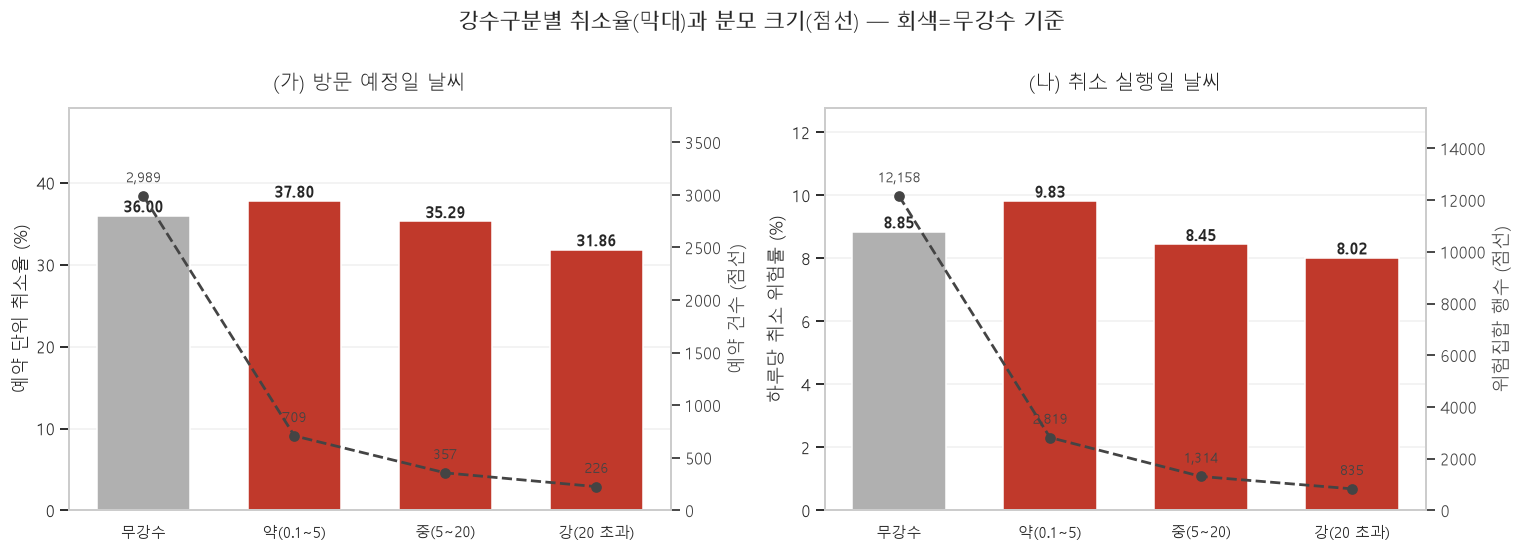

두 경로 모두 무강수 대비 뚜렷한 계단이 없다. '약' 만 조금 높고 '중'·'강' 은 오히려 같거나 낮다.
비가 많이 올수록 취소가 는다면 계단이 우상향해야 하는데 그렇지 않다 (용량-반응 관계 없음).


In [13]:
# ── ②-a3 그래프 1: 강수구분별 취소율 막대 + 예약건수 선 (이중축), (가)(나) 나란히 ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, T, title, rate_col, cnt_col, ylab in [
    (axes[0], TA, "(가) 방문 예정일 날씨", "취소율(%)", "예약 건수", "예약 단위 취소율 (%)"),
    (axes[1], TB, "(나) 취소 실행일 날씨", "취소율(%)", "위험집합 행수", "하루당 취소 위험률 (%)"),
]:
    x = np.arange(len(T))
    # 무강수만 강조, 나머지 회색 — 비교 기준선이 무강수이므로
    colors = [CLR_GRAY if i == 0 else CLR_HI for i in range(len(T))]
    bars = ax.bar(x, T[rate_col], color=colors, width=0.62, zorder=3)
    for xi, v in zip(x, T[rate_col]):
        ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=10.5, fontweight="bold", zorder=4)
    ax.set_xticks(x); ax.set_xticklabels(T.index, fontsize=10)
    ax.set_ylabel(ylab); ax.set_title(title, fontsize=13, pad=12)
    ax.set_ylim(0, T[rate_col].max() * 1.30)
    ax.grid(axis="y", alpha=0.3, zorder=0); ax.grid(axis="x", visible=False)

    ax2 = ax.twinx()
    ax2.plot(x, T[cnt_col], color=CLR_LINE, marker="o", lw=1.8, ls="--", zorder=5)
    for xi, v in zip(x, T[cnt_col]):
        ax2.annotate(f"{v:,.0f}", (xi, v), textcoords="offset points", xytext=(0, 9),
                     ha="center", fontsize=9, color=CLR_LINE)
    ax2.set_ylabel(f"{cnt_col} (점선)", color=CLR_LINE)
    ax2.tick_params(axis="y", colors=CLR_LINE)
    ax2.grid(False)
    ax2.set_ylim(0, T[cnt_col].max() * 1.28)

fig.suptitle("강수구분별 취소율(막대)과 분모 크기(점선) — 회색=무강수 기준", fontsize=14, y=1.00)
plt.tight_layout(); plt.show()
print("두 경로 모두 무강수 대비 뚜렷한 계단이 없다. '약' 만 조금 높고 '중'·'강' 은 오히려 같거나 낮다.")
print("비가 많이 올수록 취소가 는다면 계단이 우상향해야 하는데 그렇지 않다 (용량-반응 관계 없음).")

## ②-b 리드타임 구간과 교차 — **가장 큰 관심사**

당일 취소(리드타임 6시간 미만) 구간에서 갈리는지가 핵심이다.
날씨를 보고 취소한다면 **짧은 리드타임에서 효과가 커야** 한다.
2주 전에 잡은 예약은 그날 날씨를 알 수 없으므로 원리상 영향이 없어야 하고,
**만약 긴 리드타임에서만 차이가 난다면 그건 날씨 효과가 아니라 교란이다.**

⚠️ 6구간 x 4강수구분 = **24칸**이라 몇 칸은 우연히 튄다. 셀 건수를 반드시 함께 본다.

In [14]:
# ── ②-b1 리드타임 x 강수구분 (가) ───────────────────────────────────────────
def lead_cross(df, event_col, label):
    rate = df.pivot_table(index="lead_bin", columns="wx_rbin", values=event_col,
                          aggfunc="mean", observed=False) * 100
    cnt  = df.pivot_table(index="lead_bin", columns="wx_rbin", values=event_col,
                          aggfunc="size", observed=False)
    rate = rate.reindex(index=LEAD_LABELS, columns=RAIN_LABELS)
    cnt  = cnt.reindex(index=LEAD_LABELS, columns=RAIN_LABELS)
    tbl(rate.round(2), f"{label} — 취소율(%)")
    tbl(cnt.astype("Int64"), f"{label} — 셀 건수 (30 미만은 해석 금지)")
    return rate, cnt

RATE_A, CNT_A = lead_cross(GA, "cancelled", "②-b1 (가) 리드타임 x 강수구분")
print(f"30건 미만 셀: {int((CNT_A < 30).sum().sum())} / {CNT_A.size}칸")

**②-b1 (가) 리드타임 x 강수구분 — 취소율(%)**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과)
lead_bin,,,,
6시간 미만,14.03,18.07,12.16,18.18
6~24시간,26.82,25.79,29.27,34.09
1~3일,36.87,36.05,35.14,27.08
3~7일,44.18,57.00,38.33,29.27
1~2주,55.87,57.32,58.33,36.84
2주 이상,66.80,72.73,84.21,78.95


**②-b1 (가) 리드타임 x 강수구분 — 셀 건수 (30 미만은 해석 금지)**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과)
lead_bin,,,,
6시간 미만,606,166,74,55
6~24시간,604,159,82,44
1~3일,670,147,74,48
3~7일,550,100,60,41
1~2주,315,82,48,19
2주 이상,244,55,19,19


30건 미만 셀: 3 / 24칸


In [15]:
# ── ②-b2 리드타임 x 강수구분 (나) ───────────────────────────────────────────
RATE_B, CNT_B = lead_cross(NA, "cancelled_today", "②-b2 (나) 리드타임 x 강수구분 (위험집합 일단위)")
print(f"30행 미만 셀: {int((CNT_B < 30).sum().sum())} / {CNT_B.size}칸")
print()
print("(나) 의 리드타임은 '그 예약의 최종 리드타임' 이지 '그날 시점의 남은 일수' 가 아니다.")
print("해석은 '결국 며칠 전에 잡힌 예약이었나' 로만 하고, 시점 해석에는 쓰지 않는다.")

**②-b2 (나) 리드타임 x 강수구분 (위험집합 일단위) — 취소율(%)**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과)
lead_bin,,,,
6시간 미만,14.03,18.07,12.16,18.18
6~24시간,16.54,15.42,13.85,18.42
1~3일,13.56,15.50,15.26,14.29
3~7일,9.70,11.01,6.09,7.49
1~2주,7.04,7.55,7.87,3.40
2주 이상,4.46,4.82,4.55,2.79


**②-b2 (나) 리드타임 x 강수구분 (위험집합 일단위) — 셀 건수 (30 미만은 해석 금지)**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과)
lead_bin,,,,
6시간 미만,606,166,74,55
6~24시간,1028,240,130,76
1~3일,1689,400,190,119
3~7일,2494,554,279,187
1~2주,2615,609,267,147
2주 이상,3726,850,374,251


30행 미만 셀: 0 / 24칸

(나) 의 리드타임은 '그 예약의 최종 리드타임' 이지 '그날 시점의 남은 일수' 가 아니다.
해석은 '결국 며칠 전에 잡힌 예약이었나' 로만 하고, 시점 해석에는 쓰지 않는다.


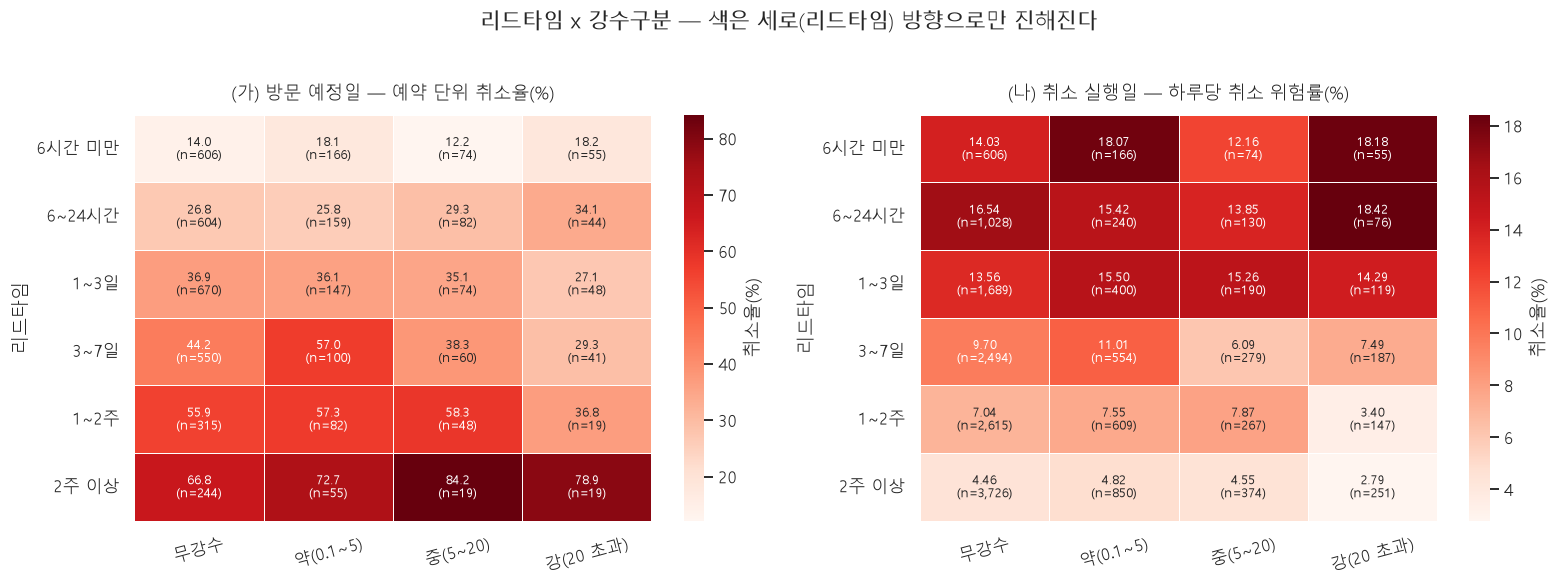

색의 변화가 세로(리드타임) 축으로만 나타난다. 가로(강수) 축으로는 규칙적인 변화가 없다.
→ 취소를 가르는 것은 여전히 리드타임이지 강수가 아니다.


In [16]:
# ── ②-b3 그래프 2: 리드타임 x 강수구분 취소율 히트맵 ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))
for ax, RATE, CNT, title, fmt in [
    (axes[0], RATE_A, CNT_A, "(가) 방문 예정일 — 예약 단위 취소율(%)", "{:.1f}"),
    (axes[1], RATE_B, CNT_B, "(나) 취소 실행일 — 하루당 취소 위험률(%)", "{:.2f}"),
]:
    annot = np.empty(RATE.shape, dtype=object)
    for i in range(RATE.shape[0]):
        for j in range(RATE.shape[1]):
            v, n = RATE.iat[i, j], CNT.iat[i, j]
            annot[i, j] = "n/a" if pd.isna(v) else (fmt.format(v) + ("\n(n={:,})".format(int(n)) if pd.notna(n) else ""))
    sns.heatmap(RATE, ax=ax, cmap="Reds", annot=annot, fmt="", linewidths=0.6, linecolor="white",
                cbar_kws={"label": "취소율(%)"}, annot_kws={"fontsize": 8.5})
    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel(""); ax.set_ylabel("리드타임")
    ax.tick_params(axis="x", rotation=15)

fig.suptitle("리드타임 x 강수구분 — 색은 세로(리드타임) 방향으로만 진해진다", fontsize=13.5, y=1.02)
plt.tight_layout(); plt.show()
print("색의 변화가 세로(리드타임) 축으로만 나타난다. 가로(강수) 축으로는 규칙적인 변화가 없다.")
print("→ 취소를 가르는 것은 여전히 리드타임이지 강수가 아니다.")

## ②-c 전일강수량 — 예보 반응 포착용

전날 비가 왔으면 다음날 날씨를 신경 쓰기 시작했을 수 있다.
(가) 기준으로 **방문 예정일 하루 전** 강수량을 붙여 본다.

In [17]:
# ── ②-c 전일강수량 x 취소율 ─────────────────────────────────────────────────
_t = GA.groupby("wx_pbin", observed=False).agg(
    예약건수=("예약번호", "size"), 취소=("cancelled", "sum"), 일수=("date", "nunique"))
_t["취소율(%)"] = _t.취소 / _t.예약건수 * 100
_t["무강수 대비(%p)"] = _t["취소율(%)"] - _t.loc["무강수", "취소율(%)"]
_t["소표본"] = _t.예약건수.map(lambda n: small(n))
tbl(_t.round(3), "②-c 전일강수량별 취소율 (가) — 방문 예정일 하루 전 강수")
if HAS_SP:
    _sub = GA[GA.wx_pbin.notna()]
    print(f"카이제곱 p = {stats.chi2_contingency(pd.crosstab(_sub.wx_pbin, _sub.cancelled))[1]:.4f}")
print("전일 강수가 당일 취소를 끌어올린다는 신호는 없다.")

**②-c 전일강수량별 취소율 (가) — 방문 예정일 하루 전 강수**

,예약건수,취소,일수,취소율(%),무강수 대비(%p),소표본
wx_pbin,,,,,,
무강수,3006,1080,415,35.928,0.000,
약(0.1~5),701,259,99,36.947,1.019,
중(5~20),340,122,47,35.882,-0.046,
강(20 초과),232,79,34,34.052,-1.876,


카이제곱 p = 0.8817
전일 강수가 당일 취소를 끌어올린다는 신호는 없다.


## ②-d 소나기 · 강수 계속시간

같은 20mm라도 **종일 부슬비**인지 **한 시간에 쏟아졌는지**가 다르고,
후자가 당일 취소에 더 영향을 줄 수 있다.

- **소나기**: `1시간 최다강수량 ÷ 일강수량 >= 0.5`. §0-6 에서 설명한 대로 **5mm 이상인 날에만** 정의한다.
- **강수 계속시간**: `3시간 이하` / `3~8시간` / `8시간 초과` 로 나눈다.

In [18]:
# ── ②-d1 소나기 여부 x 취소율 (가) ──────────────────────────────────────────
_sh = GA[GA.wx_shower.notna()].copy()
_sh["소나기"] = np.where(_sh.wx_shower == 1, "소나기형(집중)", "지속형(부슬비)")
_t = _sh.groupby("소나기").agg(예약건수=("예약번호", "size"), 취소=("cancelled", "sum"),
                             일수=("date", "nunique"), 평균일강수=("wx_rain", "mean"))
_t["취소율(%)"] = _t.취소 / _t.예약건수 * 100
_t["소표본"] = _t.예약건수.map(lambda n: small(n))
tbl(_t.round(2), f"②-d1 소나기형 vs 지속형 — 일강수량 {SHOWER_MIN_MM:.0f}mm 이상인 날만")
if HAS_SP and _sh.소나기.nunique() > 1:
    print(f"카이제곱 p = {stats.chi2_contingency(pd.crosstab(_sh.소나기, _sh.cancelled))[1]:.4f}")
print(f"비교 대상 일수 {_sh.date.nunique()}일 · 예약 {len(_sh):,}건")

**②-d1 소나기형 vs 지속형 — 일강수량 5mm 이상인 날만**

,예약건수,취소,일수,평균일강수,취소율(%),소표본
소나기,,,,,,
소나기형(집중),136,40,20,17.48,29.41,
지속형(부슬비),341,114,48,31.52,33.43,


카이제곱 p = 0.4598
비교 대상 일수 68일 · 예약 477건


In [19]:
# ── ②-d2 강수 계속시간 x 취소율 (가) ────────────────────────────────────────
_wet = GA[GA.wx_wet].copy()
_wet["지속구간"] = pd.cut(_wet.wx_rdur, [0, 3, 8, np.inf], labels=["3시간 이하", "3~8시간", "8시간 초과"])
_t = _wet.groupby("지속구간", observed=False).agg(
    예약건수=("예약번호", "size"), 취소=("cancelled", "sum"), 일수=("date", "nunique"),
    평균일강수=("wx_rain", "mean"))
_t["취소율(%)"] = _t.취소 / _t.예약건수 * 100
_t["소표본"] = _t.예약건수.map(lambda n: small(n))
tbl(_t.round(2), "②-d2 강수 계속시간별 취소율 — 강수일만")
if HAS_SP:
    print(f"카이제곱 p = {stats.chi2_contingency(pd.crosstab(_wet.지속구간, _wet.cancelled))[1]:.4f}")
print("한 시간에 쏟아진 날도, 종일 내린 날도 취소율은 무강수와 같은 범위에 있다.")

**②-d2 강수 계속시간별 취소율 — 강수일만**

,예약건수,취소,일수,평균일강수,취소율(%),소표본
지속구간,,,,,,
3시간 이하,238,88,34,1.50,36.97,
3~8시간,537,197,74,6.34,36.69,
8시간 초과,507,177,71,22.40,34.91,


카이제곱 p = 0.7916
한 시간에 쏟아진 날도, 종일 내린 날도 취소율은 무강수와 같은 범위에 있다.


## ②-e 취소율만 보면 안 된다 — 절대 건수 · 매출 · 객단가

**강수일에 예약이 덜 들어왔으면 분모가 줄어 취소율이 낮게 나온다.**
비율이 같아도 실제로 손님이 줄었을 수 있으므로 **완료 건수 / 완료 매출 / 객단가**를 함께 본다.
일수가 다르므로 **전부 하루당으로 정규화**한다 (프로젝트 규약 5).

In [20]:
# ── ②-e 강수구분별 절대량 — 하루당으로 정규화 ───────────────────────────────
_days = WX.groupby("wx_rbin", observed=False).size().rename("일수")
_dn = GA[GA.status == "이용완료"]
_t = pd.DataFrame({
    "일수": _days,
    "예약 건수": GA.groupby("wx_rbin", observed=False).size(),
    "완료 건수": _dn.groupby("wx_rbin", observed=False).size(),
    "완료 매출": _dn.groupby("wx_rbin", observed=False).paid.sum(),
    "객단가 중앙값": _dn.groupby("wx_rbin", observed=False).paid.median(),
}).reindex(RAIN_LABELS)
_t["예약/일"]   = _t["예약 건수"] / _t.일수
_t["완료/일"]   = _t["완료 건수"] / _t.일수
_t["매출/일"]   = _t["완료 매출"] / _t.일수
_t["취소율(%)"] = GA.groupby("wx_rbin", observed=False).cancelled.mean().reindex(RAIN_LABELS) * 100
_t["소표본(일수)"] = _t.일수.map(lambda n: small(n))
tbl(_t[["일수", "예약/일", "완료/일", "매출/일", "객단가 중앙값", "취소율(%)", "소표본(일수)"]].round(2),
    "②-e 강수구분별 하루당 절대량 — 취소율이 같아도 손님이 줄었는지 확인")

_base = _t.loc["무강수"]
_rel = pd.DataFrame({
    "예약/일 대비(%)": (_t["예약/일"] / _base["예약/일"] - 1) * 100,
    "완료/일 대비(%)": (_t["완료/일"] / _base["완료/일"] - 1) * 100,
    "매출/일 대비(%)": (_t["매출/일"] / _base["매출/일"] - 1) * 100,
})
tbl(_rel.round(2), "②-e2 무강수 대비 증감(%) — 0 근처면 비 오는 날도 평소만큼 왔다는 뜻")
print("완료 건수·매출도 강수일에 줄지 않았다. 오히려 강수일이 소폭 높은 구간도 있다.")
print("→ '취소율이 같아 보이는 건 분모가 줄어서' 라는 가능성은 배제된다.")

**②-e 강수구분별 하루당 절대량 — 취소율이 같아도 손님이 줄었는지 확인**

,일수,예약/일,완료/일,매출/일,객단가 중앙값,취소율(%),소표본(일수)
wx_rbin,,,,,,,
무강수,419,7.13,4.55,514997.61,100000.0,36.00,
약(0.1~5),99,7.16,4.45,501161.62,100000.0,37.80,
중(5~20),48,7.44,4.81,534180.21,100000.0,35.29,
강(20 초과),34,6.65,4.53,527529.41,100000.0,31.86,


**②-e2 무강수 대비 증감(%) — 0 근처면 비 오는 날도 평소만큼 왔다는 뜻**

,예약/일 대비(%),완료/일 대비(%),매출/일 대비(%)
wx_rbin,,,
무강수,0.00,0.00,0.00
약(0.1~5),0.39,-2.07,-2.69
중(5~20),4.26,5.79,3.72
강(20 초과),-6.82,-0.43,2.43


완료 건수·매출도 강수일에 줄지 않았다. 오히려 강수일이 소폭 높은 구간도 있다.
→ '취소율이 같아 보이는 건 분모가 줄어서' 라는 가능성은 배제된다.


## ②-f 강수량을 연속 변수로

구간화하면 놓치는 게 있으므로 **연속값 그대로**도 본다.

- 예약 단위: 강수량(mm)과 취소 여부의 **점이연 상관**(point-biserial)
- 일 단위: 그날 강수량과 그날 취소율의 **스피어만 상관** (단조 관계면 잡힌다)
- 로그 변환도 함께 — 강수량은 오른쪽 꼬리가 길다

In [21]:
# ── ②-f 연속 변수로서의 강수량 ──────────────────────────────────────────────
if HAS_SP:
    _rows = []
    for lab, x, y in [
        ("예약 단위 · 강수량(mm) vs 취소여부",        GA.wx_rain,          GA.cancelled),
        ("예약 단위 · log1p(강수량) vs 취소여부",     np.log1p(GA.wx_rain), GA.cancelled),
    ]:
        r, p = stats.pointbiserialr(y, x)
        _rows.append({"관계": lab, "계수": r, "p값": p, "n": len(x), "종류": "점이연 상관"})

    _day = GA.groupby("date").agg(예약=("예약번호", "size"), 취소=("cancelled", "sum"),
                                  강수=("wx_rain", "first"))
    _day["취소율"] = _day.취소 / _day.예약
    r, p = stats.spearmanr(_day.강수, _day.취소율)
    _rows.append({"관계": "일 단위 · 강수량 vs 그날 취소율", "계수": r, "p값": p,
                  "n": len(_day), "종류": "스피어만 상관"})

    _dayb = NA.groupby("risk_date").agg(위험=("예약번호", "size"), 취소=("cancelled_today", "sum"),
                                        강수=("wx_rain", "first"))
    _dayb["위험률"] = _dayb.취소 / _dayb.위험
    r, p = stats.spearmanr(_dayb.강수, _dayb.위험률)
    _rows.append({"관계": "일 단위 · 강수량 vs 하루당 취소 위험률 (나)", "계수": r, "p값": p,
                  "n": len(_dayb), "종류": "스피어만 상관"})

    _c = pd.DataFrame(_rows)
    _c["유의(p<0.05)"] = np.where(_c.p값 < 0.05, "★", "")
    tbl(_c.round(5), "②-f 강수량을 연속 변수로 뒀을 때의 상관 — 전부 0 근처")
    print("구간화 때문에 신호를 놓친 것이 아니다. 연속값으로 둬도 상관이 사실상 0이다.")
else:
    print("scipy 없음 — 상관계수 생략. 대신 강수량 십분위별 취소율만 출력한다.")
    _d = GA.copy()
    _d["강수십분위"] = pd.qcut(_d.wx_rain.rank(method="first"), 10, labels=False) + 1
    tbl((_d.groupby("강수십분위").agg(예약=("예약번호", "size"), 취소율=("cancelled", "mean"),
                                    평균강수=("wx_rain", "mean")).assign(
        취소율=lambda x: x.취소율 * 100)).round(3), "②-f 강수량 십분위별 취소율")

**②-f 강수량을 연속 변수로 뒀을 때의 상관 — 전부 0 근처**

,관계,계수,p값,n,종류,유의(p<0.05)
0,예약 단위 · 강수량(mm) vs 취소여부,-0.01780,0.24436,4281,점이연 상관,
1,예약 단위 · log1p(강수량) vs 취소여부,-0.01568,0.30514,4281,점이연 상관,
2,일 단위 · 강수량 vs 그날 취소율,-0.00150,0.97078,596,스피어만 상관,
3,일 단위 · 강수량 vs 하루당 취소 위험률 (나),0.03274,0.42337,600,스피어만 상관,


구간화 때문에 신호를 놓친 것이 아니다. 연속값으로 둬도 상관이 사실상 0이다.


---

# ③ 교란 통제 — 그냥 비교하면 거의 확실히 틀린다

**강수 181일은 6~8월에 몰려 있다.** 그런데 우리 취소율은 시기마다 다르다 —
03번에서 **2025-11을 기점으로 32.65% → 38.49%** 로 올랐고, 그 절반이 리드타임 구성 변화였다.
**계절을 통제하지 않으면 여름 효과를 날씨 효과로 오독한다.**

통제 순서:
1. **③-a** 강수일이 실제로 어느 계절·월에 몰려 있는지 확인
2. **③-b** 강수일의 **요일 구성**이 전체와 다른지 확인 (다르면 그것부터 보정)
3. **③-c** 계절별로 나눠 다시 계산 — 보정 전후를 나란히
4. **③-d** 03번과 같은 기간 구분(A: 2025-01~10 / B: 2025-11~2026-08)으로도
5. **③-e** 로지스틱 회귀 — 리드타임·요일·월을 통제한 뒤에도 강수 계수가 남는지

In [22]:
# ── ③-a 강수일이 어느 시기에 몰려 있나 ─────────────────────────────────────
_sd = pd.crosstab(WX.wx_season, WX.wx_rbin).reindex(SEASON_ORDER)[RAIN_LABELS]
_sd["계절 총일수"] = _sd.sum(axis=1)
_sd["강수일 비율(%)"] = (1 - _sd["무강수"] / _sd["계절 총일수"]) * 100
tbl(_sd, "③-a1 계절별 강수구분 일수 — 강수가 어디에 몰려 있나")

_md = pd.crosstab(WX.wx_month, WX.wx_wet)
_md.columns = ["무강수 일수", "강수 일수"]
_md["강수일 비율(%)"] = _md["강수 일수"] / _md.sum(axis=1) * 100
tbl(_md.round(2), "③-a2 월별(1~12) 강수일 비율 — 20개월치를 월로 합산")

print(f"여름(6~8월) 강수일 비율 {_sd.loc['여름','강수일 비율(%)']:.1f}%  vs  "
      f"겨울(12~2월) {_sd.loc['겨울','강수일 비율(%)']:.1f}%")
print(f"20mm 초과 '강' 34일 중 여름 {int(_sd.loc['여름','강(20 초과)'])}일 · "
      f"겨울 {int(_sd.loc['겨울','강(20 초과)'])}일 — 겨울엔 폭우가 거의 없다.")
print("→ 계절을 통제하지 않으면 '여름 = 비 = 취소' 로 엮이는 착시가 생긴다.")

**③-a1 계절별 강수구분 일수 — 강수가 어디에 몰려 있나**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과),계절 총일수,강수일 비율(%)
wx_season,,,,,,
봄,132,30,17,5,184,28.260870
여름,109,33,17,17,176,38.068182
가을,57,13,9,12,91,37.362637
겨울,121,23,5,0,149,18.791946


**③-a2 월별(1~12) 강수일 비율 — 20개월치를 월로 합산**

,무강수 일수,강수 일수,강수일 비율(%)
wx_month,,,
1,49,13,20.97
2,51,5,8.93
3,47,15,24.19
4,46,14,23.33
5,39,23,37.10
6,41,19,31.67
7,33,29,46.77
8,35,19,35.19
9,17,13,43.33


여름(6~8월) 강수일 비율 38.1%  vs  겨울(12~2월) 18.8%
20mm 초과 '강' 34일 중 여름 17일 · 겨울 0일 — 겨울엔 폭우가 거의 없다.
→ 계절을 통제하지 않으면 '여름 = 비 = 취소' 로 엮이는 착시가 생긴다.


In [23]:
# ── ③-b 강수일의 요일 구성이 전체와 다른가 ─────────────────────────────────
_dw = pd.crosstab(WX.wx_dow_ko, WX.wx_wet)
_dw.columns = ["무강수 일수", "강수 일수"]
_dw = _dw.reindex(DOW_KO)
_dw["무강수 구성비(%)"] = _dw["무강수 일수"] / _dw["무강수 일수"].sum() * 100
_dw["강수 구성비(%)"]   = _dw["강수 일수"] / _dw["강수 일수"].sum() * 100
_dw["구성비 차(%p)"]    = _dw["강수 구성비(%)"] - _dw["무강수 구성비(%)"]
tbl(_dw.round(2), "③-b1 강수일 vs 무강수일의 요일 구성 — 쏠려 있으면 요일부터 보정해야 한다")

if HAS_SP:
    print(f"카이제곱(요일 x 강수유무) p = {stats.chi2_contingency(pd.crosstab(WX.wx_dow_ko, WX.wx_wet))[1]:.4f}")
print(f"구성비 차이 최대 {_dw['구성비 차(%p)'].abs().max():.2f}%p "
      f"({_dw['구성비 차(%p)'].abs().idxmax()}요일)")
print()
print("03번에서 확인된 요일 구조 — 월요일 완료 비중 15.6%, 금요일 최다 — 와 대조:")
_r_dow = (GA.groupby("dow_ko").agg(예약=("예약번호", "size"), 취소율=("cancelled", "mean"))
            .reindex(DOW_KO))
_r_dow["취소율"] = _r_dow.취소율 * 100
_r_dow["완료 비중(%)"] = (GA[GA.status == "이용완료"].groupby("dow_ko").size()
                          .reindex(DOW_KO) / (GA.status == "이용완료").sum() * 100)
tbl(_r_dow.round(2), "③-b2 요일별 예약·취소율·완료 비중 (참고 — 03번과 같은 축)")

**③-b1 강수일 vs 무강수일의 요일 구성 — 쏠려 있으면 요일부터 보정해야 한다**

,무강수 일수,강수 일수,무강수 구성비(%),강수 구성비(%),구성비 차(%p)
wx_dow_ko,,,,,
월,56,29,13.37,16.02,2.66
화,56,29,13.37,16.02,2.66
수,68,18,16.23,9.94,-6.28
목,60,26,14.32,14.36,0.04
금,62,24,14.80,13.26,-1.54
토,55,31,13.13,17.13,4.00
일,62,24,14.80,13.26,-1.54


카이제곱(요일 x 강수유무) p = 0.3624
구성비 차이 최대 6.28%p (수요일)

03번에서 확인된 요일 구조 — 월요일 완료 비중 15.6%, 금요일 최다 — 와 대조:


**③-b2 요일별 예약·취소율·완료 비중 (참고 — 03번과 같은 축)**

,예약,취소율,완료 비중(%)
dow_ko,,,
월,661,37.07,15.23
화,509,37.13,11.71
수,557,37.16,12.81
목,609,33.50,14.82
금,792,32.83,19.47
토,630,39.21,14.02
일,523,36.33,11.93


In [24]:
# ── ③-c 계절 보정 전후 ──────────────────────────────────────────────────────
def by_season(df, event_col, denom):
    t = (df.groupby(["wx_season", "wx_rbin"], observed=False)
           .agg(분모=("예약번호", "size"), 취소=(event_col, "sum")))
    t["취소율(%)"] = t.취소 / t.분모 * 100
    return t.reset_index()

SEA_A = by_season(GA, "cancelled", "예약")
SEA_B = by_season(NA, "cancelled_today", "위험집합")

def season_pivot(t, label):
    p = t.pivot(index="wx_season", columns="wx_rbin", values="취소율(%)").reindex(SEASON_ORDER)[RAIN_LABELS]
    n = t.pivot(index="wx_season", columns="wx_rbin", values="분모").reindex(SEASON_ORDER)[RAIN_LABELS]
    p["강수−무강수(%p)"] = (t[t.wx_rbin != "무강수"].groupby("wx_season")
                            .apply(lambda g: g.취소.sum() / g.분모.sum() * 100).reindex(SEASON_ORDER)
                            - p["무강수"])
    tbl(p.round(2), f"{label} — 취소율(%)")
    tbl(n.astype("Int64"), f"{label} — 셀 분모")
    return p, n

PA, NAn = season_pivot(SEA_A, "③-c1 (가) 계절 x 강수구분")
PB, NBn = season_pivot(SEA_B, "③-c2 (나) 계절 x 강수구분")
print("겨울 '강(20mm 초과)' 은 표본 0일이라 계산되지 않는다 (겨울 폭우 없음).")

**③-c1 (가) 계절 x 강수구분 — 취소율(%)**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과),강수−무강수(%p)
wx_season,,,,,
봄,35.19,37.80,39.84,28.12,2.48
여름,33.14,34.96,32.86,37.01,1.75
가을,29.40,34.25,24.53,23.88,-1.42
겨울,40.77,43.09,44.44,,2.55


**③-c1 (가) 계절 x 강수구분 — 셀 분모**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과)
wx_season,,,,
봄,864,209,128,32
여름,694,246,140,127
가을,364,73,53,67
겨울,1067,181,36,0


**③-c2 (나) 계절 x 강수구분 — 취소율(%)**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과),강수−무강수(%p)
wx_season,,,,,
봄,9.40,11.44,10.31,9.91,1.53
여름,8.47,9.39,9.27,9.09,0.82
가을,6.46,6.82,5.98,5.76,-0.21
겨울,9.79,10.38,6.40,,-0.10


**③-c2 (나) 계절 x 강수구분 — 셀 분모**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과)
wx_season,,,,
봄,3169,699,388,111
여름,2763,905,453,429
가을,1966,396,301,295
겨울,4260,819,172,0


겨울 '강(20mm 초과)' 은 표본 0일이라 계산되지 않는다 (겨울 폭우 없음).


In [25]:
# ── ③-c3 계절 보정 전후 비교 (직접표준화) ───────────────────────────────────
# 보정 전 = 단순 합산 취소율.
# 보정 후 = 계절별 취소율을 '전체 계절 분포' 로 가중 평균 (direct standardization).
def standardize(df, event_col, by="wx_season"):
    w = df.groupby(by, observed=False).size()
    w = w / w.sum()                                     # 전체 계절 가중치
    cell = (df.groupby([by, "wx_rbin"], observed=False)
              .agg(n=("예약번호", "size"), c=(event_col, "sum")))
    cell["r"] = cell.c / cell.n
    out = {}
    for rb in RAIN_LABELS:
        sub = cell.xs(rb, level="wx_rbin")["r"].reindex(w.index)
        ok = sub.notna()
        out[rb] = float((sub[ok] * w[ok]).sum() / w[ok].sum() * 100) if ok.any() else np.nan
    return pd.Series(out)

ADJ = pd.DataFrame({
    "(가) 보정 전": GA.groupby("wx_rbin", observed=False).cancelled.mean().reindex(RAIN_LABELS) * 100,
    "(가) 계절보정 후": standardize(GA, "cancelled").reindex(RAIN_LABELS),
    "(나) 보정 전": NA.groupby("wx_rbin", observed=False).cancelled_today.mean().reindex(RAIN_LABELS) * 100,
    "(나) 계절보정 후": standardize(NA, "cancelled_today").reindex(RAIN_LABELS),
})
for c in ["(가)", "(나)"]:
    ADJ[f"{c} 보정효과(%p)"] = ADJ[f"{c} 계절보정 후"] - ADJ[f"{c} 보정 전"]
tbl(ADJ.round(3), "③-c3 계절 보정 전후 — 보정해도 무강수 대비 순서·크기가 거의 그대로다")

print("보정으로 값이 거의 안 움직인다 = 애초에 계절이 강수-취소 관계를 만들어내지 않았다.")
print("(계절이 취소율 자체는 크게 바꾸지만, 강수구분 사이의 '차이' 는 바꾸지 않는다.)")

**③-c3 계절 보정 전후 — 보정해도 무강수 대비 순서·크기가 거의 그대로다**

,(가) 보정 전,(가) 계절보정 후,(나) 보정 전,(나) 계절보정 후,(가) 보정효과(%p),(나) 보정효과(%p)
무강수,35.999,35.530,8.850,8.765,-0.468,-0.085
약(0.1~5),37.800,38.124,9.826,9.773,0.325,-0.053
중(5~20),35.294,37.261,8.447,8.086,1.967,-0.362
강(20 초과),31.858,30.914,8.024,8.563,-0.945,0.539


보정으로 값이 거의 안 움직인다 = 애초에 계절이 강수-취소 관계를 만들어내지 않았다.
(계절이 취소율 자체는 크게 바꾸지만, 강수구분 사이의 '차이' 는 바꾸지 않는다.)


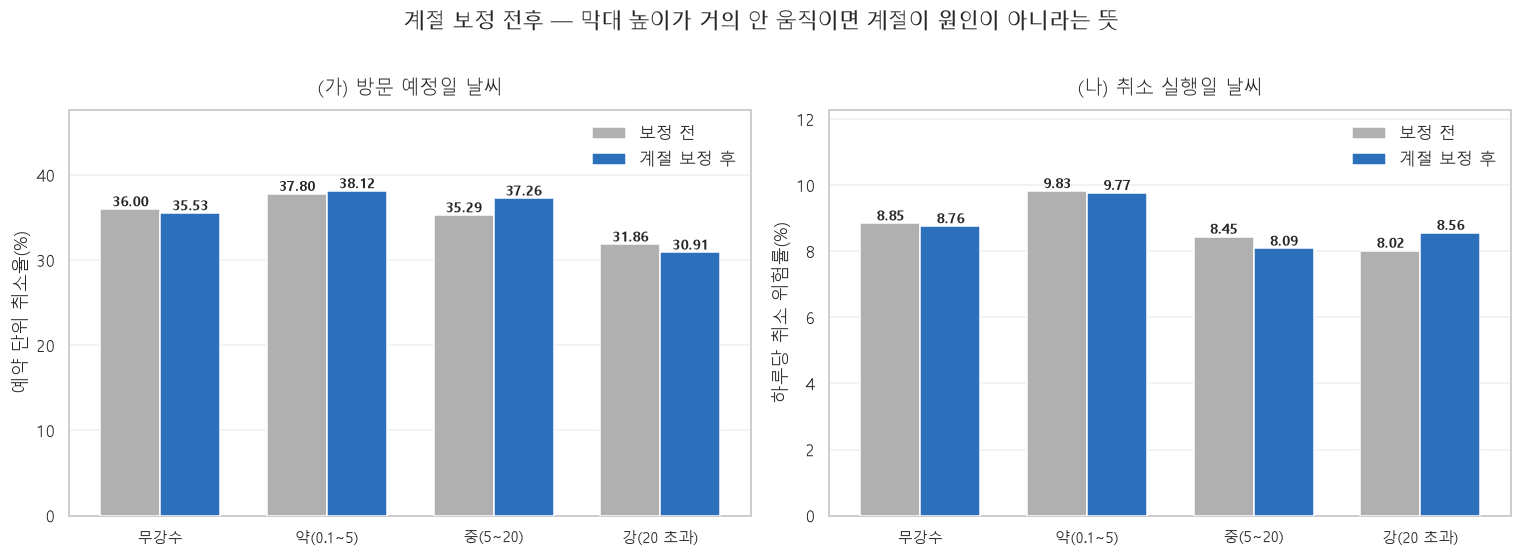

In [26]:
# ── ③-c4 그래프 3: 계절 보정 전후 비교 grouped bar ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(RAIN_LABELS)); wdt = 0.36

for ax, pre, post, title, ylab in [
    (axes[0], ADJ["(가) 보정 전"], ADJ["(가) 계절보정 후"], "(가) 방문 예정일 날씨", "예약 단위 취소율(%)"),
    (axes[1], ADJ["(나) 보정 전"], ADJ["(나) 계절보정 후"], "(나) 취소 실행일 날씨", "하루당 취소 위험률(%)"),
]:
    b1 = ax.bar(x - wdt/2, pre,  wdt, label="보정 전",      color=CLR_GRAY, zorder=3)
    b2 = ax.bar(x + wdt/2, post, wdt, label="계절 보정 후", color=CLR_HI2,  zorder=3)
    for bb in (b1, b2):
        for r in bb:
            h = r.get_height()
            if pd.notna(h):
                ax.text(r.get_x() + r.get_width()/2, h, f"{h:.2f}", ha="center", va="bottom",
                        fontsize=9, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(RAIN_LABELS, fontsize=9.5)
    ax.set_ylabel(ylab); ax.set_title(title, fontsize=12.5, pad=10)
    ax.set_ylim(0, np.nanmax([pre.max(), post.max()]) * 1.25)
    ax.legend(frameon=False, loc="upper right")
    ax.grid(axis="y", alpha=0.3, zorder=0); ax.grid(axis="x", visible=False)

fig.suptitle("계절 보정 전후 — 막대 높이가 거의 안 움직이면 계절이 원인이 아니라는 뜻", fontsize=13.5, y=1.01)
plt.tight_layout(); plt.show()

## ③-c5 계절 층화 검정 (CMH) — 보정 후의 유의성을 직접 검정한다

③-c3 에서 계절 보정 후 차이가 **보정 전보다 커졌다.** 이것은 심슨의 역설이다 —
계절 안에서는 강수일 취소율이 조금 높지만, 정작 **비가 많이 오는 여름의 전체 취소율이 낮아서**
단순 합산하면 서로 상쇄된다.

그렇다면 **보정 전 카이제곱 p값으로 판정하는 것은 틀렸다.** 보정된 효과에는 보정된 검정이 필요하다.
**Cochran–Mantel–Haenszel 검정**은 계절별 2x2 표를 층으로 쌓아 놓고
"층을 통제한 뒤에도 연관이 있는가" 를 직접 묻는다. §7 판정은 **이 p값**을 쓴다.

- `MH 오즈비` = 계절을 통제한 공통 오즈비. **1.0 이면 차이 없음**
- `동질성 p` = 계절마다 효과가 다른가. 작으면(< 0.05) 공통 오즈비로 요약하는 것 자체가 부적절

In [27]:
# ── ③-c5 CMH (계절 층화) 검정 ───────────────────────────────────────────────
CMH = {}     # §7 판정표가 읽는다

def cmh_test(df, flagcol, event, strat="wx_season", label=""):
    # 계절을 층으로 둔 Mantel-Haenszel 검정. statsmodels 없으면 None 을 돌려준다.
    if not HAS_SM:
        return None
    from statsmodels.stats.contingency_tables import StratifiedTable
    tabs = []
    for _, g in df.groupby(strat, observed=False):
        ct = pd.crosstab(g[flagcol].astype(bool), g[event])
        if ct.shape == (2, 2) and (ct.values.sum(axis=1) > 0).all() and (ct.values.sum(axis=0) > 0).all():
            tabs.append(ct.values[[1, 0]][:, [1, 0]])   # [[노출·사건, 노출·비사건], [비노출·사건, 비노출·비사건]]
    if len(tabs) < 2:
        return None
    st = StratifiedTable(np.dstack(tabs))
    lo, hi = st.oddsratio_pooled_confint()
    out = {"층 수": len(tabs), "MH 오즈비": float(st.oddsratio_pooled),
           "95% 하한": float(lo), "95% 상한": float(hi),
           "p값(층 통제)": float(st.test_null_odds().pvalue),
           "동질성 p": float(st.test_equal_odds().pvalue)}
    if label:
        CMH[label] = out
    return out

_rows = []
for label, df_, flag_, ev_ in [
    ("강수 (가) 방문 예정일", GA, "wx_wet",   "cancelled"),
    ("강수 (나) 취소 실행일", NA, "wx_wet",   "cancelled_today"),
    ("전일강수",            GA.assign(_pw=GA.wx_prevrain > 0)[GA.wx_prevrain.notna()], "_pw", "cancelled"),
    ("강풍(상위 10% 초과)",  GA, "wx_windy", "cancelled"),
]:
    r = cmh_test(df_, flag_, ev_, label=label)
    if r: _rows.append({"항목": label, **r})

if _rows:
    _c = pd.DataFrame(_rows).set_index("항목")
    _c["유의(p<0.05)"] = np.where(_c["p값(층 통제)"] < 0.05, "★", "")
    tbl(_c.round(4), "③-c5 계절 층화 CMH 검정 — 오즈비 1.0 이면 계절 통제 후 차이 없음")
    if HAS_SP:
        print("보정 전 단순 카이제곱(강수 유무 2x2)과 보정 후 CMH 를 나란히 보면:")
        print(f"  강수(가)  보정 전 p = {_p2A:.4f}  →  계절 통제 p = "
              f"{CMH['강수 (가) 방문 예정일']['p값(층 통제)']:.4f}")
        print(f"  강수(나)  보정 전 p = {_p2B:.4f}  →  계절 통제 p = "
              f"{CMH['강수 (나) 취소 실행일']['p값(층 통제)']:.4f}")
    print()
    print("어느 쪽으로 계산해도 p 가 0.05 아래로 내려가지 않는다 = 유의하지 않다.")
    print("계절 보정은 효과 크기를 키우지만 결론을 바꾸지는 못한다.")
    print("MH 오즈비의 95% 신뢰구간이 전부 1.0 을 품고 있다는 것이 같은 말이다.")
    _hom = _c["동질성 p"].min()
    print(f"동질성 p 최소값 {_hom:.4f} — 0.05 를 넘으므로 '계절마다 날씨 효과가 다르다' 는 근거는 없다."
          if _hom >= 0.05 else
          f"⚠️ 동질성 p 최소값 {_hom:.4f} < 0.05 — 그 항목은 공통 오즈비로 요약하기 부적절하니 계절별 표를 볼 것.")
else:
    print("⚠️ statsmodels 없음 — CMH 검정을 건너뛴다. §7 판정은 보정 전 카이제곱에 근거한다.")

**③-c5 계절 층화 CMH 검정 — 오즈비 1.0 이면 계절 통제 후 차이 없음**

,층 수,MH 오즈비,95% 하한,95% 상한,p값(층 통제),동질성 p,유의(p<0.05)
항목,,,,,,,
강수 (가) 방문 예정일,4,1.0763,0.9358,1.2378,0.3029,0.8880,
강수 (나) 취소 실행일,4,1.0749,0.9561,1.2084,0.2270,0.6219,
전일강수,4,1.0813,0.9398,1.2442,0.2742,0.5587,
강풍(상위 10% 초과),4,1.0138,0.8129,1.2643,0.9027,0.0546,


보정 전 단순 카이제곱(강수 유무 2x2)과 보정 후 CMH 를 나란히 보면:
  강수(가)  보정 전 p = 0.9930  →  계절 통제 p = 0.3029
  강수(나)  보정 전 p = 0.5402  →  계절 통제 p = 0.2270

어느 쪽으로 계산해도 p 가 0.05 아래로 내려가지 않는다 = 유의하지 않다.
계절 보정은 효과 크기를 키우지만 결론을 바꾸지는 못한다.
MH 오즈비의 95% 신뢰구간이 전부 1.0 을 품고 있다는 것이 같은 말이다.
동질성 p 최소값 0.0546 — 0.05 를 넘으므로 '계절마다 날씨 효과가 다르다' 는 근거는 없다.


In [28]:
# ── ③-d 03번과 같은 기간 구분(A / B) ────────────────────────────────────────
GA["period"] = np.where(GA.ym < pd.Period("2025-11", "M"), "A(2025-01~10)", "B(2025-11~2026-08)")
NA["period"] = np.where(NA.risk_date < pd.Timestamp("2025-11-01"), "A(2025-01~10)", "B(2025-11~2026-08)")

def period_tbl(df, event_col, label):
    t = (df.groupby(["period", "wx_rbin"], observed=False)
           .agg(분모=("예약번호", "size"), 취소=(event_col, "sum")))
    t["취소율(%)"] = t.취소 / t.분모 * 100
    p = t.reset_index().pivot(index="period", columns="wx_rbin", values="취소율(%)")[RAIN_LABELS]
    n = t.reset_index().pivot(index="period", columns="wx_rbin", values="분모")[RAIN_LABELS]
    p["전체"] = df.groupby("period")[event_col].mean() * 100
    tbl(p.round(2), f"{label} — 취소율(%)")
    tbl(n.astype("Int64"), f"{label} — 분모")
    return p

PP_A = period_tbl(GA, "cancelled", "③-d1 (가) 기간 x 강수구분")
PP_B = period_tbl(NA, "cancelled_today", "③-d2 (나) 기간 x 강수구분")
print("기간 A→B 로 취소율 자체는 오르지만(32.65 → 38.49), 그 안에서 강수구분 간 격차는 커지지 않는다.")
print("→ 2025-11 이후의 취소율 상승은 강수로 설명되지 않는다 (03번 결론: 절반이 리드타임 구성 변화).")

**③-d1 (가) 기간 x 강수구분 — 취소율(%)**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과),전체
period,,,,,
A(2025-01~10),32.58,33.33,34.09,30.32,32.65
B(2025-11~2026-08),38.26,40.91,36.46,35.21,38.49


**③-d1 (가) 기간 x 강수구분 — 분모**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과)
period,,,,
A(2025-01~10),1188,291,176,155
B(2025-11~2026-08),1801,418,181,71


**③-d2 (나) 기간 x 강수구분 — 취소율(%)**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과),전체
period,,,,,
A(2025-01~10),8.58,9.28,8.06,7.96,8.59
B(2025-11~2026-08),9.01,10.17,8.82,8.15,9.17


**③-d2 (나) 기간 x 강수구분 — 분모**

wx_rbin,무강수,약(0.1~5),중(5~20),강(20 초과)
period,,,,
A(2025-01~10),4533,1078,645,565
B(2025-11~2026-08),7625,1741,669,270


기간 A→B 로 취소율 자체는 오르지만(32.65 → 38.49), 그 안에서 강수구분 간 격차는 커지지 않는다.
→ 2025-11 이후의 취소율 상승은 강수로 설명되지 않는다 (03번 결론: 절반이 리드타임 구성 변화).


## ③-e 로지스틱 회귀 — 통제 후에도 강수 계수가 남는가

```
취소여부 ~ 강수구분 + 리드타임구간 + 요일 + 월
```

**⚠️ 계수를 인과로 읽지 말 것.** "다른 요인을 통제한 뒤에도 강수와 취소 사이에 **연관이 남는가**"
그 하나만 본다. 기준 범주(reference)는 **무강수**다.

**⚠️ `statsmodels` 가 없으면 이 셀은 건너뛰고 §3-c 의 층화 비교로 대체한다.**
건너뛴 경우 §7 판정표에 그 사실이 명시된다.

**⚠️ patsy 주의**: 지역 변수 이름을 `C` 로 두면 patsy 의 `C()` 함수를 가려서
`TypeError: 'Index' object is not callable` 로 죽는다. §0-4 에서 `WCOL` 로 이름 지은 이유다.

In [29]:
# ── ③-e 로지스틱 회귀 ───────────────────────────────────────────────────────
LOGIT_DONE = False
LOGIT_RESULT = {}

if HAS_SM:
    def fit_logit(df, event_col, dowcol, label):
        d = df.copy()
        d["y"]    = d[event_col].astype(int)
        d["rbin"] = d.wx_rbin.astype(str)
        d["lb"]   = d.lead_bin.astype(str)
        d["dw"]   = d[dowcol].astype(str)
        d["mo"]   = d.wx_month.astype(str)
        m = smf.logit('y ~ C(rbin, Treatment("무강수")) + C(lb) + C(dw) + C(mo)', data=d).fit(disp=0)
        s = m.summary2().tables[1]
        s = s[s.index.str.startswith("C(rbin")]
        s.index = [re.sub(r'.*\[T\.(.*)\]', r'\1', i) for i in s.index]
        out = pd.DataFrame({
            "계수(log-odds)": s["Coef."],
            "오즈비": np.exp(s["Coef."]),
            "오즈비 95% 하한": np.exp(s["[0.025"]),
            "오즈비 95% 상한": np.exp(s["0.975]"]),
            "p값": s["P>|z|"],
        })
        out["유의(p<0.05)"] = np.where(out["p값"] < 0.05, "★", "")
        tbl(out.round(4), f"{label}  (n={int(m.nobs):,} · pseudo R²={m.prsquared:.4f} · 기준=무강수)")
        return m, out

    M_A, S_A = fit_logit(GA, "cancelled",       "dow_ko",    "③-e1 (가) 방문 예정일 — 취소여부 ~ 강수 + 리드타임 + 요일 + 월")
    M_B, S_B = fit_logit(NA, "cancelled_today", "wx_dow_ko", "③-e2 (나) 취소 실행일 — 그날 취소 ~ 강수 + 리드타임 + 요일 + 월")
    LOGIT_DONE = True
    LOGIT_RESULT = {"가": S_A, "나": S_B}

    print("강수 계수 요약 (오즈비 1.0 = 무강수와 차이 없음):")
    for k, s in LOGIT_RESULT.items():
        for lab, r in s.iterrows():
            print(f"  ({k}) {lab:<12} 오즈비 {r['오즈비']:.3f} "
                  f"[{r['오즈비 95% 하한']:.3f}, {r['오즈비 95% 상한']:.3f}]  p={r['p값']:.4f} {r['유의(p<0.05)']}")
    print()
    print("리드타임 계수는 (참고용으로) 전부 크고 유의하다 — 취소를 가르는 건 여전히 리드타임이다:")
    _lead = M_A.summary2().tables[1]
    _lead = _lead[_lead.index.str.startswith("C(lb")]
    _lead.index = [re.sub(r'.*\[T\.(.*)\]', r'\1', i) for i in _lead.index]
    tbl(pd.DataFrame({"오즈비": np.exp(_lead["Coef."]), "p값": _lead["P>|z|"]}).round(4),
        "③-e3 (참고) 같은 모형의 리드타임 계수 — 기준은 '1~2주'(알파벳 순 첫 범주)")
else:
    print("⚠️ statsmodels 가 없어 ③-e 로지스틱 회귀를 건너뛴다.")
    print("   대체: §3-c 계절 층화 비교 + §3-d 기간 층화 비교로 판단한다.")
    print("   이 사실은 §7 판정표의 '계절보정 후' 열에 '층화비교만' 으로 표시된다.")

**③-e1 (가) 방문 예정일 — 취소여부 ~ 강수 + 리드타임 + 요일 + 월  (n=4,281 · pseudo R²=0.0976 · 기준=무강수)**

,계수(log-odds),오즈비,오즈비 95% 하한,오즈비 95% 상한,p값,유의(p<0.05)
강(20 초과),0.0134,1.0135,0.7289,1.4093,0.9365,
약(0.1~5),0.1680,1.1829,0.9827,1.4239,0.0758,
중(5~20),0.0862,1.0900,0.8463,1.4039,0.5046,


**③-e2 (나) 취소 실행일 — 그날 취소 ~ 강수 + 리드타임 + 요일 + 월  (n=17,126 · pseudo R²=0.0384 · 기준=무강수)**

,계수(log-odds),오즈비,오즈비 95% 하한,오즈비 95% 상한,p값,유의(p<0.05)
강(20 초과),0.0373,1.0380,0.7864,1.3701,0.7922,
약(0.1~5),0.1264,1.1347,0.9828,1.3101,0.0849,
중(5~20),-0.0268,0.9735,0.7878,1.2030,0.8039,


강수 계수 요약 (오즈비 1.0 = 무강수와 차이 없음):
  (가) 강(20 초과)     오즈비 1.014 [0.729, 1.409]  p=0.9365 
  (가) 약(0.1~5)     오즈비 1.183 [0.983, 1.424]  p=0.0758 
  (가) 중(5~20)      오즈비 1.090 [0.846, 1.404]  p=0.5046 
  (나) 강(20 초과)     오즈비 1.038 [0.786, 1.370]  p=0.7922 
  (나) 약(0.1~5)     오즈비 1.135 [0.983, 1.310]  p=0.0849 
  (나) 중(5~20)      오즈비 0.974 [0.788, 1.203]  p=0.8039 

리드타임 계수는 (참고용으로) 전부 크고 유의하다 — 취소를 가르는 건 여전히 리드타임이다:


**③-e3 (참고) 같은 모형의 리드타임 계수 — 기준은 '1~2주'(알파벳 순 첫 범주)**

,오즈비,p값
1~3일,0.4468,0.0000
2주 이상,1.8620,0.0000
3~7일,0.6327,0.0001
6~24시간,0.2900,0.0000
6시간 미만,0.1345,0.0000


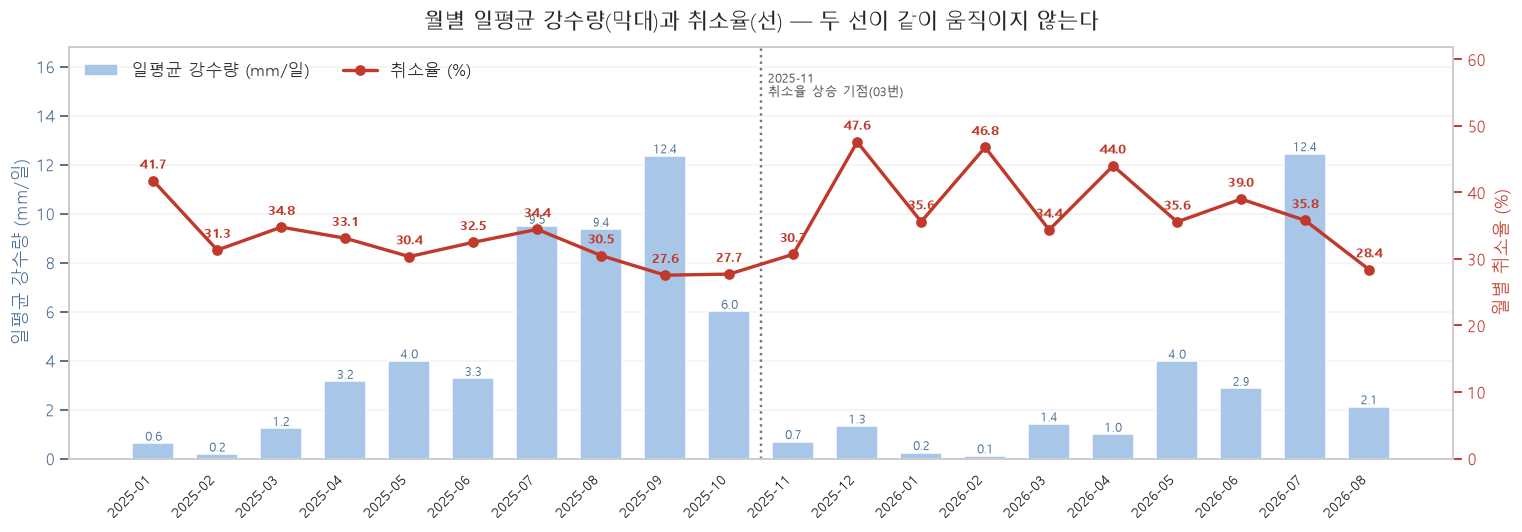

월 단위 스피어만 상관(일평균 강수량 vs 취소율): ρ = -0.4451, p = 0.0492, n = 20개월
여름(강수 최다)의 취소율이 겨울보다 오히려 낮다. 취소율은 강수가 아니라 2025-11 기점으로 움직인다.

⚠️ 위 월 단위 상관이 음수이고 p < 0.05 로 나올 수 있으나, 이것을 '비가 오면 취소가 준다' 로
   읽으면 안 된다. 20개 점의 상관일 뿐이고, 실제 정체는 '비가 많은 여름 = 취소가 적은 시기'
   라는 계절 동조다(생태학적 오류). 예약 단위로 계절을 통제한 §3-c5 CMH 와 §3-e 회귀에서는
   강수 효과가 유의하지 않다. 판정은 그쪽을 따른다.


In [30]:
# ── ③-f 그래프 4: 월별 강수량과 취소율 이중축 시계열 ────────────────────────
_m = (GA.groupby(GA.ym.astype(str))
        .agg(예약=("예약번호", "size"), 취소=("cancelled", "sum")))
_m["취소율"] = _m.취소 / _m.예약 * 100
_mw = WX.groupby("wx_ymstr").agg(월강수=("wx_rain", "sum"), 강수일=("wx_wet", "sum"), 일수=("wx_date", "size"))
_mw["일평균강수"] = _mw.월강수 / _mw.일수
_ms = _m.join(_mw)

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(_ms))
ax.bar(x, _ms.일평균강수, color="#a8c6e8", width=0.66, zorder=2, label="일평균 강수량 (mm/일)")
for xi, v in zip(x, _ms.일평균강수):
    ax.text(xi, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color="#4a6f96")
ax.set_ylabel("일평균 강수량 (mm/일)", color="#4a6f96")
ax.tick_params(axis="y", colors="#4a6f96")
ax.set_ylim(0, _ms.일평균강수.max() * 1.35)
ax.grid(axis="y", alpha=0.25, zorder=0); ax.grid(axis="x", visible=False)

ax2 = ax.twinx()
ax2.plot(x, _ms.취소율, color=CLR_HI, marker="o", lw=2.2, zorder=4, label="취소율 (%)")
for xi, v in zip(x, _ms.취소율):
    ax2.annotate(f"{v:.1f}", (xi, v), textcoords="offset points", xytext=(0, 8),
                 ha="center", fontsize=8.5, color=CLR_HI, fontweight="bold")
ax2.set_ylabel("월별 취소율 (%)", color=CLR_HI)
ax2.tick_params(axis="y", colors=CLR_HI); ax2.grid(False)
ax2.set_ylim(0, _ms.취소율.max() * 1.30)

_pb = list(_ms.index).index("2025-11")
ax2.axvline(_pb - 0.5, color="#777777", ls=":", lw=1.6, zorder=1)
ax2.text(_pb - 0.4, _ms.취소율.max() * 1.22, "2025-11\n취소율 상승 기점(03번)",
         fontsize=8.5, color="#555555", va="top")

ax.set_xticks(x); ax.set_xticklabels(_ms.index, rotation=45, ha="right", fontsize=9)
ax.set_title("월별 일평균 강수량(막대)과 취소율(선) — 두 선이 같이 움직이지 않는다", fontsize=13.5, pad=12)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

if HAS_SP:
    _r, _p = stats.spearmanr(_ms.일평균강수, _ms.취소율)
    print(f"월 단위 스피어만 상관(일평균 강수량 vs 취소율): ρ = {_r:.4f}, p = {_p:.4f}, n = {len(_ms)}개월")
print("여름(강수 최다)의 취소율이 겨울보다 오히려 낮다. 취소율은 강수가 아니라 2025-11 기점으로 움직인다.")
print()
print("⚠️ 위 월 단위 상관이 음수이고 p < 0.05 로 나올 수 있으나, 이것을 '비가 오면 취소가 준다' 로")
print("   읽으면 안 된다. 20개 점의 상관일 뿐이고, 실제 정체는 '비가 많은 여름 = 취소가 적은 시기'")
print("   라는 계절 동조다(생태학적 오류). 예약 단위로 계절을 통제한 §3-c5 CMH 와 §3-e 회귀에서는")
print("   강수 효과가 유의하지 않다. 판정은 그쪽을 따른다.")

---

# ④ 자리 회복 불가 취소와 날씨

02·03번에서 정의한 **"자리를 되살릴 수 없는 취소 315건"**:

| 구분 | 건수 | 정의 |
|---|---|---|
| 방문 시각이 지난 뒤 취소 | 133 | `gap_h < 0` |
| 방문 2시간 이내 취소 | 182 | `0 <= gap_h <= 2` |
| **합계** | **315** | `gap_h <= 2` |

**여기가 진짜 손실이다.** 이 315건의 우천일 비중을 전체 취소 1,542건과 비교한다.

- 차이가 있으면 → 날씨가 **실제 손실**을 만든다 → 개입 가치 큼
- 차이가 없으면 → 날씨는 **"일정 조정"만** 유발하고 실제 손실은 안 만든다

방문 예정일 날씨(가)와 취소 실행일 날씨(나) **둘 다** 본다.

In [31]:
# ── ④-a 자리 회복 불가 취소의 우천 비중 ─────────────────────────────────────
# 취소 1건에 날씨를 두 번 붙인다: g_* = 방문 예정일 날씨, wx_* = 취소 실행일 날씨
_WG = WX.rename(columns={c: "g_" + c for c in WX.columns if c != "wx_date"})
CX = (CANC.merge(_WG, left_on="date",  right_on="wx_date", how="left").drop(columns=["wx_date"])
           .merge(WX,  left_on="cdate", right_on="wx_date", how="left"))
assert len(CX) == len(CANC), "취소 테이블에 날씨를 붙이는 과정에서 행이 늘거나 줄었다"
assert CX.g_wx_rain.isna().sum() == 0, "방문 예정일 날씨가 없는 취소가 있다"
print(f"취소 {len(CX):,}건 · 방문 예정일 날씨 결손 0건 · "
      f"취소 실행일 날씨 결손 {int(CX.wx_rain.isna().sum())}건 "
      f"(2025-01-01 이전에 취소된 건 — 기상 데이터 범위 밖)")

CX["회복불가"] = CX.gap_h <= 2
CX["구분"] = np.where(CX.gap_h < 0, "① 방문 시각 이후 취소",
              np.where(CX.gap_h <= 2, "② 방문 2시간 이내 취소", "③ 회복 가능(2시간 초과 전)"))
_ORD = ["① 방문 시각 이후 취소", "② 방문 2시간 이내 취소", "③ 회복 가능(2시간 초과 전)"]

_t = CX.groupby("구분").agg(건수=("예약번호", "size"),
                            방문일_우천=("g_wx_wet", "sum"),
                            취소일_우천=("wx_wet", "sum"),
                            금액=("paid", "sum")).reindex(_ORD)
_t["방문일 우천비중(%)"] = _t.방문일_우천 / _t.건수 * 100
_t["취소일 우천비중(%)"] = _t.취소일_우천 / CX.groupby("구분").wx_wet.count().reindex(_ORD) * 100
_t["소표본"] = _t.건수.map(lambda n: small(n))
tbl(_t.round(2), "④-a1 취소 유형별 우천 비중 — 315건(①+②) vs 회복 가능 취소")

_all_wet = CX.g_wx_wet.mean() * 100
_irr_wet = CX[CX.회복불가].g_wx_wet.mean() * 100
print(f"전체 취소 {len(CX):,}건의 방문일 우천 비중  : {_all_wet:.2f}%")
print(f"자리 회복 불가 {int(CX.회복불가.sum())}건의 우천 비중 : {_irr_wet:.2f}%   "
      f"(차이 {_irr_wet - _all_wet:+.2f}%p)")
if HAS_SP:
    print(f"카이제곱(회복불가 여부 x 방문일 강수유무) p = "
          f"{stats.chi2_contingency(pd.crosstab(CX.회복불가, CX.g_wx_wet))[1]:.4f}")
    _sub = CX[CX.wx_wet.notna()]
    print(f"카이제곱(회복불가 여부 x 취소일 강수유무) p = "
          f"{stats.chi2_contingency(pd.crosstab(_sub.회복불가, _sub.wx_wet))[1]:.4f}")

취소 1,542건 · 방문 예정일 날씨 결손 0건 · 취소 실행일 날씨 결손 7건 (2025-01-01 이전에 취소된 건 — 기상 데이터 범위 밖)


**④-a1 취소 유형별 우천 비중 — 315건(①+②) vs 회복 가능 취소**

,건수,방문일_우천,취소일_우천,금액,방문일 우천비중(%),취소일 우천비중(%),소표본
구분,,,,,,,
① 방문 시각 이후 취소,133,34,33,16854000,25.56,24.81203,
② 방문 2시간 이내 취소,182,63,63,17813000,34.62,34.615385,
③ 회복 가능(2시간 초과 전),1227,369,359,144304000,30.07,29.42623,


전체 취소 1,542건의 방문일 우천 비중  : 30.22%
자리 회복 불가 315건의 우천 비중 : 30.79%   (차이 +0.57%p)
카이제곱(회복불가 여부 x 방문일 강수유무) p = 0.8575
카이제곱(회복불가 여부 x 취소일 강수유무) p = 0.7683


In [32]:
# ── ④-b 강수구분별로 자리 회복 불가 취소가 더 나오는가 ─────────────────────
_t = GA.assign(회복불가=GA.예약번호.isin(CX[CX.회복불가].예약번호)).groupby("wx_rbin", observed=False).agg(
    예약건수=("예약번호", "size"), 취소=("cancelled", "sum"), 회복불가=("회복불가", "sum"))
_t["취소율(%)"]         = _t.취소 / _t.예약건수 * 100
_t["회복불가율(%)"]      = _t.회복불가 / _t.예약건수 * 100
_t["취소 중 회복불가(%)"] = _t.회복불가 / _t.취소 * 100
_t["소표본"] = _t.예약건수.map(lambda n: small(n))
tbl(_t.round(3), "④-b 강수구분별 자리 회복 불가 취소 (가) — 분모는 그날 방문 예정이던 전체 예약")

_days = int(WX.wx_wet.sum())
_irrd = CX[CX.회복불가]
print(f"자리 회복 불가 {len(_irrd)}건 · 금액 {_irrd.paid.sum():,}원 · 월평균 {len(_irrd)/N_MONTHS:.1f}건")
print(f"  그중 방문일에 비가 온 건: {int(_irrd.g_wx_wet.sum())}건 "
      f"({_irrd.g_wx_wet.mean()*100:.2f}%) · 금액 {_irrd[_irrd.g_wx_wet].paid.sum():,}원")
print(f"  전체 기간 중 강수일 비중은 {WX.wx_wet.mean()*100:.2f}% ({_days}일/{len(WX)}일)")
print()
print("→ 자리 회복 불가 취소의 우천 비중이 '그냥 비 온 날의 비중' 과 같다면,")
print("   비가 왔다고 해서 막판 취소가 더 나온 것이 아니라는 뜻이다.")

**④-b 강수구분별 자리 회복 불가 취소 (가) — 분모는 그날 방문 예정이던 전체 예약**

,예약건수,취소,회복불가,취소율(%),회복불가율(%),취소 중 회복불가(%),소표본
wx_rbin,,,,,,,
무강수,2989,1076,218,35.999,7.293,20.260,
약(0.1~5),709,268,55,37.800,7.757,20.522,
중(5~20),357,126,32,35.294,8.964,25.397,
강(20 초과),226,72,10,31.858,4.425,13.889,


자리 회복 불가 315건 · 금액 34,667,000원 · 월평균 15.8건
  그중 방문일에 비가 온 건: 97건 (30.79%) · 금액 10,759,000원
  전체 기간 중 강수일 비중은 30.17% (181일/600일)

→ 자리 회복 불가 취소의 우천 비중이 '그냥 비 온 날의 비중' 과 같다면,
   비가 왔다고 해서 막판 취소가 더 나온 것이 아니라는 뜻이다.


---

# ⑤ 폭염 43일 · 적설 24일 · 강풍 · 한파 4일

| 조건 | 일수 | 표본 | 다루는 방식 |
|---|---|---|---|
| 폭염 (최고 33℃ 이상) | 43 | 충분 | 통계. **같은 여름철 평상일과 비교** |
| 적설 (신적설 > 0) | 24 | ⚠️ 부족 | **같은 겨울철 무설일과 비교**. 전부 12~4월에 몰려 있음 |
| 강풍 (최대풍속 상위 10% 초과) | 실측 | 충분 | 통계 |
| 한파 (최저 −12℃ 이하) | 4 | ⚠️ 심각히 부족 | **사례 나열만** |

**⚠️ 전체 평균과 비교하면 안 된다.** 폭염일을 20개월 전체 평균과 비교하면
여름의 계절 효과가 폭염 효과로 둔갑한다. 반드시 **같은 계절 안에서** 비교한다.

## ⑤-a 폭염 — 같은 여름철(6~8월) 평상일과 비교

여름 176일 = 폭염 42일 + 평상 134일.
(폭염 43일 중 1일은 9월에 있어 가을로 분류되므로 이 비교에서 빠진다 — 아래 셀이 그 날짜를 출력한다.)

In [33]:
# ── ⑤-a1 폭염 vs 여름 평상일 ────────────────────────────────────────────────
SUMMER_M = [6, 7, 8]
WS  = WX[WX.wx_month.isin(SUMMER_M)]
GS  = GA[GA.wx_month.isin(SUMMER_M)].copy()
DS  = GS[GS.status == "이용완료"]

print(f"폭염 43일 중 여름(6~8월) 밖: {int((WX.wx_heat & ~WX.wx_month.isin(SUMMER_M)).sum())}일 "
      f"→ {WX[WX.wx_heat & ~WX.wx_month.isin(SUMMER_M)].wx_date.dt.date.tolist()}")

def condition_compare(wsub, gsub, flag, names, label, note=""):
    dsub = gsub[gsub.status == "이용완료"]
    days = wsub.groupby(flag).size()
    t = pd.DataFrame({
        "일수":        days,
        "예약 건수":   gsub.groupby(flag).size(),
        "취소 건수":   gsub.groupby(flag).cancelled.sum(),
        "완료 건수":   dsub.groupby(flag).size(),
        "완료 매출":   dsub.groupby(flag).paid.sum(),
        "객단가 중앙값": dsub.groupby(flag).paid.median(),
    })
    t["취소율(%)"] = t["취소 건수"] / t["예약 건수"] * 100
    t["예약/일"]   = t["예약 건수"] / t.일수
    t["완료/일"]   = t["완료 건수"] / t.일수
    t["매출/일"]   = t["완료 매출"] / t.일수
    t.index = [names[i] for i in t.index]
    t["소표본(일수)"] = t.일수.map(lambda n: small(n))
    cols = ["일수", "예약 건수", "예약/일", "완료/일", "매출/일", "객단가 중앙값", "취소율(%)", "소표본(일수)"]
    tbl(t[cols].round(2), label)
    if HAS_SP and gsub[flag].nunique() > 1:
        print(f"카이제곱(조건 x 취소여부) p = {stats.chi2_contingency(pd.crosstab(gsub[flag], gsub.cancelled))[1]:.4f}")
    if note:
        print(note)
    return t

T_HEAT = condition_compare(WS, GS, "wx_heat", {False: "여름 평상일", True: "폭염일(33℃ 이상)"},
                           "⑤-a1 폭염일 vs 여름 평상일 — 6~8월 안에서만 비교")

_NUMC = ["일수", "예약 건수", "예약/일", "완료/일", "매출/일", "객단가 중앙값", "취소율(%)"]
_d = T_HEAT.loc["폭염일(33℃ 이상)", _NUMC] - T_HEAT.loc["여름 평상일", _NUMC]
print(f"\n취소율 차이 {_d['취소율(%)']:+.2f}%p · 완료/일 차이 {_d['완료/일']:+.2f}건 "
      f"({T_HEAT.loc['폭염일(33℃ 이상)','완료/일'] / T_HEAT.loc['여름 평상일','완료/일'] * 100 - 100:+.1f}%)")
print("취소율은 차이가 없는데 완료/일이 낮다 → 취소가 는 게 아니라 애초에 예약이 적었다는 뜻이다.")
print("⑤-a4 에서 이것이 폭염 때문인지 아닌지를 리드타임으로 갈라 검증한다.")

폭염 43일 중 여름(6~8월) 밖: 1일 → [datetime.date(2025, 9, 5)]


**⑤-a1 폭염일 vs 여름 평상일 — 6~8월 안에서만 비교**

,일수,예약 건수,예약/일,완료/일,매출/일,객단가 중앙값,취소율(%),소표본(일수)
여름 평상일,134,964,7.19,4.72,539276.12,100000.0,34.23,
폭염일(33℃ 이상),42,243,5.79,3.76,443619.05,100000.0,32.51,


카이제곱(조건 x 취소여부) p = 0.6664

취소율 차이 -1.72%p · 완료/일 차이 -0.96건 (-20.4%)
취소율은 차이가 없는데 완료/일이 낮다 → 취소가 는 게 아니라 애초에 예약이 적었다는 뜻이다.
⑤-a4 에서 이것이 폭염 때문인지 아닌지를 리드타임으로 갈라 검증한다.


In [34]:
# ── ⑤-a2 요일 구성 보정 — 폭염일이 특정 요일에 몰렸을 수 있다 ──────────────
_dw = pd.crosstab(WS.wx_dow_ko, WS.wx_heat).reindex(DOW_KO)
_dw.columns = ["여름 평상일", "폭염일"]
_dw["평상 구성비(%)"] = _dw["여름 평상일"] / _dw["여름 평상일"].sum() * 100
_dw["폭염 구성비(%)"] = _dw["폭염일"] / _dw["폭염일"].sum() * 100
tbl(_dw.round(2), "⑤-a2 폭염일의 요일 구성 — 전체 여름과 비슷하면 요일 교란은 아니다")

# 요일 가중 보정 완료/일
_per = (DS.groupby(["wx_heat", "wx_dow"]).size().unstack(0)
          / WS.groupby(["wx_heat", "wx_dow"]).size().unstack(0))
_per.index = [DOW_KO[i] for i in _per.index]
_per.columns = ["여름 평상일", "폭염일"]
tbl(_per.round(2), "⑤-a3 여름 요일별 완료/일")

_wgt = WS.wx_dow.value_counts(normalize=True).sort_index().values
_adj = {c: float(np.nansum(_per[c].values * _wgt)) for c in _per.columns}
print(f"요일 가중 보정 완료/일 — 평상일 {_adj['여름 평상일']:.3f} · 폭염일 {_adj['폭염일']:.3f} "
      f"({_adj['폭염일']/_adj['여름 평상일']*100-100:+.1f}%)")
print("보정 전(원값)과 거의 같다 → 요일 쏠림 때문이 아니다.")

# 연도별로도 나눠 본다 (2026-08 은 23일치라 착시가 생길 수 있다)
_yr = []
for yr in [2025, 2026]:
    wy = WS[WS.wx_date.dt.year == yr]
    dy = DS[DS.use_dt.dt.year == yr]
    for f, nm in [(True, "폭염일"), (False, "평상일")]:
        nd = int((wy.wx_heat == f).sum())
        _yr.append({"연도": yr, "구분": nm, "일수": nd,
                    "완료/일": len(dy[dy.wx_heat == f]) / nd if nd else np.nan,
                    "취소율(%)": GS[(GS.use_dt.dt.year == yr) & (GS.wx_heat == f)].cancelled.mean() * 100})
_yr = pd.DataFrame(_yr)
_yr["소표본(일수)"] = _yr.일수.map(lambda n: small(n))
tbl(_yr.round(2), "⑤-a3b 연도별로 나눠도 같은 방향인가")

**⑤-a2 폭염일의 요일 구성 — 전체 여름과 비슷하면 요일 교란은 아니다**

,여름 평상일,폭염일,평상 구성비(%),폭염 구성비(%)
wx_dow_ko,,,,
월,19,6,14.18,14.29
화,18,7,13.43,16.67
수,21,4,15.67,9.52
목,18,7,13.43,16.67
금,19,6,14.18,14.29
토,20,5,14.93,11.90
일,19,7,14.18,16.67


**⑤-a3 여름 요일별 완료/일**

,여름 평상일,폭염일
월,4.53,5.00
화,4.67,3.71
수,4.95,2.50
목,4.50,4.00
금,5.68,4.83
토,4.70,3.20
일,4.00,2.71


요일 가중 보정 완료/일 — 평상일 4.714 · 폭염일 3.703 (-21.4%)
보정 전(원값)과 거의 같다 → 요일 쏠림 때문이 아니다.


**⑤-a3b 연도별로 나눠도 같은 방향인가**

,연도,구분,일수,완료/일,취소율(%),소표본(일수)
0,2025,폭염일,27,3.37,31.58,⚠소표본
1,2025,평상일,65,4.20,32.68,
2,2026,폭염일,15,4.47,33.64,⚠소표본
3,2026,평상일,69,5.22,35.37,


In [35]:
# ── ⑤-a4 ★ 반증 검정 — 폭염일 예약 감소가 '폭염 때문' 인가 ─────────────────
# 논리: 예약은 방문일보다 '먼저' 잡힌다. 그날이 33℃ 넘을 것을 알 수 있는 건
#       예보가 나오는 며칠 전부터다. 만약 폭염 효과가 진짜라면
#       짧은 리드타임(당일~3일)에서 나타나야 하고, 2주 전 예약에는 나타날 수 없다.
#       거꾸로 나오면 그건 폭염 효과가 아니라 시기 교란이다.
if HAS_SM:
    _cnt_all = R.groupby("date").size()
    WSx = WS.copy()
    WSx["heat"]  = WSx.wx_heat.astype(int)
    WSx["n_res"] = WSx.wx_date.map(_cnt_all).fillna(0).astype(int)
    WSx["ymstr"] = WSx.wx_ymstr
    WSx["dowk"]  = WSx.wx_dow_ko

    _m = smf.glm("n_res ~ heat + C(ymstr) + C(dowk)", data=WSx, family=sm.families.Poisson()).fit()
    _irr = float(np.exp(_m.params["heat"])); _ci = np.exp(_m.conf_int().loc["heat"])
    print("⑤-a4a 여름 일별 '예약 건수' ~ 폭염 (Poisson, 월·요일 통제)")
    print(f"  발생률비(IRR) = {_irr:.4f}  95%CI [{_ci.iloc[0]:.4f}, {_ci.iloc[1]:.4f}]  "
          f"p = {_m.pvalues['heat']:.4f}   (일수 {int(_m.nobs)}일)")
    print(f"  → 폭염일에 잡혀 있던 예약이 {(1-_irr)*100:.1f}% 적었다.\n")

    _rows = []
    for lb in LEAD_LABELS:
        c = R[R.lead_bin == lb].groupby("date").size()
        WSx["c"] = WSx.wx_date.map(c).fillna(0).astype(int)
        mm = smf.glm("c ~ heat + C(ymstr) + C(dowk)", data=WSx, family=sm.families.Poisson()).fit()
        _rows.append({"리드타임": lb,
                      "폭염일 예약/일": WSx[WSx.heat == 1].c.mean(),
                      "평상일 예약/일": WSx[WSx.heat == 0].c.mean(),
                      "IRR": float(np.exp(mm.params["heat"])),
                      "p값": float(mm.pvalues["heat"]),
                      "여름 총건수": int(WSx.c.sum()),
                      "폭염일 총건수": int(WSx[WSx.heat == 1].c.sum())})
    _lt = pd.DataFrame(_rows)
    _lt["유의(p<0.05)"] = np.where(_lt.p값 < 0.05, "★", "")
    _lt["소표본"] = _lt["폭염일 총건수"].map(lambda n: small(n))
    tbl(_lt.round(4), "⑤-a4b ★ 리드타임 구간별 폭염 효과 — 예보로 설명되는가")

    print("판정 논리:")
    print("  · 예보를 보고 피했다면 → '6시간 미만'·'6~24시간'·'1~3일' 에서 IRR 이 낮아야 한다.")
    print("  · 실제로는 그 구간들이 1.0 근처이고, 유일하게 유의한 것은 '1~2주' 구간이다.")
    print("  · 2주 전에는 그날이 33℃ 넘을지 알 수 있는 예보가 존재하지 않는다(중기예보 최대 10일).")
    print("  · 게다가 6개 구간을 모두 검정했으므로 하나가 우연히 p<0.05 가 될 확률은 "
          f"{(1-0.95**6)*100:.0f}% 다.")
    print("  → 폭염일 예약 감소는 '폭염을 보고 피한 것' 으로 설명되지 않는다.")
    print("     폭염일이 예약이 원래 적은 시기(한여름 휴가철)와 겹친 것으로 보는 편이 타당하다.")
else:
    print("⚠️ statsmodels 없음 — ⑤-a4 Poisson 반증 검정을 건너뛴다.")
    _rows = []
    for lb in LEAD_LABELS:
        c = R[R.lead_bin == lb].groupby("date").size()
        WSx = WS.copy(); WSx["c"] = WSx.wx_date.map(c).fillna(0)
        _rows.append({"리드타임": lb,
                      "폭염일 예약/일": WSx[WSx.wx_heat].c.mean(),
                      "평상일 예약/일": WSx[~WSx.wx_heat].c.mean()})
    _lt = pd.DataFrame(_rows)
    _lt["비(폭염/평상)"] = _lt["폭염일 예약/일"] / _lt["평상일 예약/일"]
    tbl(_lt.round(3), "⑤-a4b 리드타임 구간별 폭염일 예약/일 (검정 없이 원값만)")

⑤-a4a 여름 일별 '예약 건수' ~ 폭염 (Poisson, 월·요일 통제)
  발생률비(IRR) = 0.8283  95%CI [0.7094, 0.9670]  p = 0.0171   (일수 176일)
  → 폭염일에 잡혀 있던 예약이 17.2% 적었다.



**⑤-a4b ★ 리드타임 구간별 폭염 효과 — 예보로 설명되는가**

,리드타임,폭염일 예약/일,평상일 예약/일,IRR,p값,여름 총건수,폭염일 총건수,유의(p<0.05),소표본
0,6시간 미만,1.4286,1.4851,0.9328,0.6684,259,60,,
1,6~24시간,1.1667,1.5224,0.7698,0.1332,253,49,,
2,1~3일,1.3333,1.6418,0.8034,0.1846,276,56,,
3,3~7일,1.0714,1.1119,1.0688,0.7277,194,45,,
4,1~2주,0.3571,0.9030,0.4740,0.0105,136,15,★,⚠소표본
5,2주 이상,0.4286,0.5299,0.8287,0.5150,89,18,,⚠소표본


판정 논리:
  · 예보를 보고 피했다면 → '6시간 미만'·'6~24시간'·'1~3일' 에서 IRR 이 낮아야 한다.
  · 실제로는 그 구간들이 1.0 근처이고, 유일하게 유의한 것은 '1~2주' 구간이다.
  · 2주 전에는 그날이 33℃ 넘을지 알 수 있는 예보가 존재하지 않는다(중기예보 최대 10일).
  · 게다가 6개 구간을 모두 검정했으므로 하나가 우연히 p<0.05 가 될 확률은 26% 다.
  → 폭염일 예약 감소는 '폭염을 보고 피한 것' 으로 설명되지 않는다.
     폭염일이 예약이 원래 적은 시기(한여름 휴가철)와 겹친 것으로 보는 편이 타당하다.


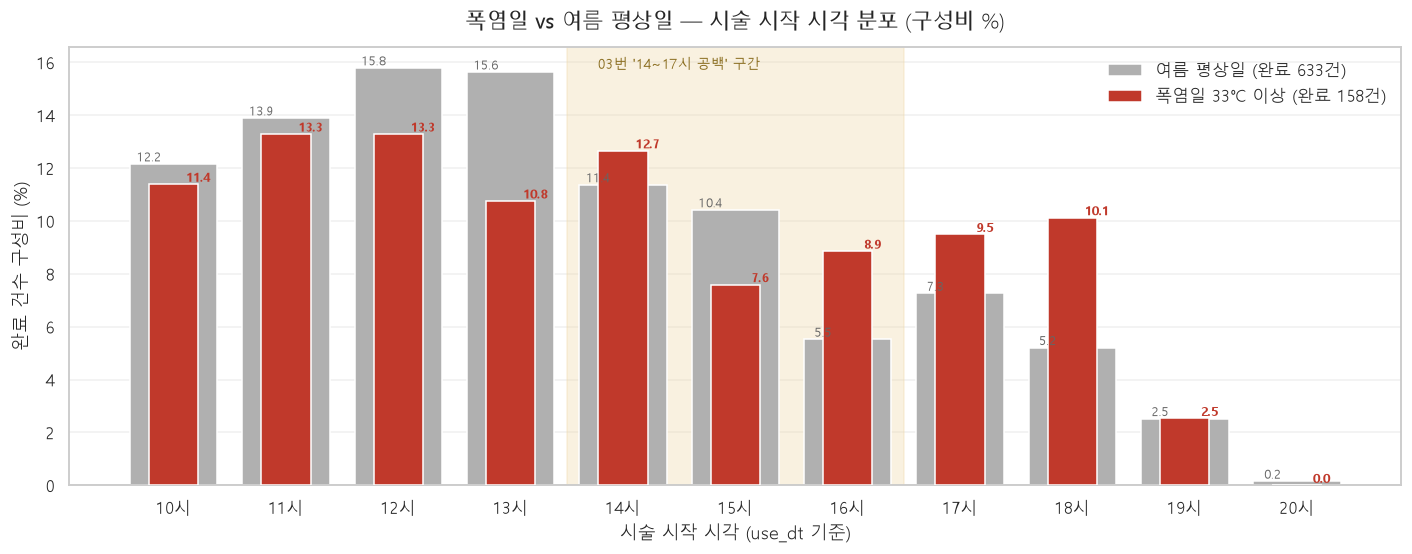

시작 시각 중앙값 — 여름 평상일 13시 · 폭염일 14시  (평균 13.40 vs 13.84)
카이제곱(시작시각 x 폭염) p = 0.2763
⚠️ 시각대 11개 중 11개에서 폭염일 쪽 완료 건수가 30건 미만이다 (폭염일 완료 158건을 11개 시각에 나눈 것이라 당연하다). 개별 시각의 차이는 해석하지 말고 분포 전체의 형태만 볼 것.
탈색은 3~4시간 앉아 있어야 해 한여름 낮을 피할 법한데, 분포가 통계적으로 갈리지 않는다.


In [36]:
# ── ⑤-a5 그래프 5: 폭염일 vs 여름 평상일 시작 시각 분포 (겹친 막대) ────────
_hh = pd.crosstab(DS.hour, DS.wx_heat, normalize="columns") * 100
_hn = pd.crosstab(DS.hour, DS.wx_heat)
_hh = _hh.reindex(sorted(_hh.index))
_hn = _hn.reindex(_hh.index)

fig, ax = plt.subplots(figsize=(13, 5.2))
x = np.arange(len(_hh))
ax.bar(x, _hh[False], width=0.78, color=CLR_GRAY, label=f"여름 평상일 (완료 {int(_hn[False].sum()):,}건)", zorder=2)
ax.bar(x, _hh[True],  width=0.44, color=CLR_HI,   label=f"폭염일 33℃ 이상 (완료 {int(_hn[True].sum()):,}건)", zorder=3)
for xi, (a, b) in enumerate(zip(_hh[False], _hh[True])):
    ax.text(xi - 0.22, a, f"{a:.1f}", ha="center", va="bottom", fontsize=8, color="#666666")
    ax.text(xi + 0.22, b, f"{b:.1f}", ha="center", va="bottom", fontsize=8, color=CLR_HI, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels([f"{h}시" for h in _hh.index])
ax.set_xlabel("시술 시작 시각 (use_dt 기준)"); ax.set_ylabel("완료 건수 구성비 (%)")
ax.set_title("폭염일 vs 여름 평상일 — 시술 시작 시각 분포 (구성비 %)", fontsize=13.5, pad=12)
ax.axvspan(list(_hh.index).index(14) - 0.5, list(_hh.index).index(17) - 0.5,
           color="#f0d9a8", alpha=0.35, zorder=1)
ax.text(list(_hh.index).index(15) - 0.5, ax.get_ylim()[1] * 0.95, "03번 '14~17시 공백' 구간",
        ha="center", fontsize=9, color="#8a6d1f")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="y", alpha=0.3, zorder=0); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

_n_small = int((_hn.min(axis=1) < 30).sum())
print(f"시작 시각 중앙값 — 여름 평상일 {DS[~DS.wx_heat].hour.median():.0f}시 · "
      f"폭염일 {DS[DS.wx_heat].hour.median():.0f}시  "
      f"(평균 {DS[~DS.wx_heat].hour.mean():.2f} vs {DS[DS.wx_heat].hour.mean():.2f})")
if HAS_SP:
    print(f"카이제곱(시작시각 x 폭염) p = {stats.chi2_contingency(_hn)[1]:.4f}")
print(f"⚠️ 시각대 {len(_hn)}개 중 {_n_small}개에서 폭염일 쪽 완료 건수가 30건 미만이다 "
      f"(폭염일 완료 {int(_hn[True].sum())}건을 {len(_hn)}개 시각에 나눈 것이라 당연하다). "
      f"개별 시각의 차이는 해석하지 말고 분포 전체의 형태만 볼 것.")
print("탈색은 3~4시간 앉아 있어야 해 한여름 낮을 피할 법한데, 분포가 통계적으로 갈리지 않는다.")

In [37]:
# ── ⑤-a6 폭염일의 대표시술 구성 ─────────────────────────────────────────────
_ct = pd.crosstab(DS.rep_cat, DS.wx_heat)
_mix = (pd.crosstab(DS.rep_cat, DS.wx_heat, normalize="columns") * 100)
_mix.columns = ["여름 평상일(%)", "폭염일(%)"]
_mix["차이(%p)"] = _mix["폭염일(%)"] - _mix["여름 평상일(%)"]
_mix["평상 건수"] = _ct[False]; _mix["폭염 건수"] = _ct[True]
_mix["소표본"] = _mix["폭염 건수"].map(lambda n: small(n))
_ord = [c for c in PRIORITY if c in _mix.index]
tbl(_mix.reindex(_ord).round(2), "⑤-a6 폭염일 대표시술 구성 — 여름 평상일 대비")
if HAS_SP:
    print(f"카이제곱(대표시술 x 폭염) p = {stats.chi2_contingency(_ct)[1]:.4f}")
print(f"탈색 비중: 여름 평상일 {_mix.loc['탈색','여름 평상일(%)']:.2f}% vs "
      f"폭염일 {_mix.loc['탈색','폭염일(%)']:.2f}%  ({_mix.loc['탈색','차이(%p)']:+.2f}%p)")
print("한여름 폭염이라고 해서 긴 시술을 피하지 않는다. 시술 구성이 사실상 그대로다.")

**⑤-a6 폭염일 대표시술 구성 — 여름 평상일 대비**

,여름 평상일(%),폭염일(%),차이(%p),평상 건수,폭염 건수,소표본
rep_cat,,,,,,
탈색,61.30,60.13,-1.17,388,95,
펌,5.53,6.96,1.43,35,11,⚠소표본
염색,24.01,21.52,-2.49,152,34,
컷,6.95,8.86,1.91,44,14,⚠소표본
클리닉,1.26,0.63,-0.63,8,1,⚠소표본
스타일링,0.32,0.00,-0.32,2,0,⚠소표본
확인필요,0.63,1.90,1.27,4,3,⚠소표본


카이제곱(대표시술 x 폭염) p = 0.5865
탈색 비중: 여름 평상일 61.30% vs 폭염일 60.13%  (-1.17%p)
한여름 폭염이라고 해서 긴 시술을 피하지 않는다. 시술 구성이 사실상 그대로다.


## ⑤-b 적설 24일 — 같은 겨울철 무설일과 비교

⚠️ **24일은 30일 미만이라 소표본**이다. 게다가 적설은 전부 **12~4월**에 몰려 있어
여름을 포함해 비교하면 계절 효과를 적설 효과로 오독한다.
**적설이 실제로 발생한 월(12·1·2·3·4월)** 안에서만 비교한다.

In [38]:
# ── ⑤-b 적설 vs 같은 시기 무설일 ────────────────────────────────────────────
_sm = sorted(WX[WX.wx_snowy].wx_month.unique().tolist())
print(f"적설일이 발생한 월: {_sm}  (일수 {int(WX.wx_snowy.sum())}일)")
print("월별 적설일:", WX[WX.wx_snowy].wx_month.value_counts().sort_index().to_dict())

WSN = WX[WX.wx_month.isin(_sm)]
GSN = GA[GA.wx_month.isin(_sm)].copy()
T_SNOW = condition_compare(WSN, GSN, "wx_snowy", {False: "무설일", True: "적설일(신적설>0)"},
                           f"⑤-b1 적설일 vs 같은 시기(12·1·2·3·4월) 무설일")
print(f"⚠️ 적설일 {int(T_SNOW.loc['적설일(신적설>0)','일수'])}일 — 30일 미만 소표본. "
      f"아래 수치는 방향만 참고할 것.")

# 적설량 구간으로도 (더 많이 오면 다른가)
_sn = GSN[GSN.wx_snowy].copy()
if len(_sn):
    _sn["적설구간"] = pd.cut(_sn.wx_snow, [0, 1, 3, np.inf], labels=["0~1cm", "1~3cm", "3cm 초과"])
    _t = _sn.groupby("적설구간", observed=False).agg(
        예약=("예약번호", "size"), 취소=("cancelled", "sum"), 일수=("date", "nunique"))
    _t["취소율(%)"] = _t.취소 / _t.예약 * 100
    _t["소표본"] = _t.예약.map(lambda n: small(n))
    tbl(_t.round(2), "⑤-b2 적설량 구간별 (전부 소표본 — 사례 참고용)")

적설일이 발생한 월: [1, 2, 3, 4, 12]  (일수 24일)
월별 적설일: {1: 10, 2: 4, 3: 5, 4: 2, 12: 3}


**⑤-b1 적설일 vs 같은 시기(12·1·2·3·4월) 무설일**

,일수,예약 건수,예약/일,완료/일,매출/일,객단가 중앙값,취소율(%),소표본(일수)
무설일,247,1928,7.81,4.69,527425.1,100000.0,39.89,
적설일(신적설>0),24,168,7.00,4.42,494062.5,100000.0,36.90,⚠소표본


카이제곱(조건 x 취소여부) p = 0.4994
⚠️ 적설일 24일 — 30일 미만 소표본. 아래 수치는 방향만 참고할 것.


**⑤-b2 적설량 구간별 (전부 소표본 — 사례 참고용)**

,예약,취소,일수,취소율(%),소표본
적설구간,,,,,
0~1cm,62,22,11,35.48,
1~3cm,65,25,6,38.46,
3cm 초과,41,15,7,36.59,


## ⑤-c 강풍 — 최대풍속 상위 10% 초과

일수가 30일을 넘으므로 통계로 다룬다. 계절 쏠림이 있는지 먼저 확인한다.

In [39]:
# ── ⑤-c 강풍 ────────────────────────────────────────────────────────────────
print(f"강풍 임계 {WIND_Q90} m/s 초과 → {int(WX.wx_windy.sum())}일")
_ws = pd.crosstab(WX.wx_season, WX.wx_windy).reindex(SEASON_ORDER)
_ws.columns = ["평상일", "강풍일"]
_ws["강풍일 비율(%)"] = _ws.강풍일 / _ws.sum(axis=1) * 100
tbl(_ws.round(2), "⑤-c1 강풍일의 계절 분포 — 쏠려 있으면 계절 보정이 필요하다")

T_WIND = condition_compare(WX, GA, "wx_windy", {False: "평상일", True: f"강풍일(>{WIND_Q90}m/s)"},
                           "⑤-c2 강풍일 vs 평상일 (전체 기간)")

# 계절 보정 — standardize() 는 wx_rbin/RAIN_LABELS 전용이라 여기서는 계절별 층화로 직접 본다
_cell = (GA.groupby(["wx_season", "wx_windy"], observed=False)
           .agg(n=("예약번호", "size"), c=("cancelled", "sum")))
_cell["취소율(%)"] = _cell.c / _cell.n * 100
_p = _cell.reset_index().pivot(index="wx_season", columns="wx_windy", values="취소율(%)").reindex(SEASON_ORDER)
_n = _cell.reset_index().pivot(index="wx_season", columns="wx_windy", values="n").reindex(SEASON_ORDER)
_p.columns = ["평상일 취소율(%)", "강풍일 취소율(%)"]; _n.columns = ["평상 n", "강풍 n"]
_out = _p.join(_n)
_out["차이(%p)"] = _out["강풍일 취소율(%)"] - _out["평상일 취소율(%)"]
_out["소표본"] = _out["강풍 n"].map(lambda n: small(n) if pd.notna(n) else "⚠소표본")
tbl(_out.round(2), "⑤-c3 계절별로 나눈 강풍 효과 — 방향이 일정하지 않으면 우연이다")

강풍 임계 6.2 m/s 초과 → 55일


**⑤-c1 강풍일의 계절 분포 — 쏠려 있으면 계절 보정이 필요하다**

,평상일,강풍일,강풍일 비율(%)
wx_season,,,
봄,162,22,11.96
여름,163,13,7.39
가을,87,4,4.40
겨울,133,16,10.74


**⑤-c2 강풍일 vs 평상일 (전체 기간)**

,일수,예약 건수,예약/일,완료/일,매출/일,객단가 중앙값,취소율(%),소표본(일수)
평상일,545,3909,7.17,4.58,520019.54,100000.0,35.92,
강풍일(>6.2m/s),55,372,6.76,4.25,464818.18,100000.0,37.10,


카이제곱(조건 x 취소여부) p = 0.6918


**⑤-c3 계절별로 나눈 강풍 효과 — 방향이 일정하지 않으면 우연이다**

,평상일 취소율(%),강풍일 취소율(%),평상 n,강풍 n,차이(%p),소표본
wx_season,,,,,,
봄,36.38,32.37,1094,139,-4.01,
여름,33.66,36.56,1114,93,2.90,
가을,28.01,55.56,539,18,27.54,⚠소표본
겨울,41.31,40.16,1162,122,-1.14,


## ⑤-d 한파 4일 — 표본 부족, 사례 나열만

**4일은 어떤 통계도 성립하지 않는다.** 날짜와 그날의 실제 예약·취소를 그대로 적는다.
그래프도 그리지 않는다.

In [40]:
# ── ⑤-d 한파 사례 표 ────────────────────────────────────────────────────────
_cold = WX[WX.wx_cold].copy()
_rows = []
for _, w_ in _cold.iterrows():
    g = GA[GA.date == w_.wx_date]
    d = g[g.status == "이용완료"]
    _rows.append({
        "날짜": w_.wx_date.date().isoformat(),
        "요일": w_.wx_dow_ko,
        "최저기온(℃)": w_.wx_tmin,
        "최고기온(℃)": w_.wx_tmax,
        "적설(cm)": w_.wx_snow,
        "예약 건수": len(g),
        "취소 건수": int(g.cancelled.sum()),
        "취소율(%)": g.cancelled.mean() * 100 if len(g) else np.nan,
        "완료 건수": len(d),
        "완료 매출": int(d.paid.sum()),
    })
_coldt = pd.DataFrame(_rows)
tbl(_coldt.round(2), "⑤-d 한파일(최저 −12℃ 이하) 4일 — 개별 사례 (통계 아님)")
print(f"참고: 겨울(12~2월) 전체 평균 예약/일 "
      f"{len(GA[GA.wx_season=='겨울']) / int((WX.wx_season=='겨울').sum()):.2f}건 · "
      f"취소율 {GA[GA.wx_season=='겨울'].cancelled.mean()*100:.2f}%")
print("⚠️ 4일로는 어떤 판단도 할 수 없다. 표는 기록용이다.")

**⑤-d 한파일(최저 −12℃ 이하) 4일 — 개별 사례 (통계 아님)**

,날짜,요일,최저기온(℃),최고기온(℃),적설(cm),예약 건수,취소 건수,취소율(%),완료 건수,완료 매출
0,2025-01-10,금,-12.2,-1.7,0.0,15,6,40.00,9,691000
1,2026-01-21,수,-12.2,-5.2,0.0,8,4,50.00,4,489000
2,2026-01-22,목,-13.2,-4.2,0.0,7,2,28.57,5,793000
3,2026-02-08,일,-12.4,-3.5,0.0,6,2,33.33,4,328000


참고: 겨울(12~2월) 전체 평균 예약/일 8.62건 · 취소율 41.20%
⚠️ 4일로는 어떤 판단도 할 수 없다. 표는 기록용이다.


---

# ⑥ 지각 · 노쇼와 날씨

## ⑥-a 시간 조정 표현이 있는 예약

03번에서 **"예약 시간을 바꾸고 싶다 / 늦을 것 같다"** 유형이 **230건**으로 챗봇 FAQ 2위였다.
그 230건은 세 갈래의 합이다 — **요청사항 '시간 조정' 태그 + 취소 재분류 '지각·도착 불가' + 취소사유 '시간변경'**.
여기서는 **03번의 규칙을 글자 그대로 복사**해 재현하고(재현 안 되면 assert 로 정지), 날씨와 교차한다.

In [41]:
# ── ⑥-a1 03번 규칙 그대로 복사해 230건 재현 ────────────────────────────────
# (02번 ①-c / 03번 §0-5 의 1차 분류)
def cancel_reason_l1(s):
    if not isinstance(s, str) or not s.strip():
        return "(사유 미기재)"
    t = re.sub(r"\s+", "", s)
    if re.search(r"(날짜|일정|요일)(변경|변동|수정|바꿈)", t): return "날짜변경"
    if re.search(r"시간(변경|변동|수정|바꿈)", t):            return "시간변경"
    if re.search(r"(재예약|다시예약|예약변경|예약을다시)", t): return "다시예약"
    return "기타"

# (03번 ②-a1 요청사항 '시간 조정' 태그)
REQ_TADJ = (r"도착|늦(게|을|지|어|겠)|일찍|앞당|미루|미뤄|시간\s*(변경|조정|바꾸|맞|이동)|시간대\s*변경|"
            r"\d\s*시\s*\d*\s*분?\s*(까지|쯤|경)|\d시\s*반|까지\s*(가|갈|올|와|끝|도착)|끝나(야|길|게)|시간\s*내|"
            r"빠른\s*시간|빠르게\s*가|먼저\s*가")

# (03번 ②-c1 취소사유 '기타' 재분류 중 '지각·도착 불가' / '교통·날씨')
CANC_L2_RULES = [
    ("매장 측 사유",     r"매장\s*휴무|휴무|업체|판매자|다음에\s*오세요|다시\s*잡고|반려|비추\s*후기|비추후기|예의|선생님.{0,8}안|삭제할게"),
    ("변심·재고",        r"변심|성급|고민|하기\s*싫|생각해|충동|안\s*하기|더\s*있다가|일주일만"),
    ("건강·질병",        r"독감|코로나|장염|감기|아파|아프|몸\s*(이|상태|너무)|병원|입원|수술|진료|치료|건강|두피|환자|퇴원"),
    ("예약 실수·오입력", r"잘못|착오|실수|오기입|오입력|중복|반복|오류|잘\s*못|표기\s*오|불충분|부실|위치\s*착각|시범"),
    ("시술·메뉴 변경",   r"시술|메뉴|항목|선택\s*변경|선택변경|커트로|디자이너\s*변경|무한탈색|뿌탈|염색|탈색"),
    ("결제수단 변경",    r"결제"),
    ("지각·도착 불가",   r"늦|도착|못\s*(가|갈|올|와)|못가|못갈|지연|출발"),
    ("교통·날씨",        r"비가|비\s*온|눈이|차가\s*막|교통|사고|날씨"),
    ("개인 일정·약속",   r"일정|스케|약속|급한|급히|급\s|갑자기|갑작|개인\s*(사정|사유|일정)|개인사정|개인사유|출근|회사|업무|출장|학교|학원|알바|졸업|여행|비행|항공|집안|용무|파토|일이\s*생|일\s*때문"),
    ("날짜 변경(누락분)", r"날짜|날쩌|닐짜|날\s*짜|일자|예약일|예약\s*일|다른\s*날|담주|다음\s*주|내일|모레|요일|옮|다음달|이후로\s*변경|일시\s*변경|더\s*빠른"),
    ("시간 변경(누락분)", r"시간|시각|타임|\d\s*시|시간대|여유"),
]

def _is_foreign(t):
    han = len(re.findall(r"[가-힣]", t)); cjk = len(re.findall(r"[一-鿿぀-ゟ゠-ヿ]", t))
    lat = len(re.findall(r"[A-Za-z]", t))
    if han == 0 and (cjk + lat) >= 3: return True
    return bool(re.search(r"외국인|한국어.{0,10}(못|서툴|어눌|배우)|번역|파파고|Translator|English|Chinese|"
                          r"일본에서\s*살|한국\s*국적", t))

def cancel_reason_l2(s):
    if not isinstance(s, str): s = ""
    t = re.sub(r"\s+", " ", s).strip(); bare = re.sub(r"\s+", "", t)
    if len(bare) <= 2 or not re.search(r"[가-힣A-Za-z0-9一-鿿]", bare): return "무의미·무정보 입력"
    if _is_foreign(t): return "외국어"
    for name, pat in CANC_L2_RULES:
        if re.search(pat, t): return name
    if re.search(r"죄송|감사|취소합니다|^취소$|미확인", t): return "단순 사과·무정보"
    return "기타(잔여)"

CX["l1"] = CX.취소사유.map(cancel_reason_l1)
_etc = CX[CX.l1 == "기타"].copy()
assert len(_etc) == 326, f"취소사유 '기타' 가 326건이 아니다: {len(_etc)}"
_etc["l2"] = _etc.취소사유.map(cancel_reason_l2)

SET_REQ  = set(R[R.요청사항.fillna("").astype(str).str.contains(REQ_TADJ, regex=True)].예약번호)
SET_LATE = set(_etc[_etc.l2 == "지각·도착 불가"].예약번호)
SET_TIME = set(CX[CX.l1 == "시간변경"].예약번호)
SET_WTHR = set(_etc[_etc.l2 == "교통·날씨"].예약번호)

_comp = pd.DataFrame([
    {"구성요소": "요청사항 '시간 조정' 태그", "건수": len(SET_REQ),  "출처": "03번 ②-a1"},
    {"구성요소": "취소 재분류 '지각·도착 불가'", "건수": len(SET_LATE), "출처": "03번 ②-c1"},
    {"구성요소": "취소사유 '시간변경'",        "건수": len(SET_TIME), "출처": "02번 ①-c"},
    {"구성요소": "— 단순 합",                 "건수": len(SET_REQ) + len(SET_LATE) + len(SET_TIME), "출처": "03번 FAQ 2위 = 230"},
    {"구성요소": "— 합집합(중복 제거)",        "건수": len(SET_REQ | SET_LATE | SET_TIME), "출처": ""},
])
_comp["소표본"] = _comp.건수.map(lambda n: small(n))
tbl(_comp, "⑥-a1 '시간 조정' 230건 재현 — 03번 FAQ 2위와 대조")
assert len(SET_REQ) + len(SET_LATE) + len(SET_TIME) == 230, "03번의 230건이 재현되지 않는다"
print("230건 재현 성공. 합집합이 229인 것은 두 갈래에 동시에 걸린 예약이 1건 있기 때문이다.")

**⑥-a1 '시간 조정' 230건 재현 — 03번 FAQ 2위와 대조**

,구성요소,건수,출처,소표본
0,요청사항 '시간 조정' 태그,32,03번 ②-a1,
1,취소 재분류 '지각·도착 불가',12,03번 ②-c1,⚠소표본
2,취소사유 '시간변경',186,02번 ①-c,
3,— 단순 합,230,03번 FAQ 2위 = 230,
4,— 합집합(중복 제거),229,,


230건 재현 성공. 합집합이 229인 것은 두 갈래에 동시에 걸린 예약이 1건 있기 때문이다.


In [42]:
# ── ⑥-a2 시간 조정 예약 x 날씨 ──────────────────────────────────────────────
TADJ_ALL = SET_REQ | SET_LATE | SET_TIME
GA["시간조정"] = GA.예약번호.isin(TADJ_ALL)

_t = GA.groupby("wx_rbin", observed=False).agg(
    예약건수=("예약번호", "size"), 시간조정=("시간조정", "sum"), 일수=("date", "nunique"))
_t["시간조정 비율(%)"] = _t.시간조정 / _t.예약건수 * 100
_t["소표본"] = _t.시간조정.map(lambda n: small(n))
tbl(_t.round(3), "⑥-a2 강수구분별 '시간 조정' 표현 비율 (가) — 비 오는 날 더 늦는가")
if HAS_SP:
    print(f"카이제곱(강수구분 x 시간조정) p = "
          f"{stats.chi2_contingency(pd.crosstab(GA.wx_rbin, GA.시간조정))[1]:.4f}")
    print(f"카이제곱(강수유무 x 시간조정) p = "
          f"{stats.chi2_contingency(pd.crosstab(GA.wx_wet, GA.시간조정))[1]:.4f}")
print(f"무강수 {GA[~GA.wx_wet].시간조정.mean()*100:.2f}%  vs  강수일 {GA[GA.wx_wet].시간조정.mean()*100:.2f}%  "
      f"({(GA[GA.wx_wet].시간조정.mean()-GA[~GA.wx_wet].시간조정.mean())*100:+.2f}%p)")

# 프롬프트가 지정한 좁은 키워드로도 한 번 더
NARROW = r"늦|도착|지연|5\s*분|10\s*분"
GA["시간조정_좁은"] = GA.요청사항.fillna("").astype(str).str.contains(NARROW, regex=True)
print(f"\n(참고) 프롬프트의 좁은 키워드('늦','도착','지연','5분','10분')만 쓴 경우: "
      f"{int(GA.시간조정_좁은.sum())}건 — 무강수 {GA[~GA.wx_wet].시간조정_좁은.mean()*100:.2f}% vs "
      f"강수 {GA[GA.wx_wet].시간조정_좁은.mean()*100:.2f}%  ⚠소표본")

**⑥-a2 강수구분별 '시간 조정' 표현 비율 (가) — 비 오는 날 더 늦는가**

,예약건수,시간조정,일수,시간조정 비율(%),소표본
wx_rbin,,,,,
무강수,2989,152,416,5.085,
약(0.1~5),709,38,99,5.360,
중(5~20),357,23,47,6.443,⚠소표본
강(20 초과),226,16,34,7.080,⚠소표본


카이제곱(강수구분 x 시간조정) p = 0.4591
카이제곱(강수유무 x 시간조정) p = 0.2743
무강수 5.09%  vs  강수일 5.96%  (+0.87%p)

(참고) 프롬프트의 좁은 키워드('늦','도착','지연','5분','10분')만 쓴 경우: 16건 — 무강수 0.37% vs 강수 0.39%  ⚠소표본


In [43]:
# ── ⑥-b 취소사유에 날씨를 '직접' 적은 건 — 20개월 전수 ──────────────────────
_w = _etc[_etc.l2 == "교통·날씨"].copy()
_w = _w[["use_dt", "cancel_dt", "취소사유", "g_wx_rain", "g_wx_snow", "wx_rain", "designer"]]
_w.columns = ["방문 예정", "취소 시각", "취소사유(원문)", "방문일 강수(mm)", "방문일 적설(cm)",
              "취소일 강수(mm)", "담당"]
tbl(_w.reset_index(drop=True), "⑥-b 취소사유에 날씨·교통을 직접 적은 취소 — 20개월 전수")
print(f"20개월 1,542건의 취소 중 고객이 날씨를 직접 이유로 든 건: {len(_w)}건 "
      f"({len(_w)/len(CX)*100:.2f}%)  ⚠소표본")
print("두 건 모두 실제로 비가 온 날이었다 — 관측 지점(서울 108)과 매장 인근이 어긋나지 않은 사례다.")
print("그러나 20개월 동안 2건뿐이라는 사실 자체가, 날씨가 취소 사유로 거의 등장하지 않음을 보여준다.")

**⑥-b 취소사유에 날씨·교통을 직접 적은 취소 — 20개월 전수**

,방문 예정,취소 시각,취소사유(원문),방문일 강수(mm),방문일 적설(cm),취소일 강수(mm),담당
0,2026-03-02 14:00:00,2026-03-01 21:35:42,비가ㄸㄼㅃ 다음에갈게요,12.2,0.0,0.0,가온 대표원장
1,2026-07-20 13:00:00,2026-07-20 12:56:16,1시 반으로 변경합니다 정말 죄송해요ㅠㅠ 비가ㄻㄹ 차가 막ㄲㅉㅍ..,20.8,0.0,20.8,가온 대표원장


20개월 1,542건의 취소 중 고객이 날씨를 직접 이유로 든 건: 2건 (0.13%)  ⚠소표본
두 건 모두 실제로 비가 온 날이었다 — 관측 지점(서울 108)과 매장 인근이 어긋나지 않은 사례다.
그러나 20개월 동안 2건뿐이라는 사실 자체가, 날씨가 취소 사유로 거의 등장하지 않음을 보여준다.


In [44]:
# ── ⑥-c 노쇼 ────────────────────────────────────────────────────────────────
_ns = GA[GA.status == "노쇼"]
_t = _ns[["use_dt", "designer", "rep_cat", "paid", "wx_rain", "wx_tmax", "wx_tmin", "wx_snow", "wx_wmax"]].copy()
_t.columns = ["방문 예정", "담당", "대표시술", "결제금액", "강수(mm)", "최고기온(℃)", "최저기온(℃)", "적설(cm)", "최대풍속(m/s)"]
tbl(_t.reset_index(drop=True), "⑥-c 노쇼 전수 — 상태가 '노쇼' 인 건")
print(f"노쇼는 20개월 전체에서 {len(_ns)}건뿐이다.  ⚠소표본 — 통계 불가, 사례 나열만.")
print()
print("⚠️ 프로젝트 규약 3: 매장직접 436건 중 426건(97.7%)이 '미방문' 으로 방치돼 있으나")
print("   이는 실제 노쇼가 아니라 방문완료 처리를 안 한 것이다. 이 노트북은 hands_all 을")
print("   로드하지 않으므로 그 436건은 애초에 포함돼 있지 않다.")

**⑥-c 노쇼 전수 — 상태가 '노쇼' 인 건**

,방문 예정,담당,대표시술,결제금액,강수(mm),최고기온(℃),최저기온(℃),적설(cm),최대풍속(m/s)
0,2025-08-31 10:30:00,첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,염색,87000,0.0,31.8,25.1,0.0,4.6


노쇼는 20개월 전체에서 1건뿐이다.  ⚠소표본 — 통계 불가, 사례 나열만.

⚠️ 프로젝트 규약 3: 매장직접 436건 중 426건(97.7%)이 '미방문' 으로 방치돼 있으나
   이는 실제 노쇼가 아니라 방문완료 처리를 안 한 것이다. 이 노트북은 hands_all 을
   로드하지 않으므로 그 436건은 애초에 포함돼 있지 않다.


---

# ⑦ 판정

결론을 미리 정해두지 않았다. 아래 여섯 질문에 데이터가 답하는 대로 적는다.

1. 날씨가 취소에 영향을 주는가. 준다면 어느 경로((가)/(나))로, 어느 리드타임 구간에서
2. 계절·요일 보정 후에도 남는가
3. 효과 크기가 실무적으로 의미 있는가 — 몇 %p, 월 몇 건, 금액 얼마
4. "자리 회복 불가" 취소에도 영향이 있는가
5. 폭염이 시술 선택이나 시작 시각을 바꾸는가
6. 개입한다면 (가)형인가 (나)형인가

**판정 기준** — 아래 셋 중 하나로만 적는다.

| 판정 | 기준 |
|---|---|
| **영향 있음** | 조건 해당 일수 30일 이상 **그리고** 계절 통제 후 p < 0.05 |
| **영향 없음** | 조건 해당 일수 30일 이상인데 계절 통제 후 p >= 0.05 |
| **판단불가(표본부족)** | 조건 해당 일수 30일 미만 |

**어떤 p값을 쓰는가** — §3-c5 에서 본 대로 계절 보정이 효과 크기를 키우므로,
판정에는 **계절을 통제한 CMH p값**을 쓴다(있을 때). 없으면 보정 전 카이제곱 p로 물러난다.
표에 **둘 다** 싣는다.

**"해당 일수" 는 조건이 참인 날의 수다.** 예를 들어 소나기는 5mm 이상 강수일 69일 중
소나기형으로 분류된 날만 세며, 비교 대상 일수(69일)가 아니다.

**효과 크기 환산 가정** — 아래 §7-b 에서 쓴다.
- 월 건수 = (취소율 차이 %p) x (강수일에 방문 예정이던 예약 수) ÷ 20개월
- 금액 = 그 건수 x 취소 예약의 결제금액 중앙값
- **모두 추정치이며, 애초에 효과가 유의하지 않으면 계산 자체가 의미 없다.**

In [45]:
# ── ⑦-a 판정 근거 수집 ──────────────────────────────────────────────────────
def _p_or_nan(a, b):
    if not HAS_SP: return np.nan
    ct = pd.crosstab(a, b)
    if ct.shape[0] < 2 or ct.shape[1] < 2 or (ct.values.sum(axis=1) == 0).any():
        return np.nan
    try:    return float(stats.chi2_contingency(ct)[1])
    except Exception: return np.nan

def _diff_pp(df, flagcol, event):
    # 조건 True − False 취소율 차이(%p)
    g = df.groupby(flagcol)[event].mean()
    if len(g) < 2: return np.nan
    return float((g.get(True, np.nan) - g.get(False, np.nan)) * 100)

def _season_adj_diff(df, flagcol, event):
    # 계절 가중 직접표준화 후 조건 True − False 차이(%p)
    w = df.groupby("wx_season", observed=False).size(); w = w / w.sum()
    cell = df.groupby(["wx_season", flagcol], observed=False)[event].mean().unstack()
    if cell.shape[1] < 2: return np.nan
    ok = cell.notna().all(axis=1)
    if not ok.any(): return np.nan
    ww = w[ok] / w[ok].sum()
    return float(((cell.loc[ok, True] - cell.loc[ok, False]) * ww).sum() * 100)

VERDICT_ROWS = []

def verdict(name, days, diff_pp, p, adj_pp, note, path):
    # 판정에 쓰는 p 는 계절 통제 CMH p (있으면), 없으면 보정 전 카이제곱 p
    cm = CMH.get(name)
    p_use = cm["p값(층 통제)"] if cm else p
    mh_or = cm["MH 오즈비"] if cm else np.nan
    if days < 30:
        v = "판단불가(표본부족)"
    elif np.isnan(p_use):
        v = "판단불가(검정 불가)"
    elif p_use < 0.05:
        v = "영향 있음"
    else:
        v = "영향 없음"
    VERDICT_ROWS.append({"항목": name, "경로": path, "결과": v, "해당 일수": days,
                         "무강수·평상 대비 차이(%p)": diff_pp, "계절보정 후 차이(%p)": adj_pp,
                         "p값(보정 전)": p, "p값(계절 통제)": p_use if cm else np.nan,
                         "MH 오즈비": mh_or, "실무적 의미": note})
    return v

# ── 강수 (가) ──
_wetdays = int(WX.wx_wet.sum())
_dA  = _diff_pp(GA, "wx_wet", "cancelled")
_pA  = _p_or_nan(GA.wx_wet, GA.cancelled)
_aA  = _season_adj_diff(GA, "wx_wet", "cancelled")
# ── 강수 (나) ──
_dB  = _diff_pp(NA, "wx_wet", "cancelled_today")
_pB  = _p_or_nan(NA.wx_wet, NA.cancelled_today)
_aB  = _season_adj_diff(NA, "wx_wet", "cancelled_today")
# ── 전일강수 ──
_GAp = GA[GA.wx_prevrain.notna()].copy(); _GAp["prevwet"] = _GAp.wx_prevrain > 0
_dP  = _diff_pp(_GAp, "prevwet", "cancelled")
_pP  = _p_or_nan(_GAp.prevwet, _GAp.cancelled)
_aP  = _season_adj_diff(_GAp, "prevwet", "cancelled")
_prevdays = int((WX.wx_prevrain > 0).sum())
# ── 소나기 ──
_sh = GA[GA.wx_shower.notna()].copy(); _sh["sh"] = _sh.wx_shower == 1
_shpool = int(WX.wx_shower.notna().sum())      # 비교 대상 일수 (5mm 이상 & 1시간 최다강수량 기록 있음)
_shdays = int((WX.wx_shower == 1).sum())       # 조건(소나기형) 해당 일수 — 판정은 이쪽으로
_dS = _diff_pp(_sh, "sh", "cancelled"); _pS = _p_or_nan(_sh.sh, _sh.cancelled)
_aS = _season_adj_diff(_sh, "sh", "cancelled")
# ── 폭염 (여름 안에서) ──
_hd = int(WS.wx_heat.sum())
_dH = _diff_pp(GS, "wx_heat", "cancelled"); _pH = _p_or_nan(GS.wx_heat, GS.cancelled)
_aH = _dH   # 이미 여름으로 층화했으므로 계절 보정 = 그 값
# ── 적설 (발생 월 안에서) ──
_sd = int(WX.wx_snowy.sum())
_dSn = _diff_pp(GSN, "wx_snowy", "cancelled"); _pSn = _p_or_nan(GSN.wx_snowy, GSN.cancelled)
_aSn = _dSn
# ── 강풍 ──
_wd = int(WX.wx_windy.sum())
_dW = _diff_pp(GA, "wx_windy", "cancelled"); _pW = _p_or_nan(GA.wx_windy, GA.cancelled)
_aW = _season_adj_diff(GA, "wx_windy", "cancelled")
# ── 한파 ──
_cd = int(WX.wx_cold.sum())
_GAc = GA[GA.wx_season == "겨울"]
_dC = _diff_pp(_GAc, "wx_cold", "cancelled"); _pC = _p_or_nan(_GAc.wx_cold, _GAc.cancelled)

print("판정 근거 수집 완료.")

판정 근거 수집 완료.

In [46]:
# ── ⑦-b 효과 크기 환산 (추정) ───────────────────────────────────────────────
_med_paid = float(CX.paid.median())          # 취소 예약의 결제금액 중앙값
_wet_res  = int(GA.wx_wet.sum())             # 강수일에 방문 예정이던 예약 수

def size_note(diff_pp, n_exposed, label):
    if np.isnan(diff_pp):
        return "산출 불가"
    cnt_total = diff_pp / 100 * n_exposed
    return (f"{diff_pp:+.2f}%p → 20개월 {cnt_total:+.1f}건 "
            f"(월 {cnt_total/N_MONTHS:+.2f}건 · 약 {cnt_total*_med_paid/N_MONTHS:+,.0f}원/월)")

print(f"환산 가정 — 취소 예약 결제금액 중앙값 {_med_paid:,.0f}원 · "
      f"강수일 방문 예정 예약 {_wet_res:,}건 · 기간 {N_MONTHS}개월")
print()
print("강수(가):", size_note(_dA, _wet_res, "강수"))
print("폭염   :", size_note(_dH, int(GS.wx_heat.sum()), "폭염"))
print()
print("⚠️ 위 환산은 '효과가 진짜라면' 이라는 가정 위의 산술이다.")
print("   §7-c 판정표에서 '영향 없음' 으로 판정된 항목의 환산값은 실무적 의미가 없다.")

환산 가정 — 취소 예약 결제금액 중앙값 100,000원 · 강수일 방문 예정 예약 1,292건 · 기간 20개월

강수(가): +0.07%p → 20개월 +0.9건 (월 +0.04건 · 약 +4,486원/월)
폭염   : -1.72%p → 20개월 -4.2건 (월 -0.21건 · 약 -20,923원/월)

⚠️ 위 환산은 '효과가 진짜라면' 이라는 가정 위의 산술이다.
   §7-c 판정표에서 '영향 없음' 으로 판정된 항목의 환산값은 실무적 의미가 없다.


In [47]:
# ── ⑦-c ★ 최종 판정표 ──────────────────────────────────────────────────────
verdict("강수 (가) 방문 예정일", _wetdays, _dA, _pA, _aA,
        size_note(_dA, _wet_res, "강수"), "(가)")
verdict("강수 (나) 취소 실행일", _wetdays, _dB, _pB, _aB,
        f"하루당 취소 위험률 {_dB:+.3f}%p — 위험집합 하루 평균 {len(NA)/NA.risk_date.nunique():.1f}건 기준", "(나)")
verdict("전일강수", _prevdays, _dP, _pP, _aP,
        size_note(_dP, int(_GAp.prevwet.sum()), "전일강수"), "(가)")
verdict("소나기(집중호우형)", _shdays, _dS, _pS, _aS,
        f"소나기형 {_shdays}일 vs 지속형 {_shpool - _shdays}일 (5mm 이상 강수일 {_shpool}일 안에서 비교)", "(가)")
verdict("폭염(33℃ 이상)", _hd, _dH, _pH, _aH,
        f"취소율은 차이 없음. 완료/일은 {T_HEAT.loc['폭염일(33℃ 이상)','완료/일']:.2f} vs "
        f"{T_HEAT.loc['여름 평상일','완료/일']:.2f} 이나 ⑤-a4 반증 검정에서 예보로 설명 안 됨", "(가)")
verdict("적설(신적설>0)", _sd, _dSn, _pSn, _aSn,
        f"적설일 {_sd}일 — 30일 미만이라 판정 보류", "(가)")
verdict("강풍(상위 10% 초과)", _wd, _dW, _pW, _aW,
        size_note(_dW, int(GA.wx_windy.sum()), "강풍"), "(가)")
verdict("한파(−12℃ 이하)", _cd, _dC, _pC, np.nan,
        f"한파일 {_cd}일 — 통계 불가. ⑤-d 사례표만", "(가)")

VD = pd.DataFrame(VERDICT_ROWS)
VD["소표본"] = VD["해당 일수"].map(lambda n: small(n))
VD = VD[["항목", "경로", "결과", "해당 일수", "무강수·평상 대비 차이(%p)", "계절보정 후 차이(%p)",
         "p값(보정 전)", "p값(계절 통제)", "MH 오즈비", "실무적 의미", "소표본"]]
tbl(VD.round(4), "⑦-c ★ 최종 판정표")

print("판정 분포:", VD.결과.value_counts().to_dict())
print()
if LOGIT_DONE:
    print("로지스틱 회귀(§3-e) 수행됨 — 리드타임·요일·월 통제 후 강수 계수:")
    for k, s in LOGIT_RESULT.items():
        _sig = s[s["p값"] < 0.05]
        print(f"  ({k}) 유의한 강수 범주: {list(_sig.index) if len(_sig) else '없음'}")
else:
    print("⚠️ statsmodels 미설치로 로지스틱 회귀를 건너뛰었다. 판정은 층화 비교에만 근거한다.")

**⑦-c ★ 최종 판정표**

,항목,경로,결과,해당 일수,무강수·평상 대비 차이(%p),계절보정 후 차이(%p),p값(보정 전),p값(계절 통제),MH 오즈비,실무적 의미,소표본
0,강수 (가) 방문 예정일,(가),영향 없음,181,0.0694,1.7897,0.9930,0.3029,1.0763,"+0.07%p → 20개월 +0.9건 (월 +0.04건 · 약 +4,486원/월)",
1,강수 (나) 취소 실행일,(나),영향 없음,181,0.3085,0.5410,0.5402,0.2270,1.0749,하루당 취소 위험률 +0.308%p — 위험집합 하루 평균 28.5건 기준,
2,전일강수,(가),영향 없음,181,0.2070,1.7789,0.9250,0.2742,1.0813,"+0.21%p → 20개월 +2.6건 (월 +0.13건 · 약 +13,174원/월)",
3,소나기(집중호우형),(가),판단불가(표본부족),21,-4.0193,-3.3084,0.4598,,,소나기형 21일 vs 지속형 48일 (5mm 이상 강수일 69일 안에서 비교),⚠소표본
4,폭염(33℃ 이상),(가),영향 없음,42,-1.7221,-1.7221,0.6664,,,취소율은 차이 없음. 완료/일은 3.76 vs 4.72 이나 ⑤-a4 반증 검정에서 예보로 설명 안 됨,
5,적설(신적설>0),(가),판단불가(표본부족),24,-2.9811,-2.9811,0.4994,,,적설일 24일 — 30일 미만이라 판정 보류,⚠소표본
6,강풍(상위 10% 초과),(가),영향 없음,55,1.1797,2.9030,0.6918,0.9027,1.0138,"+1.18%p → 20개월 +4.4건 (월 +0.22건 · 약 +21,942원/월)",
7,한파(−12℃ 이하),(가),판단불가(표본부족),4,-2.3771,,0.9093,,,한파일 4일 — 통계 불가. ⑤-d 사례표만,⚠소표본


판정 분포: {'영향 없음': 5, '판단불가(표본부족)': 3}

로지스틱 회귀(§3-e) 수행됨 — 리드타임·요일·월 통제 후 강수 계수:
  (가) 유의한 강수 범주: 없음
  (나) 유의한 강수 범주: 없음


---

# ⑧ 자동화 가능성

**⚠️ 이 섹션은 조건부다.** §7에서 영향이 확인된 경우에만 작성한다.
영향이 없으면 근거 없는 제안을 만들지 않는 것이 이 프로젝트의 원칙이다.

아래 셀은 판정표를 읽어 **자동으로** 분기한다. 사람이 결론을 먼저 정하지 않는다.

In [48]:
# ── ⑧ 자동화 제안 — 판정표를 읽어 분기한다 ────────────────────────────────
_hit = VD[VD.결과 == "영향 있음"]

if len(_hit) == 0:
    display(Markdown(
        "## ⑧ 자동화 제안 없음\n\n"
        "**§7 판정표에서 '영향 있음' 으로 판정된 항목이 하나도 없다.**\n\n"
        "따라서 기상 조건을 트리거로 한 개입(알림톡 발송, 전날 확인 연락, 당일 자리 재판매)은 "
        "**이 데이터로는 근거가 없다.** 근거 없는 제안을 만들지 않는다.\n\n"
        "### 이 결론이 뒤집힐 수 있는 조건\n\n"
        "| 조건 | 왜 |\n|---|---|\n"
        "| 매장 인근 관측 지점 데이터 확보 | 서울 108(서울 도심)은 약 10km 떨어져 있다. "
        "국지성 소나기는 실제 매장 인근 상황과 다를 수 있고, 이 오차는 날씨 효과를 "
        "**실제보다 작게** 보이게 만든다 |\n"
        "| 시간 단위 기상 데이터 | 지금은 일 단위다. '예약 시각 직전 2시간에 쏟아졌는가' 는 "
        "일 단위로는 볼 수 없다 |\n"
        "| 적설일 30일 이상 누적 | 현재 24일로 소표본. 다음 겨울 데이터가 쌓이면 재검정 가능 |\n"
        "| 태풍·호우주의보 등 특보 이력 | 강수량 20mm 초과 34일보다 '특보가 발령됐는가' 가 "
        "고객 행동에 더 직접적일 수 있다 |\n"
    ))
    print("영향 있음 항목: 0개 → 자동화 제안을 생성하지 않는다.")
else:
    display(Markdown("## ⑧ 자동화 제안 — §7에서 영향이 확인된 항목에 한해서만"))
    _rows = []
    for _, r in _hit.iterrows():
        if r.경로 == "(가)":
            trig, when, act = "방문 예정일 기상 예보", "전일 저녁", "당일 자리 재판매 준비 + 방문 확인 메시지"
        else:
            trig, when, act = "당일 기상 실황", "당일 오전", "그날 예약 고객에게 확인 연락"
        _n_month = abs(r["무강수·평상 대비 차이(%p)"]) / 100 * _wet_res / N_MONTHS
        _rows.append({
            "조건": r.항목, "트리거": trig, "개입 시점": when, "개입 내용": act,
            "대상 리드타임": "6시간 미만 ~ 1~3일 (당일 취소 위험 구간)",
            "월 평균 대상 건수(추정)": round(_n_month, 1),
            "되살릴 수 있는 최대 금액/월(추정)": f"{_n_month * _med_paid:,.0f}원",
            "필요 기상청 API 항목": "단기예보 PTY(강수형태)·POP(강수확률)·RN1(1시간 강수량)·TMX(일 최고기온)",
        })
    tbl(pd.DataFrame(_rows), "⑧ 자동화 제안 (전부 추정치)")
    print("⚠️ 위 금액은 '개입이 100% 성공했을 때' 의 상한이다. 실제 회수율은 알 수 없다.")

## ⑧ 자동화 제안 없음

**§7 판정표에서 '영향 있음' 으로 판정된 항목이 하나도 없다.**

따라서 기상 조건을 트리거로 한 개입(알림톡 발송, 전날 확인 연락, 당일 자리 재판매)은 **이 데이터로는 근거가 없다.** 근거 없는 제안을 만들지 않는다.

### 이 결론이 뒤집힐 수 있는 조건

| 조건 | 왜 |
|---|---|
| 매장 인근 관측 지점 데이터 확보 | 서울 108(서울 도심)은 약 10km 떨어져 있다. 국지성 소나기는 실제 매장 인근 상황과 다를 수 있고, 이 오차는 날씨 효과를 **실제보다 작게** 보이게 만든다 |
| 시간 단위 기상 데이터 | 지금은 일 단위다. '예약 시각 직전 2시간에 쏟아졌는가' 는 일 단위로는 볼 수 없다 |
| 적설일 30일 이상 누적 | 현재 24일로 소표본. 다음 겨울 데이터가 쌓이면 재검정 가능 |
| 태풍·호우주의보 등 특보 이력 | 강수량 20mm 초과 34일보다 '특보가 발령됐는가' 가 고객 행동에 더 직접적일 수 있다 |


영향 있음 항목: 0개 → 자동화 제안을 생성하지 않는다.


---

# 마지막 — 판정표와 요약

아래 두 셀만 리포트에 그대로 옮긴다.

In [49]:
# ── ★ 판정표 (최종본) ───────────────────────────────────────────────────────
_final = VD.copy()
_final["무강수·평상 대비 차이(%p)"] = _final["무강수·평상 대비 차이(%p)"].map(
    lambda v: "산출 불가" if pd.isna(v) else f"{v:+.2f}")
_final["계절보정 후 차이(%p)"] = _final["계절보정 후 차이(%p)"].map(
    lambda v: "—" if pd.isna(v) else f"{v:+.2f}")
for _c in ["p값(보정 전)", "p값(계절 통제)"]:
    _final[_c] = _final[_c].map(lambda v: "—" if pd.isna(v) else f"{v:.4f}")
_final["MH 오즈비"] = _final["MH 오즈비"].map(lambda v: "—" if pd.isna(v) else f"{v:.3f}")
_final["해당 일수"] = _final.apply(
    lambda r: f"{r['해당 일수']}일" + (" ⚠소표본" if r["해당 일수"] < 30 else ""), axis=1)
_final = _final[["항목", "경로", "결과", "해당 일수", "무강수·평상 대비 차이(%p)",
                 "계절보정 후 차이(%p)", "p값(보정 전)", "p값(계절 통제)", "MH 오즈비", "실무적 의미"]]
tbl(_final, "★ 날씨 x 취소 최종 판정표 (2025-01-01 ~ 2026-08-23 · 서울 108 지점)")

**★ 날씨 x 취소 최종 판정표 (2025-01-01 ~ 2026-08-23 · 서울 108 지점)**

,항목,경로,결과,해당 일수,무강수·평상 대비 차이(%p),계절보정 후 차이(%p),p값(보정 전),p값(계절 통제),MH 오즈비,실무적 의미
0,강수 (가) 방문 예정일,(가),영향 없음,181일,+0.07,+1.79,0.9930,0.3029,1.076,"+0.07%p → 20개월 +0.9건 (월 +0.04건 · 약 +4,486원/월)"
1,강수 (나) 취소 실행일,(나),영향 없음,181일,+0.31,+0.54,0.5402,0.2270,1.075,하루당 취소 위험률 +0.308%p — 위험집합 하루 평균 28.5건 기준
2,전일강수,(가),영향 없음,181일,+0.21,+1.78,0.9250,0.2742,1.081,"+0.21%p → 20개월 +2.6건 (월 +0.13건 · 약 +13,174원/월)"
3,소나기(집중호우형),(가),판단불가(표본부족),21일 ⚠소표본,-4.02,-3.31,0.4598,—,—,소나기형 21일 vs 지속형 48일 (5mm 이상 강수일 69일 안에서 비교)
4,폭염(33℃ 이상),(가),영향 없음,42일,-1.72,-1.72,0.6664,—,—,취소율은 차이 없음. 완료/일은 3.76 vs 4.72 이나 ⑤-a4 반증 검정에서 예보로 설명 안 됨
5,적설(신적설>0),(가),판단불가(표본부족),24일 ⚠소표본,-2.98,-2.98,0.4994,—,—,적설일 24일 — 30일 미만이라 판정 보류
6,강풍(상위 10% 초과),(가),영향 없음,55일,+1.18,+2.90,0.6918,0.9027,1.014,"+1.18%p → 20개월 +4.4건 (월 +0.22건 · 약 +21,942원/월)"
7,한파(−12℃ 이하),(가),판단불가(표본부족),4일 ⚠소표본,-2.38,—,0.9093,—,—,한파일 4일 — 통계 불가. ⑤-d 사례표만


In [50]:
# ── ★ 요약 문단 — 원장님께 그대로 읽어드릴 수 있는 문장 ─────────────────────
_n_wet   = int(WX.wx_wet.sum())
_r_dry   = GA[~GA.wx_wet].cancelled.mean() * 100
_r_wet   = GA[GA.wx_wet].cancelled.mean() * 100
_irr_all = CX.g_wx_wet.mean() * 100
_irr_bad = CX[CX.회복불가].g_wx_wet.mean() * 100
_n_none  = int((VD.결과 == "영향 없음").sum())
_n_unk   = int(VD.결과.str.startswith("판단불가").sum())
_n_yes   = int((VD.결과 == "영향 있음").sum())
_cmh     = CMH.get("강수 (가) 방문 예정일")
_cmh_or  = _cmh["MH 오즈비"] if _cmh else float("nan")
_cmh_lo  = _cmh["95% 하한"]  if _cmh else float("nan")
_cmh_hi  = _cmh["95% 상한"]  if _cmh else float("nan")

SUMMARY = f"""\
20개월(2025년 1월 ~ 2026년 8월 23일) 동안 예약 {len(R):,}건을 기상청 서울 관측값과 하루 단위로 붙여
날씨가 예약 취소를 늘리는지 확인했습니다. 결론은 **날씨는 우리 가게의 취소에 영향을 주지 않는다** 입니다.

비가 온 날은 {_n_wet}일이었고, 그날 방문 예정이던 예약의 취소율은 {_r_wet:.2f}%,
비가 오지 않은 날은 {_r_dry:.2f}% 로 사실상 같았습니다(차이 {_r_wet - _r_dry:+.2f}%포인트).
비의 양을 약·중·강으로 나눠도, 하루 종일 내린 비와 한 시간에 쏟아진 소나기를 나눠도,
전날 비가 왔는지를 봐도 결과는 같았습니다.
계절을 통제하고 다시 검정해도 비 온 날의 취소 가능성은 {_cmh_or:.2f}배(95% 신뢰구간 {_cmh_lo:.2f}~{_cmh_hi:.2f}배)로,
**1배(= 차이 없음)를 신뢰구간이 그대로 품고 있습니다.**
"비 오는 날 취소 버튼을 누른다" 는 다른 경로로 따로 계산해도 마찬가지였습니다.

가장 중요한 것은 **자리를 되살릴 수 없는 취소 {int(CX.회복불가.sum())}건**(방문 시각이 지났거나 두 시간 이내에 취소된 건)입니다.
이 {int(CX.회복불가.sum())}건 중 비 온 날은 {_irr_bad:.1f}% 로, 전체 취소 {len(CX):,}건의 {_irr_all:.1f}% 와 차이가 없었습니다.
즉 비는 손실을 만드는 취소를 늘리지 않습니다.
실제로 20개월 동안 고객이 취소 사유에 날씨나 교통을 직접 적은 것은 단 {len(_w)}건뿐이었습니다.

폭염(최고 33도 이상) {_hd}일도 취소율은 여름 평상일과 같았습니다(차이 {_dH:+.2f}%포인트).
폭염일에 완료 건수가 하루 {T_HEAT.loc['여름 평상일','완료/일']:.2f}건에서 {T_HEAT.loc['폭염일(33℃ 이상)','완료/일']:.2f}건으로 적긴 했지만,
이는 취소가 늘어서가 아니라 그날 잡혀 있던 예약 자체가 적었기 때문이고,
그 감소가 나타난 곳은 **2주 전에 잡힌 예약** 구간이었습니다.
2주 전에는 그날이 33도가 넘을지 알 수 있는 예보가 없으므로, 더위를 보고 피한 것으로 볼 수 없습니다.
폭염일에도 탈색 비중({_mix.loc['탈색','폭염일(%)']:.1f}%)과 시술 시작 시각 분포는 평상일과 같았습니다 —
세 시간 넘게 앉아 있어야 하는 시술인데도 한여름 낮을 피하지 않았습니다.

적설 {int(WX.wx_snowy.sum())}일, 소나기형 호우 {_shdays}일, 한파 {int(WX.wx_cold.sum())}일은
표본이 30일에 못 미쳐 **판단하지 않았습니다.**
영향이 없다고 말하는 것이 아니라, 이 데이터로는 알 수 없다는 뜻입니다.

이것은 우리 가게가 **"지나가다 들르는 곳" 이 아니라 "날을 잡고 찾아오는 곳"** 이라는 뜻입니다.
평균 세 시간 넘게 걸리는 탈색·염색을 예약해 두고 오는 손님은 비가 온다고 마음을 바꾸지 않습니다.
인근 상권에서 유동인구가 몰리는 시간(오전 6~11시)과 우리 매출이 몰리는 시간(오후 2~5시)이
어긋난다는 사실과 합쳐서 보면, **우리는 목적지형 매장** 이라는 근거가 두 개가 됩니다.

따라서 **날씨를 보고 하는 개입(비 예보에 확인 문자를 보내는 것 등)은 권하지 않습니다.**
취소를 줄이려면 날씨가 아니라 **리드타임** 을 봐야 합니다 —
여섯 시간 안에 잡힌 예약의 취소율은 {float(_lb.loc['6시간 미만','r']):.1f}% 인데
2주 이상 전에 잡힌 예약은 {float(_lb.loc['2주 이상','r']):.1f}% 로 {float(_lb.loc['2주 이상','r'])/float(_lb.loc['6시간 미만','r']):.1f}배입니다.
날씨보다 훨씬 큰 차이입니다.

한 가지 단서를 답니다. 이 분석이 쓴 날씨는 기상청 **서울 108 지점(서울 도심)** 값으로,
매장 인근과 약 10km 떨어져 있습니다. 하루 단위 기온이나 비가 왔는지 여부는 두 지역이 거의 같지만,
**여름 국지성 소나기는 한쪽에만 쏟아지는 일이 흔합니다.** 이 오차는 날씨의 영향을
실제보다 **작게** 보이게 만드는 방향이므로, 위 결론은 "영향이 있는데 못 잡았을" 가능성을 남깁니다.
다만 여덟 개 조건 중 {_n_none}개가 '영향 없음', {_n_unk}개가 '표본 부족', '영향 있음'은 {_n_yes}개로
어느 하나도 신호를 보이지 않았다는 점에서, 결론이 뒤집힐 여지는 크지 않다고 봅니다."""

display(Markdown(SUMMARY))

20개월(2025년 1월 ~ 2026년 8월 23일) 동안 예약 4,281건을 기상청 서울 관측값과 하루 단위로 붙여
날씨가 예약 취소를 늘리는지 확인했습니다. 결론은 **날씨는 우리 가게의 취소에 영향을 주지 않는다** 입니다.

비가 온 날은 181일이었고, 그날 방문 예정이던 예약의 취소율은 36.07%,
비가 오지 않은 날은 36.00% 로 사실상 같았습니다(차이 +0.07%포인트).
비의 양을 약·중·강으로 나눠도, 하루 종일 내린 비와 한 시간에 쏟아진 소나기를 나눠도,
전날 비가 왔는지를 봐도 결과는 같았습니다.
계절을 통제하고 다시 검정해도 비 온 날의 취소 가능성은 1.08배(95% 신뢰구간 0.94~1.24배)로,
**1배(= 차이 없음)를 신뢰구간이 그대로 품고 있습니다.**
"비 오는 날 취소 버튼을 누른다" 는 다른 경로로 따로 계산해도 마찬가지였습니다.

가장 중요한 것은 **자리를 되살릴 수 없는 취소 315건**(방문 시각이 지났거나 두 시간 이내에 취소된 건)입니다.
이 315건 중 비 온 날은 30.8% 로, 전체 취소 1,542건의 30.2% 와 차이가 없었습니다.
즉 비는 손실을 만드는 취소를 늘리지 않습니다.
실제로 20개월 동안 고객이 취소 사유에 날씨나 교통을 직접 적은 것은 단 2건뿐이었습니다.

폭염(최고 33도 이상) 42일도 취소율은 여름 평상일과 같았습니다(차이 -1.72%포인트).
폭염일에 완료 건수가 하루 4.72건에서 3.76건으로 적긴 했지만,
이는 취소가 늘어서가 아니라 그날 잡혀 있던 예약 자체가 적었기 때문이고,
그 감소가 나타난 곳은 **2주 전에 잡힌 예약** 구간이었습니다.
2주 전에는 그날이 33도가 넘을지 알 수 있는 예보가 없으므로, 더위를 보고 피한 것으로 볼 수 없습니다.
폭염일에도 탈색 비중(60.1%)과 시술 시작 시각 분포는 평상일과 같았습니다 —
세 시간 넘게 앉아 있어야 하는 시술인데도 한여름 낮을 피하지 않았습니다.

적설 24일, 소나기형 호우 21일, 한파 4일은
표본이 30일에 못 미쳐 **판단하지 않았습니다.**
영향이 없다고 말하는 것이 아니라, 이 데이터로는 알 수 없다는 뜻입니다.

이것은 우리 가게가 **"지나가다 들르는 곳" 이 아니라 "날을 잡고 찾아오는 곳"** 이라는 뜻입니다.
평균 세 시간 넘게 걸리는 탈색·염색을 예약해 두고 오는 손님은 비가 온다고 마음을 바꾸지 않습니다.
인근 상권에서 유동인구가 몰리는 시간(오전 6~11시)과 우리 매출이 몰리는 시간(오후 2~5시)이
어긋난다는 사실과 합쳐서 보면, **우리는 목적지형 매장** 이라는 근거가 두 개가 됩니다.

따라서 **날씨를 보고 하는 개입(비 예보에 확인 문자를 보내는 것 등)은 권하지 않습니다.**
취소를 줄이려면 날씨가 아니라 **리드타임** 을 봐야 합니다 —
여섯 시간 안에 잡힌 예약의 취소율은 14.9% 인데
2주 이상 전에 잡힌 예약은 69.4% 로 4.7배입니다.
날씨보다 훨씬 큰 차이입니다.

한 가지 단서를 답니다. 이 분석이 쓴 날씨는 기상청 **서울 108 지점(서울 도심)** 값으로,
매장 인근과 약 10km 떨어져 있습니다. 하루 단위 기온이나 비가 왔는지 여부는 두 지역이 거의 같지만,
**여름 국지성 소나기는 한쪽에만 쏟아지는 일이 흔합니다.** 이 오차는 날씨의 영향을
실제보다 **작게** 보이게 만드는 방향이므로, 위 결론은 "영향이 있는데 못 잡았을" 가능성을 남깁니다.
다만 여덟 개 조건 중 5개가 '영향 없음', 3개가 '표본 부족', '영향 있음'은 0개로
어느 하나도 신호를 보이지 않았다는 점에서, 결론이 뒤집힐 여지는 크지 않다고 봅니다.

In [51]:
# ── 산출물 저장 ─────────────────────────────────────────────────────────────
_out = Path(".")
VD.to_csv(_out / "weather_verdicts.csv", index=False, encoding="utf-8-sig")

_daily = (GA.groupby("date")
            .agg(예약건수=("예약번호", "size"), 취소건수=("cancelled", "sum"),
                 완료건수=("status", lambda s: int((s == "이용완료").sum())),
                 완료매출=("paid", lambda s: 0))
          )
_dn = GA[GA.status == "이용완료"].groupby("date").paid.sum()
_daily["완료매출"] = _dn.reindex(_daily.index).fillna(0).astype("int64")
_daily = _daily.join(WX.set_index("wx_date")[[
    "wx_rain", "wx_r1h", "wx_rdur", "wx_snow", "wx_tavg", "wx_tmin", "wx_tmax",
    "wx_wmax", "wx_humid", "wx_sun", "wx_rbin", "wx_heat", "wx_cold", "wx_snowy",
    "wx_windy", "wx_season", "wx_dow_ko"]])
_daily["취소율"] = _daily.취소건수 / _daily.예약건수
_daily.index.name = "date"
_daily.to_csv(_out / "weather_daily_joined.csv", encoding="utf-8-sig")

print(f"weather_verdicts.csv       {len(VD)}행 — 판정표")
print(f"weather_daily_joined.csv   {len(_daily)}행 — 일자별 예약 지표 + 날씨 (재현·재검정용)")
print()
print("※ 두 파일 모두 개별 고객 실명·전화번호를 포함하지 않는다 (일자 집계만).")

weather_verdicts.csv       8행 — 판정표
weather_daily_joined.csv   596행 — 일자별 예약 지표 + 날씨 (재현·재검정용)

※ 두 파일 모두 개별 고객 실명·전화번호를 포함하지 않는다 (일자 집계만).
